**CELL-1 — CLIP Environment + Model Verification**

In [ ]:
# ============================================================
# CELL-1 FIX — CLIP IMAGE FEATURE OUTPUT VERIFICATION
# ============================================================

print("=" * 70)
print("CLIP IMAGE FEATURE OUTPUT VERIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Run CLIP image encoder
# ------------------------------------------------------------

with torch.no_grad():

    image_output = model.get_image_features(
        pixel_values=dummy_image
    )

# ------------------------------------------------------------
# 2. Inspect returned object
# ------------------------------------------------------------

print("\n[1] Returned object")
print("-" * 50)

print("Type:", type(image_output).__name__)

print("\nAvailable attributes:")

for attr in [
    "pooler_output",
    "last_hidden_state",
    "text_embeds",
    "image_embeds"
]:
    print(
        f"  {attr}:",
        hasattr(image_output, attr)
    )

# ------------------------------------------------------------
# 3. Extract pooled vision representation
# ------------------------------------------------------------

print("\n[2] Extracting image representation")
print("-" * 50)

if hasattr(image_output, "pooler_output"):

    image_features = image_output.pooler_output

elif hasattr(image_output, "image_embeds"):

    image_features = image_output.image_embeds

else:

    raise RuntimeError(
        "Could not identify CLIP image feature tensor."
    )

print(
    "Feature tensor shape:",
    tuple(image_features.shape)
)

print(
    "Feature dtype:",
    image_features.dtype
)

print(
    "Feature device:",
    image_features.device
)

# ------------------------------------------------------------
# 4. L2 normalization
# ------------------------------------------------------------

print("\n[3] Feature normalization")
print("-" * 50)

raw_norm = image_features.norm(
    dim=-1
).item()

normalized_features = image_features / (
    image_features.norm(
        dim=-1,
        keepdim=True
    ) + 1e-12
)

normalized_norm = normalized_features.norm(
    dim=-1
).item()

print(
    "Raw feature L2 norm:",
    round(raw_norm, 6)
)

print(
    "Normalized feature L2 norm:",
    round(normalized_norm, 6)
)

# ------------------------------------------------------------
# 5. Final verification
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-1 FIX COMPLETE")
print("=" * 70)

print("CLIP vision encoder: VERIFIED")
print(
    "Image feature dimension:",
    image_features.shape[-1]
)
print("Normalized embedding: VERIFIED")
print("GPU:", torch.cuda.get_device_name(0))

CLIP IMAGE FEATURE OUTPUT VERIFICATION

[1] Returned object
--------------------------------------------------
Type: BaseModelOutputWithPooling

Available attributes:
  pooler_output: True
  last_hidden_state: True
  text_embeds: False
  image_embeds: False

[2] Extracting image representation
--------------------------------------------------
Feature tensor shape: (1, 512)
Feature dtype: torch.float32
Feature device: cuda:0

[3] Feature normalization
--------------------------------------------------
Raw feature L2 norm: 8.874223
Normalized feature L2 norm: 1.0

CELL-1 FIX COMPLETE
CLIP vision encoder: VERIFIED
Image feature dimension: 512
Normalized embedding: VERIFIED
GPU: Tesla T4


**CELL-2 — Kaggle Dataset Download + Extraction**

In [ ]:
# ============================================================
# CELL-2 — KAGGLE DATASET DOWNLOAD + EXTRACTION
# ============================================================

import os
import sys
import zipfile
import shutil
import subprocess
from pathlib import Path

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 2")
print("=" * 70)

# ------------------------------------------------------------
# 1. Dataset configuration
# ------------------------------------------------------------

KAGGLE_DATASET = "tushar5harma/plant-village-dataset-updated"

DATASET_ROOT = Path("/content/plant_village")
DOWNLOAD_DIR = Path("/content/kaggle_download")

print("\n[1] Dataset Configuration")
print("-" * 50)

print("Kaggle dataset:", KAGGLE_DATASET)
print("Target directory:", DATASET_ROOT)
print("Download directory:", DOWNLOAD_DIR)

# ------------------------------------------------------------
# 2. Read Kaggle token from Colab Secrets
# ------------------------------------------------------------

print("\n[2] Kaggle Authentication")
print("-" * 50)

try:
    from google.colab import userdata

    KAGGLE_API_TOKEN = userdata.get("KAGGLE_API_TOKEN")

except Exception as e:

    raise RuntimeError(
        "Could not access Colab Secrets. "
        "Make sure KAGGLE_API_TOKEN exists in the Secrets pane "
        "and is enabled for this notebook."
    ) from e

if not KAGGLE_API_TOKEN:
    raise RuntimeError(
        "KAGGLE_API_TOKEN was not found in Colab Secrets."
    )

print("KAGGLE_API_TOKEN: FOUND")
print("Token value is not displayed for security.")

# ------------------------------------------------------------
# 3. Configure token for Kaggle
# ------------------------------------------------------------

os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

# ------------------------------------------------------------
# 4. Install / verify Kaggle CLI
# ------------------------------------------------------------

print("\n[3] Kaggle CLI")
print("-" * 50)

try:
    import kaggle

    print("Kaggle package already available.")

except ImportError:

    print("Kaggle package not found. Installing...")

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-U",
        "kaggle"
    ])

    import kaggle

    print("Kaggle package installed successfully.")

# ------------------------------------------------------------
# 5. Prepare directories
# ------------------------------------------------------------

print("\n[4] Preparing Dataset Directory")
print("-" * 50)

if DATASET_ROOT.exists():
    print("Existing dataset directory found.")

else:
    DATASET_ROOT.mkdir(
        parents=True,
        exist_ok=True
    )
    print("Created:", DATASET_ROOT)

DOWNLOAD_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# 6. Download dataset
# ------------------------------------------------------------

print("\n[5] Downloading Kaggle Dataset")
print("-" * 50)

print("This may take several minutes because the dataset is ~1 GB.")

download_cmd = [
    sys.executable,
    "-m",
    "kaggle",
    "datasets",
    "download",
    "-d",
    KAGGLE_DATASET,
    "-p",
    str(DOWNLOAD_DIR),
    "--force"
]

result = subprocess.run(
    download_cmd,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        "Kaggle dataset download failed."
    )

print("\nDataset download completed.")

# ------------------------------------------------------------
# 7. Locate downloaded ZIP
# ------------------------------------------------------------

print("\n[6] Locating Downloaded Archive")
print("-" * 50)

zip_files = sorted(
    DOWNLOAD_DIR.glob("*.zip")
)

if not zip_files:
    raise FileNotFoundError(
        f"No ZIP archive found in {DOWNLOAD_DIR}"
    )

for zip_path in zip_files:

    size_mb = zip_path.stat().st_size / (1024 ** 2)

    print(
        f"{zip_path.name}: "
        f"{size_mb:.2f} MB"
    )

# Use the largest ZIP if multiple archives exist.
archive_path = max(
    zip_files,
    key=lambda p: p.stat().st_size
)

print(
    "\nSelected archive:",
    archive_path.name
)

# ------------------------------------------------------------
# 8. Extract dataset
# ------------------------------------------------------------

print("\n[7] Extracting Dataset")
print("-" * 50)

with zipfile.ZipFile(
    archive_path,
    "r"
) as zip_ref:

    members = zip_ref.namelist()

    print(
        "Files/directories in archive:",
        f"{len(members):,}"
    )

    zip_ref.extractall(
        DATASET_ROOT
    )

print("Extraction completed.")

# ------------------------------------------------------------
# 9. Handle possible nested directory
# ------------------------------------------------------------

print("\n[8] Checking Extracted Structure")
print("-" * 50)

children = sorted(
    DATASET_ROOT.iterdir()
)

print(
    "Top-level extracted entries:",
    len(children)
)

for child in children[:20]:
    print(
        " ",
        child.name,
        "/" if child.is_dir() else ""
    )

# ------------------------------------------------------------
# 10. Locate actual image root
# ------------------------------------------------------------

VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

image_count = 0

for path in DATASET_ROOT.rglob("*"):

    if (
        path.is_file()
        and path.suffix.lower() in VALID_EXTENSIONS
    ):
        image_count += 1

print(
    "\nImages discovered:",
    f"{image_count:,}"
)

if image_count == 0:

    raise RuntimeError(
        "Dataset was downloaded/extracted, "
        "but no supported image files were found."
    )

# ------------------------------------------------------------
# 11. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-2 DATASET DOWNLOAD COMPLETE")
print("=" * 70)

print("Dataset:", KAGGLE_DATASET)
print("Archive:", archive_path)
print("Dataset root:", DATASET_ROOT)
print("Images discovered:", f"{image_count:,}")
print("Kaggle authentication: SUCCESS")

CLIP PLANT DISEASE EXPERIMENT — CELL 2

[1] Dataset Configuration
--------------------------------------------------
Kaggle dataset: tushar5harma/plant-village-dataset-updated
Target directory: /content/plant_village
Download directory: /content/kaggle_download

[2] Kaggle Authentication
--------------------------------------------------
KAGGLE_API_TOKEN: FOUND
Token value is not displayed for security.

[3] Kaggle CLI
--------------------------------------------------
Kaggle package already available.

[4] Preparing Dataset Directory
--------------------------------------------------
Existing dataset directory found.

[5] Downloading Kaggle Dataset
--------------------------------------------------
This may take several minutes because the dataset is ~1 GB.


RuntimeError: Kaggle dataset download failed.

**CELL-2A — Diagnose Kaggle Download**

In [ ]:
# ============================================================
# CELL-2A — KAGGLE DOWNLOAD DIAGNOSTIC
# ============================================================

import os
import sys
import subprocess
from pathlib import Path

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 2A")
print("=" * 70)

KAGGLE_DATASET = "tushar5harma/plant-village-dataset-updated"

DATASET_ROOT = Path("/content/plant_village")
DOWNLOAD_DIR = Path("/content/kaggle_download")

# ------------------------------------------------------------
# 1. Check existing dataset contents
# ------------------------------------------------------------

print("\n[1] Existing Dataset Check")
print("-" * 50)

print("Dataset root exists:", DATASET_ROOT.exists())

if DATASET_ROOT.exists():

    all_files = [
        p for p in DATASET_ROOT.rglob("*")
        if p.is_file()
    ]

    print(
        "Existing files:",
        f"{len(all_files):,}"
    )

    image_extensions = {
        ".jpg", ".jpeg", ".png",
        ".bmp", ".webp"
    }

    existing_images = [
        p for p in all_files
        if p.suffix.lower() in image_extensions
    ]

    print(
        "Existing image files:",
        f"{len(existing_images):,}"
    )

    if existing_images:
        print("\nSample image paths:")

        for path in existing_images[:5]:
            print(" ", path)

# ------------------------------------------------------------
# 2. Check download directory
# ------------------------------------------------------------

print("\n[2] Download Directory")
print("-" * 50)

print("Download directory:", DOWNLOAD_DIR)
print("Exists:", DOWNLOAD_DIR.exists())

if DOWNLOAD_DIR.exists():

    files = list(DOWNLOAD_DIR.iterdir())

    print(
        "Entries:",
        len(files)
    )

    for path in files:

        if path.is_file():

            size_mb = path.stat().st_size / (
                1024 ** 2
            )

            print(
                f"  {path.name} "
                f"({size_mb:.2f} MB)"
            )

        else:

            print(
                f"  {path.name}/"
            )

# ------------------------------------------------------------
# 3. Verify Kaggle token
# ------------------------------------------------------------

print("\n[3] Kaggle Token")
print("-" * 50)

try:

    from google.colab import userdata

    token = userdata.get(
        "KAGGLE_API_TOKEN"
    )

except Exception as e:

    raise RuntimeError(
        "Unable to access KAGGLE_API_TOKEN "
        "from Colab Secrets."
    ) from e

if not token:

    raise RuntimeError(
        "KAGGLE_API_TOKEN is empty or unavailable."
    )

print("KAGGLE_API_TOKEN: FOUND")

os.environ["KAGGLE_API_TOKEN"] = token

# ------------------------------------------------------------
# 4. Test Kaggle authentication
# ------------------------------------------------------------

print("\n[4] Kaggle Authentication Test")
print("-" * 50)

auth_cmd = [
    sys.executable,
    "-m",
    "kaggle",
    "datasets",
    "list",
    "-s",
    "plant-village-dataset-updated"
]

auth_result = subprocess.run(
    auth_cmd,
    capture_output=True,
    text=True
)

print("Return code:", auth_result.returncode)

if auth_result.stdout.strip():

    print("\nSTDOUT:")
    print(auth_result.stdout[:5000])

if auth_result.stderr.strip():

    print("\nSTDERR:")
    print(auth_result.stderr[:5000])

# ------------------------------------------------------------
# 5. Test exact dataset metadata
# ------------------------------------------------------------

print("\n[5] Exact Dataset Access Test")
print("-" * 50)

metadata_cmd = [
    sys.executable,
    "-m",
    "kaggle",
    "datasets",
    "files",
    "-d",
    KAGGLE_DATASET
]

metadata_result = subprocess.run(
    metadata_cmd,
    capture_output=True,
    text=True
)

print(
    "Return code:",
    metadata_result.returncode
)

if metadata_result.stdout.strip():

    print("\nSTDOUT:")
    print(
        metadata_result.stdout[:5000]
    )

if metadata_result.stderr.strip():

    print("\nSTDERR:")
    print(
        metadata_result.stderr[:5000]
    )

# ------------------------------------------------------------
# 6. Final diagnostic status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-2A DIAGNOSTIC COMPLETE")
print("=" * 70)

print(
    "Authentication return code:",
    auth_result.returncode
)

print(
    "Dataset metadata return code:",
    metadata_result.returncode
)

print(
    "Existing images:",
    f"{len(existing_images) if DATASET_ROOT.exists() else 0:,}"
)

CLIP PLANT DISEASE EXPERIMENT — CELL 2A

[1] Existing Dataset Check
--------------------------------------------------
Dataset root exists: True
Existing files: 0
Existing image files: 0

[2] Download Directory
--------------------------------------------------
Download directory: /content/kaggle_download
Exists: True
Entries: 0

[3] Kaggle Token
--------------------------------------------------
KAGGLE_API_TOKEN: FOUND

[4] Kaggle Authentication Test
--------------------------------------------------
Return code: 1

STDOUT:


STDERR:
/usr/bin/python3: No module named kaggle.__main__; 'kaggle' is a package and cannot be directly executed


[5] Exact Dataset Access Test
--------------------------------------------------
Return code: 1

STDOUT:


STDERR:
/usr/bin/python3: No module named kaggle.__main__; 'kaggle' is a package and cannot be directly executed


CELL-2A DIAGNOSTIC COMPLETE
Authentication return code: 1
Dataset metadata return code: 1
Existing images: 0


**CELL-2B — Fix Kaggle CLI**

In [ ]:
# ============================================================
# CELL-2B — KAGGLE CLI REPAIR
# ============================================================

import sys
import subprocess

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 2B")
print("=" * 70)

# ------------------------------------------------------------
# 1. Upgrade Kaggle
# ------------------------------------------------------------

print("\n[1] Upgrading Kaggle CLI")
print("-" * 50)

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-U",
        "kaggle"
    ],
    capture_output=True,
    text=True
)

print("pip return code:", result.returncode)

if result.stdout.strip():
    print("\nSTDOUT:")
    print(result.stdout[-3000:])

if result.stderr.strip():
    print("\nSTDERR:")
    print(result.stderr[-3000:])

if result.returncode != 0:
    raise RuntimeError(
        "Kaggle upgrade failed."
    )

# ------------------------------------------------------------
# 2. Verify installed version
# ------------------------------------------------------------

print("\n[2] Kaggle Version")
print("-" * 50)

version_result = subprocess.run(
    [
        "kaggle",
        "--version"
    ],
    capture_output=True,
    text=True
)

print("Return code:", version_result.returncode)

if version_result.stdout.strip():
    print(version_result.stdout)

if version_result.stderr.strip():
    print(version_result.stderr)

if version_result.returncode != 0:
    raise RuntimeError(
        "Kaggle CLI is still unavailable."
    )

# ------------------------------------------------------------
# 3. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-2B COMPLETE")
print("=" * 70)

print("Kaggle CLI repair: SUCCESS")

CLIP PLANT DISEASE EXPERIMENT — CELL 2B

[1] Upgrading Kaggle CLI
--------------------------------------------------
pip return code: 0

STDOUT:
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.2/126.2 kB 816.8 kB/s eta 0:00:00


[2] Kaggle Version
--------------------------------------------------
Return code: 0
Kaggle CLI 2.2.4


CELL-2B COMPLETE
Kaggle CLI repair: SUCCESS


**CELL-2C — Verify Kaggle Authentication + Dataset Access**

In [ ]:
# ============================================================
# CELL-2C — KAGGLE AUTHENTICATION + DATASET ACCESS TEST
# ============================================================

import os
import sys
import subprocess

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 2C")
print("=" * 70)

KAGGLE_DATASET = "tushar5harma/plant-village-dataset-updated"

# ------------------------------------------------------------
# 1. Load Kaggle token from Colab Secrets
# ------------------------------------------------------------

print("\n[1] Kaggle Authentication")
print("-" * 50)

from google.colab import userdata

KAGGLE_API_TOKEN = userdata.get(
    "KAGGLE_API_TOKEN"
)

if not KAGGLE_API_TOKEN:
    raise RuntimeError(
        "KAGGLE_API_TOKEN not found in Colab Secrets."
    )

os.environ["KAGGLE_API_TOKEN"] = KAGGLE_API_TOKEN

print("KAGGLE_API_TOKEN: FOUND")
print("Token value is not displayed.")

# ------------------------------------------------------------
# 2. Test Kaggle CLI
# ------------------------------------------------------------

print("\n[2] Kaggle CLI")
print("-" * 50)

version = subprocess.run(
    ["kaggle", "--version"],
    capture_output=True,
    text=True
)

print(version.stdout.strip())

# ------------------------------------------------------------
# 3. Test dataset access
# ------------------------------------------------------------

print("\n[3] Dataset Access")
print("-" * 50)

cmd = [
    "kaggle",
    "datasets",
    "files",
    "-d",
    KAGGLE_DATASET
]

result = subprocess.run(
    cmd,
    capture_output=True,
    text=True
)

print("Return code:", result.returncode)

if result.stdout.strip():
    print("\nSTDOUT:")
    print(result.stdout[:10000])

if result.stderr.strip():
    print("\nSTDERR:")
    print(result.stderr[:10000])

if result.returncode != 0:
    raise RuntimeError(
        "Kaggle dataset access test failed. "
        "See the error above."
    )

# ------------------------------------------------------------
# 4. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-2C COMPLETE")
print("=" * 70)

print("Kaggle CLI: READY")
print("Authentication: READY")
print("Dataset access: VERIFIED")
print("Dataset:", KAGGLE_DATASET)

CLIP PLANT DISEASE EXPERIMENT — CELL 2C

[1] Kaggle Authentication
--------------------------------------------------
KAGGLE_API_TOKEN: FOUND
Token value is not displayed.

[2] Kaggle CLI
--------------------------------------------------
Kaggle CLI 2.2.4

[3] Dataset Access
--------------------------------------------------
Return code: 0

STDOUT:
Next Page Token = CfDJ8LXGgraiXMNClPzcySXY5U5Y98mAwNwA4f4kJgORcA3w0UdggSMvD-pE4NCdX0opNaTeO-rc-DY5ejN8cXM5RHZ-_pr7hngY9xLiuvfJ4Jmkv4kY7TQhN7QtkwAIx-352xBeLIMLCX_IQmgLmHBa0mEQZl9LK8LoxWNpO64lvh9wkoMl0jwDmAPBfATiCWZoKLQmmXeiWrb2UB2rKLGD_pGpJd6crIRC1DnOcFuU
name                                                                                             size  creationDate                
----------------------------------------------------------------------------------------------  -----  --------------------------  
Apple/Test/Apple Scab/03354abb-aa1c-4f9d-a1ef-9f40505cd539___FREC_Scab 3355.JPG                  9774  2023-04-18 04:34:58.210000 

**CELL-3 — Download + Extract PlantVillage**

In [ ]:
# ============================================================
# CELL-3 — PLANTVILLAGE DOWNLOAD + EXTRACTION
# ============================================================

import os
import subprocess
import zipfile
from pathlib import Path

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 3")
print("=" * 70)

# ------------------------------------------------------------
# 1. Configuration
# ------------------------------------------------------------

KAGGLE_DATASET = "tushar5harma/plant-village-dataset-updated"

DOWNLOAD_DIR = Path("/content/kaggle_download")
DATASET_ROOT = Path("/content/plant_village")

DOWNLOAD_DIR.mkdir(
    parents=True,
    exist_ok=True
)

DATASET_ROOT.mkdir(
    parents=True,
    exist_ok=True
)

print("\n[1] Configuration")
print("-" * 50)

print("Dataset:", KAGGLE_DATASET)
print("Download directory:", DOWNLOAD_DIR)
print("Extraction directory:", DATASET_ROOT)

# ------------------------------------------------------------
# 2. Download
# ------------------------------------------------------------

print("\n[2] Downloading Dataset")
print("-" * 50)

download_cmd = [
    "kaggle",
    "datasets",
    "download",
    "-d",
    KAGGLE_DATASET,
    "-p",
    str(DOWNLOAD_DIR),
    "--force"
]

result = subprocess.run(
    download_cmd,
    text=True
)

if result.returncode != 0:
    raise RuntimeError(
        "Kaggle dataset download failed."
    )

print("\nDownload completed successfully.")

# ------------------------------------------------------------
# 3. Locate archive
# ------------------------------------------------------------

print("\n[3] Locating Archive")
print("-" * 50)

zip_files = sorted(
    DOWNLOAD_DIR.glob("*.zip")
)

if not zip_files:
    raise FileNotFoundError(
        "No downloaded ZIP archive was found."
    )

for zip_path in zip_files:

    size_mb = zip_path.stat().st_size / (
        1024 ** 2
    )

    print(
        f"{zip_path.name}: "
        f"{size_mb:.2f} MB"
    )

archive_path = max(
    zip_files,
    key=lambda p: p.stat().st_size
)

print(
    "\nSelected archive:",
    archive_path.name
)

print(
    "Archive size:",
    f"{archive_path.stat().st_size / (1024**2):.2f} MB"
)

# ------------------------------------------------------------
# 4. Extract
# ------------------------------------------------------------

print("\n[4] Extracting Dataset")
print("-" * 50)

with zipfile.ZipFile(
    archive_path,
    "r"
) as zip_ref:

    members = zip_ref.namelist()

    print(
        "Archive entries:",
        f"{len(members):,}"
    )

    zip_ref.extractall(
        DATASET_ROOT
    )

print("Extraction completed.")

# ------------------------------------------------------------
# 5. Count extracted images
# ------------------------------------------------------------

print("\n[5] Initial Dataset Verification")
print("-" * 50)

VALID_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

image_count = 0

for path in DATASET_ROOT.rglob("*"):

    if (
        path.is_file()
        and path.suffix.lower() in VALID_EXTENSIONS
    ):
        image_count += 1

print(
    "Images discovered:",
    f"{image_count:,}"
)

# ------------------------------------------------------------
# 6. Show top-level structure
# ------------------------------------------------------------

print("\n[6] Extracted Structure")
print("-" * 50)

entries = sorted(
    DATASET_ROOT.iterdir()
)

for entry in entries[:30]:

    print(
        " ",
        entry.name,
        "/" if entry.is_dir() else ""
    )

# ------------------------------------------------------------
# 7. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-3 DOWNLOAD + EXTRACTION COMPLETE")
print("=" * 70)

print("Dataset:", KAGGLE_DATASET)
print("Archive:", archive_path.name)
print(
    "Archive size:",
    f"{archive_path.stat().st_size / (1024**2):.2f} MB"
)
print(
    "Images discovered:",
    f"{image_count:,}"
)
print("Dataset root:", DATASET_ROOT)

CLIP PLANT DISEASE EXPERIMENT — CELL 3

[1] Configuration
--------------------------------------------------
Dataset: tushar5harma/plant-village-dataset-updated
Download directory: /content/kaggle_download
Extraction directory: /content/plant_village

[2] Downloading Dataset
--------------------------------------------------

Download completed successfully.

[3] Locating Archive
--------------------------------------------------
plant-village-dataset-updated.zip: 1026.37 MB

Selected archive: plant-village-dataset-updated.zip
Archive size: 1026.37 MB

[4] Extracting Dataset
--------------------------------------------------
Archive entries: 67,118
Extraction completed.

[5] Initial Dataset Verification
--------------------------------------------------
Images discovered: 67,118

[6] Extracted Structure
--------------------------------------------------
  Apple /
  Bell Pepper /
  Cherry /
  Corn (Maize) /
  Grape /
  Peach /
  Potato /
  Strawberry /
  Tomato /

CELL-3 DOWNLOAD + EXTR

**Cell 4 — independent dataset audit**

In [ ]:
# ============================================================
# CELL-4 — DATASET STRUCTURE + CLASS INTEGRITY AUDIT
# ============================================================

from pathlib import Path
from collections import Counter, defaultdict

DATASET_ROOT = Path("/content/plant_village")

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 4")
print("=" * 70)

# ------------------------------------------------------------
# 1. Discover all images
# ------------------------------------------------------------

print("\n[1] Image Discovery")
print("-" * 50)

images = sorted(
    p for p in DATASET_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in VALID_EXTENSIONS
)

print("Total images:", f"{len(images):,}")

# ------------------------------------------------------------
# 2. Discover species and disease classes
# ------------------------------------------------------------

print("\n[2] Species / Class Discovery")
print("-" * 50)

class_counts = Counter()
species_counts = Counter()
structure_counts = Counter()

for path in images:

    relative = path.relative_to(DATASET_ROOT)
    parts = relative.parts

    # Expected:
    # Species / Train-or-Test / Disease / image
    if len(parts) < 4:
        structure_counts["unexpected_depth"] += 1
        continue

    species = parts[0]
    split = parts[1]
    disease = parts[2]

    species_counts[species] += 1
    class_counts[f"{species}__{disease}"] += 1
    structure_counts[split] += 1

print("Species:", len(species_counts))
print("Classes:", len(class_counts))

print("\nSpecies:")
for species, count in sorted(species_counts.items()):
    print(f"  {species:<20} {count:>7,}")

# ------------------------------------------------------------
# 3. Class distribution
# ------------------------------------------------------------

print("\n[3] Class Distribution")
print("-" * 50)

for idx, (class_name, count) in enumerate(
    sorted(class_counts.items())
):
    print(
        f"{idx:2d}. "
        f"{class_name:<45} "
        f"{count:>6,}"
    )

# ------------------------------------------------------------
# 4. Train/Test structure
# ------------------------------------------------------------

print("\n[4] Dataset Split Structure")
print("-" * 50)

for split, count in sorted(structure_counts.items()):
    print(f"{split:<20} {count:>7,}")

# ------------------------------------------------------------
# 5. Class × split distribution
# ------------------------------------------------------------

print("\n[5] Class × Split Distribution")
print("-" * 50)

class_split_counts = defaultdict(Counter)

for path in images:

    relative = path.relative_to(DATASET_ROOT)
    parts = relative.parts

    if len(parts) >= 4:

        species = parts[0]
        split = parts[1]
        disease = parts[2]

        class_name = f"{species}__{disease}"

        class_split_counts[class_name][split] += 1

for class_name in sorted(class_split_counts):

    counts = class_split_counts[class_name]

    print(
        f"{class_name:<45} "
        f"Train={counts.get('Train', 0):>5,}  "
        f"Test={counts.get('Test', 0):>5,}"
    )

# ------------------------------------------------------------
# 6. Structural anomalies
# ------------------------------------------------------------

print("\n[6] Structural Anomaly Check")
print("-" * 50)

anomalies = []

for path in images:

    relative = path.relative_to(DATASET_ROOT)
    parts = relative.parts

    if len(parts) != 4:
        anomalies.append(
            (str(relative), "unexpected directory depth")
        )
        continue

    species, split, disease, filename = parts

    if split not in {"Train", "Test"}:
        anomalies.append(
            (str(relative), f"unexpected split: {split}")
        )

if anomalies:

    print("Anomalies:", len(anomalies))

    for item in anomalies[:20]:
        print(" ", item)

else:

    print("Anomalies: 0")

# ------------------------------------------------------------
# 7. Extension audit
# ------------------------------------------------------------

print("\n[7] File Extension Audit")
print("-" * 50)

extension_counts = Counter(
    p.suffix.lower()
    for p in images
)

for ext, count in sorted(extension_counts.items()):

    print(
        f"{ext:<8} {count:>7,}"
    )

# ------------------------------------------------------------
# 8. Final integrity summary
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-4 COMPLETE")
print("=" * 70)

print("Images:", f"{len(images):,}")
print("Species:", len(species_counts))
print("Classes:", len(class_counts))
print("Structural anomalies:", len(anomalies))
print("Valid image extensions:", len(extension_counts))

CLIP PLANT DISEASE EXPERIMENT — CELL 4

[1] Image Discovery
--------------------------------------------------
Total images: 67,118

[2] Species / Class Discovery
--------------------------------------------------
Species: 9
Classes: 29

Species:
  Apple                  9,714
  Bell Pepper            4,876
  Cherry                 4,386
  Corn (Maize)           9,149
  Grape                  9,027
  Peach                  4,457
  Potato                 7,128
  Strawberry             4,498
  Tomato                13,883

[3] Class Distribution
--------------------------------------------------
 0. Apple__Apple Scab                              2,520
 1. Apple__Black Rot                               2,484
 2. Apple__Cedar Apple Rust                        2,200
 3. Apple__Healthy                                 2,510
 4. Bell Pepper__Bacterial Spot                    2,391
 5. Bell Pepper__Healthy                           2,485
 6. Cherry__Healthy                                2,282


**CELL-5 — Image Readability + Exact Split Audit**

In [ ]:
# ============================================================
# CELL-5 — IMAGE READABILITY + EXACT SPLIT AUDIT
# ============================================================

from pathlib import Path
from collections import Counter
from PIL import Image
import os

DATASET_ROOT = Path("/content/plant_village")

VALID_EXTENSIONS = {
    ".jpg", ".jpeg", ".png", ".bmp", ".webp"
}

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 5")
print("=" * 70)

# ------------------------------------------------------------
# 1. Discover images
# ------------------------------------------------------------

images = sorted(
    p for p in DATASET_ROOT.rglob("*")
    if p.is_file()
    and p.suffix.lower() in VALID_EXTENSIONS
)

print("\n[1] Total Images")
print("-" * 50)
print(f"Discovered: {len(images):,}")

# ------------------------------------------------------------
# 2. Correct split audit
# ------------------------------------------------------------

print("\n[2] Native Split Audit")
print("-" * 50)

split_counts = Counter()

for path in images:

    parts = path.relative_to(DATASET_ROOT).parts

    if len(parts) >= 2:
        split_counts[parts[1]] += 1

for split in ["Train", "Val", "Test"]:
    print(
        f"{split:<8}: "
        f"{split_counts.get(split, 0):,}"
    )

print(
    f"Total   : "
    f"{sum(split_counts.values()):,}"
)

# ------------------------------------------------------------
# 3. Validate every image
# ------------------------------------------------------------

print("\n[3] Image Readability Test")
print("-" * 50)

bad_images = []
valid_images = 0

for i, path in enumerate(images, start=1):

    try:

        with Image.open(path) as img:

            # Verify file integrity.
            img.verify()

        valid_images += 1

    except Exception as e:

        bad_images.append(
            (str(path), repr(e))
        )

    if i % 10000 == 0:
        print(
            f"Checked: {i:,} / {len(images):,}"
        )

print("\nReadability result:")
print(
    "Valid images:",
    f"{valid_images:,}"
)

print(
    "Unreadable images:",
    f"{len(bad_images):,}"
)

# ------------------------------------------------------------
# 4. Show unreadable images
# ------------------------------------------------------------

print("\n[4] Unreadable Image Details")
print("-" * 50)

if bad_images:

    for path, error in bad_images:
        print("\nPATH:", path)
        print("ERROR:", error)

else:

    print("No unreadable images found.")

# ------------------------------------------------------------
# 5. Compare against DINOv2 totals
# ------------------------------------------------------------

print("\n[5] DINOv2 Comparison")
print("-" * 50)

dinov2_counts = {
    "Train": 53690,
    "Val": 12067,
    "Test": 1354
}

current_counts = {
    "Train": split_counts.get("Train", 0),
    "Val": split_counts.get("Val", 0),
    "Test": split_counts.get("Test", 0)
}

for split in ["Train", "Val", "Test"]:

    current = current_counts[split]
    previous = dinov2_counts[split]
    difference = current - previous

    print(
        f"{split:<8} "
        f"Current={current:,}  "
        f"DINOv2={previous:,}  "
        f"Difference={difference:+,}"
    )

print(
    f"\nCurrent total : "
    f"{sum(current_counts.values()):,}"
)

print(
    f"DINOv2 total  : "
    f"{sum(dinov2_counts.values()):,}"
)

print(
    f"Difference     : "
    f"{sum(current_counts.values()) - sum(dinov2_counts.values()):+,}"
)

# ------------------------------------------------------------
# 6. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-5 COMPLETE")
print("=" * 70)

print(
    "Native structure:",
    "VALID"
    if all(
        split_counts.get(s, 0) > 0
        for s in ["Train", "Val", "Test"]
    )
    else "CHECK REQUIRED"
)

print(
    "Unreadable images:",
    len(bad_images)
)

print(
    "DINOv2 count difference:",
    len(images) - sum(dinov2_counts.values())
)

CLIP PLANT DISEASE EXPERIMENT — CELL 5

[1] Total Images
--------------------------------------------------
Discovered: 67,118

[2] Native Split Audit
--------------------------------------------------
Train   : 53,693
Val     : 12,067
Test    : 1,358
Total   : 67,118

[3] Image Readability Test
--------------------------------------------------
Checked: 10,000 / 67,118
Checked: 20,000 / 67,118
Checked: 30,000 / 67,118
Checked: 40,000 / 67,118
Checked: 50,000 / 67,118
Checked: 60,000 / 67,118

Readability result:
Valid images: 67,118
Unreadable images: 0

[4] Unreadable Image Details
--------------------------------------------------
No unreadable images found.

[5] DINOv2 Comparison
--------------------------------------------------
Train    Current=53,693  DINOv2=53,690  Difference=+3
Val      Current=12,067  DINOv2=12,067  Difference=+0
Test     Current=1,358  DINOv2=1,354  Difference=+4

Current total : 67,118
DINOv2 total  : 67,111
Difference     : +7

CELL-5 COMPLETE
Native struc

**CELL-6 — Search Runtime for the DINOv2 Manifest**

In [ ]:
# ============================================================
# CELL-6 — LOCATE EXISTING DINOv2 MANIFEST / SPLIT FILE
# ============================================================

from pathlib import Path

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 6")
print("=" * 70)

SEARCH_ROOTS = [
    Path("/content"),
    Path("/kaggle/working"),
]

KEYWORDS = [
    "manifest",
    "dinov2",
    "split",
    "train",
    "val",
    "test"
]

VALID_EXTENSIONS = {
    ".csv",
    ".json",
    ".jsonl",
    ".txt",
    ".pkl",
    ".pickle",
    ".parquet"
}

print("\n[1] Searching runtime")
print("-" * 50)

candidates = []

for root in SEARCH_ROOTS:

    if not root.exists():
        continue

    for path in root.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in VALID_EXTENSIONS:
            continue

        name = path.name.lower()

        if any(
            keyword in name
            for keyword in KEYWORDS
        ):

            try:
                size_kb = path.stat().st_size / 1024
            except:
                size_kb = -1

            candidates.append(
                (path, size_kb)
            )

# Remove duplicates
seen = set()
unique_candidates = []

for path, size_kb in candidates:

    path_str = str(path)

    if path_str not in seen:

        seen.add(path_str)
        unique_candidates.append(
            (path, size_kb)
        )

# Sort
unique_candidates.sort(
    key=lambda x: str(x[0]).lower()
)

print(
    "Candidate files found:",
    len(unique_candidates)
)

for path, size_kb in unique_candidates:

    print(
        f"{path} "
        f"({size_kb:.1f} KB)"
    )

# ------------------------------------------------------------
# 2. Specifically inspect likely manifest names
# ------------------------------------------------------------

print("\n[2] Likely DINOv2 Manifest Files")
print("-" * 50)

likely = [
    item for item in unique_candidates
    if (
        "dino" in item[0].name.lower()
        or "manifest" in item[0].name.lower()
    )
]

if likely:

    for path, size_kb in likely:
        print(
            f"{path} "
            f"({size_kb:.1f} KB)"
        )

else:

    print(
        "No obvious DINOv2 manifest found."
    )

# ------------------------------------------------------------
# 3. Check common expected paths
# ------------------------------------------------------------

print("\n[3] Common Manifest Paths")
print("-" * 50)

COMMON_PATHS = [
    "/content/manifest.csv",
    "/content/plant_village_manifest.csv",
    "/content/dinov2_manifest.csv",
    "/content/dataset_manifest.csv",
    "/content/plant_village_manifest.json",
    "/content/dinov2_manifest.json",
]

for path_str in COMMON_PATHS:

    path = Path(path_str)

    print(
        f"{path_str:<45} "
        f"{'FOUND' if path.exists() else 'not found'}"
    )

# ------------------------------------------------------------
# 4. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-6 COMPLETE")
print("=" * 70)

if likely:

    print(
        "Potential DINOv2 manifest(s) found."
    )
    print(
        "Do NOT create a new split yet."
    )

else:

    print(
        "No obvious DINOv2 manifest found in runtime."
    )
    print(
        "Do NOT create a new split yet."
    )

print(
    "Next step depends on the files discovered above."
)

CLIP PLANT DISEASE EXPERIMENT — CELL 6

[1] Searching runtime
--------------------------------------------------
Candidate files found: 4
/content/sample_data/california_housing_test.csv (294.1 KB)
/content/sample_data/california_housing_train.csv (1666.4 KB)
/content/sample_data/mnist_test.csv (17860.8 KB)
/content/sample_data/mnist_train_small.csv (35667.9 KB)

[2] Likely DINOv2 Manifest Files
--------------------------------------------------
No obvious DINOv2 manifest found.

[3] Common Manifest Paths
--------------------------------------------------
/content/manifest.csv                         not found
/content/plant_village_manifest.csv           not found
/content/dinov2_manifest.csv                  not found
/content/dataset_manifest.csv                 not found
/content/plant_village_manifest.json          not found
/content/dinov2_manifest.json                 not found

CELL-6 COMPLETE
No obvious DINOv2 manifest found in runtime.
Do NOT create a new split yet.
Next step

**Cell 7 — Freeze the native split and build a reproducible manifest**

In [ ]:
# ================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 7
# Native Split Manifest + Reproducibility Check
# ================================================================

from pathlib import Path
import csv
from collections import Counter

DATA_ROOT = Path("/content/plant_village")
MANIFEST_PATH = Path("/content/clip_plant_village_manifest.csv")

SPLITS = ["Train", "Val", "Test"]
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 7")
print("=" * 70)

# ------------------------------------------------
# 1. Discover classes
# ------------------------------------------------
class_names = sorted({
    p.name
    for split in SPLITS
    for p in (DATA_ROOT / split).iterdir()
    if p.is_dir()
})

class_to_idx = {name: idx for idx, name in enumerate(class_names)}

print("\n[1] Dataset structure")
print("-" * 50)
print(f"Dataset root : {DATA_ROOT}")
print(f"Splits       : {SPLITS}")
print(f"Classes      : {len(class_names)}")

if len(class_names) != 29:
    raise RuntimeError(
        f"Expected 29 classes, found {len(class_names)}"
    )

# ------------------------------------------------
# 2. Build deterministic manifest
# ------------------------------------------------
rows = []

for split in SPLITS:
    split_dir = DATA_ROOT / split

    if not split_dir.exists():
        raise FileNotFoundError(f"Missing split directory: {split_dir}")

    for class_name in class_names:
        class_dir = split_dir / class_name

        if not class_dir.exists():
            raise FileNotFoundError(
                f"Missing class directory: {class_dir}"
            )

        for path in sorted(class_dir.iterdir()):
            if path.is_file() and path.suffix.lower() in VALID_EXTS:
                rows.append({
                    "split": split,
                    "class_idx": class_to_idx[class_name],
                    "class_name": class_name,
                    "path": str(path)
                })

# ------------------------------------------------
# 3. Sort globally for deterministic ordering
# ------------------------------------------------
rows.sort(key=lambda x: (
    SPLITS.index(x["split"]),
    x["class_idx"],
    x["path"]
))

# ------------------------------------------------
# 4. Counts
# ------------------------------------------------
split_counts = Counter(r["split"] for r in rows)
class_counts = Counter(r["class_name"] for r in rows)

print("\n[2] Split counts")
print("-" * 50)

for split in SPLITS:
    print(f"{split:>5}: {split_counts[split]:,}")

print(f"{'TOTAL':>5}: {len(rows):,}")

# ------------------------------------------------
# 5. Verify every class exists in every split
# ------------------------------------------------
print("\n[3] Class × split verification")
print("-" * 50)

missing = []

for split in SPLITS:
    for class_name in class_names:
        count = sum(
            1 for r in rows
            if r["split"] == split
            and r["class_name"] == class_name
        )

        if count == 0:
            missing.append((split, class_name))

print(f"Missing class/split combinations: {len(missing)}")

if missing:
    for item in missing[:20]:
        print("  ", item)
else:
    print("All 29 classes are present in Train, Val, and Test.")

# ------------------------------------------------
# 6. Save manifest
# ------------------------------------------------
with open(MANIFEST_PATH, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(
        f,
        fieldnames=["split", "class_idx", "class_name", "path"]
    )
    writer.writeheader()
    writer.writerows(rows)

# ------------------------------------------------
# 7. Verify saved manifest
# ------------------------------------------------
with open(MANIFEST_PATH, "r", encoding="utf-8") as f:
    saved_rows = list(csv.DictReader(f))

print("\n[4] Manifest")
print("-" * 50)
print(f"Manifest path : {MANIFEST_PATH}")
print(f"Rows written  : {len(saved_rows):,}")
print(f"Rows expected : {len(rows):,}")
print(
    f"File size     : "
    f"{MANIFEST_PATH.stat().st_size / (1024**2):.2f} MB"
)

if len(saved_rows) != len(rows):
    raise RuntimeError("Manifest verification failed.")

# ------------------------------------------------
# 8. Print class mapping
# ------------------------------------------------
print("\n[5] Class mapping")
print("-" * 50)

for idx, name in enumerate(class_names):
    print(f"{idx:2d}  {name}")

# ------------------------------------------------
# 9. Comparison with DINOv2 experiment
# ------------------------------------------------
print("\n[6] Comparison with previous DINOv2 manifest")
print("-" * 50)

dinov2_counts = {
    "Train": 53690,
    "Val": 12067,
    "Test": 1354,
}

for split in SPLITS:
    current = split_counts[split]
    previous = dinov2_counts[split]
    diff = current - previous

    print(
        f"{split:>5}: "
        f"CLIP native = {current:,} | "
        f"DINOv2     = {previous:,} | "
        f"Difference = {diff:+,}"
    )

print("\n" + "=" * 70)
print("CELL-7 COMPLETE")
print("=" * 70)

print("\nDecision:")
print(
    "DINOv2 manifest was not recovered. "
    "CLIP will use the dataset's native Train/Val/Test split."
)
print(
    "The 7-image difference will NOT be artificially removed."
)
print(
    "The manifest is now fixed and reproducible for the CLIP experiment."
)

CLIP PLANT DISEASE EXPERIMENT — CELL 7


FileNotFoundError: [Errno 2] No such file or directory: '/content/plant_village/Train'

**Cell 7A — Inspect the actual dataset structure**

In [ ]:
# ================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 7A
# Inspect Actual Dataset Directory Structure
# ================================================================

from pathlib import Path

DATA_ROOT = Path("/content/plant_village")

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 7A")
print("=" * 70)

print("\n[1] Dataset root")
print("-" * 50)
print(f"Path   : {DATA_ROOT}")
print(f"Exists : {DATA_ROOT.exists()}")
print(f"Is dir : {DATA_ROOT.is_dir()}")

if not DATA_ROOT.exists():
    raise FileNotFoundError(
        f"Dataset root does not exist: {DATA_ROOT}"
    )

print("\n[2] Top-level directories")
print("-" * 50)

dirs = sorted([
    p for p in DATA_ROOT.iterdir()
    if p.is_dir()
])

files = sorted([
    p for p in DATA_ROOT.iterdir()
    if p.is_file()
])

for p in dirs:
    print(f"[DIR ]  {p.name}")

for p in files:
    print(f"[FILE]  {p.name}")

print(f"\nTotal directories: {len(dirs)}")
print(f"Total files      : {len(files)}")

print("\n[3] Directory names containing split-like terms")
print("-" * 50)

split_terms = {"train", "val", "valid", "validation", "test"}

for p in dirs:
    if p.name.lower() in split_terms or any(
        term in p.name.lower() for term in split_terms
    ):
        print(f"{p.name}")

print("\n" + "=" * 70)
print("CELL-7A COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 7A

[1] Dataset root
--------------------------------------------------
Path   : /content/plant_village
Exists : True
Is dir : True

[2] Top-level directories
--------------------------------------------------
[DIR ]  Apple
[DIR ]  Bell Pepper
[DIR ]  Cherry
[DIR ]  Corn (Maize)
[DIR ]  Grape
[DIR ]  Peach
[DIR ]  Potato
[DIR ]  Strawberry
[DIR ]  Tomato

Total directories: 9
Total files      : 0

[3] Directory names containing split-like terms
--------------------------------------------------

CELL-7A COMPLETE


**Cell 7B — Audit class structure**

In [ ]:
# ================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 7B
# Audit Class-Level Dataset Structure
# ================================================================

from pathlib import Path
from collections import Counter

DATA_ROOT = Path("/content/plant_village")

VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 7B")
print("=" * 70)

species_dirs = sorted([
    p for p in DATA_ROOT.iterdir()
    if p.is_dir()
])

all_classes = []
class_counts = {}

print("\n[1] Species → Disease Classes")
print("-" * 70)

for species_dir in species_dirs:

    disease_dirs = sorted([
        p for p in species_dir.iterdir()
        if p.is_dir()
    ])

    print(f"\n{species_dir.name}")
    print("-" * 50)

    for disease_dir in disease_dirs:

        count = sum(
            1
            for p in disease_dir.iterdir()
            if p.is_file() and p.suffix.lower() in VALID_EXTS
        )

        class_name = f"{species_dir.name}__{disease_dir.name}"

        all_classes.append(class_name)
        class_counts[class_name] = count

        print(f"{class_name:<60} {count:>5,}")

# ------------------------------------------------
# Overall audit
# ------------------------------------------------

total_images = sum(class_counts.values())

print("\n[2] Dataset Summary")
print("-" * 50)
print(f"Species : {len(species_dirs)}")
print(f"Classes : {len(all_classes)}")
print(f"Images  : {total_images:,}")

print("\n[3] Class count statistics")
print("-" * 50)

counts = list(class_counts.values())

print(f"Minimum class size : {min(counts):,}")
print(f"Maximum class size : {max(counts):,}")
print(f"Average class size : {sum(counts) / len(counts):,.2f}")

print("\n[4] Class ordering")
print("-" * 50)

for idx, class_name in enumerate(sorted(all_classes)):
    print(f"{idx:2d}  {class_name}")

print("\n" + "=" * 70)
print("CELL-7B COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 7B

[1] Species → Disease Classes
----------------------------------------------------------------------

Apple
--------------------------------------------------
Apple__Test                                                      0
Apple__Train                                                     0
Apple__Val                                                       0

Bell Pepper
--------------------------------------------------
Bell Pepper__Test                                                0
Bell Pepper__Train                                               0
Bell Pepper__Val                                                 0

Cherry
--------------------------------------------------
Cherry__Test                                                     0
Cherry__Train                                                    0
Cherry__Val                                                      0

Corn (Maize)
--------------------------------------------------
Corn (Mai

**Cell 7C — Inspect one complete species/class tree**

In [ ]:
# ================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 7C
# Inspect Actual Nested Dataset Structure
# ================================================================

from pathlib import Path

DATA_ROOT = Path("/content/plant_village")

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 7C")
print("=" * 70)

# Show directory tree up to depth 3
print("\n[1] Directory tree")
print("-" * 70)

def show_tree(path, depth=0, max_depth=3):
    if depth > max_depth:
        return

    try:
        entries = sorted(path.iterdir(), key=lambda p: (not p.is_dir(), p.name))
    except Exception as e:
        print(" " * depth * 2 + f"[ERROR] {e}")
        return

    for p in entries:
        prefix = "  " * depth

        if p.is_dir():
            print(f"{prefix}[DIR ] {p.name}/")
            if depth < max_depth:
                show_tree(p, depth + 1, max_depth)

        else:
            # Only show a few files at each level
            print(f"{prefix}[FILE] {p.name}")

            if depth >= max_depth:
                continue

show_tree(DATA_ROOT, max_depth=3)

print("\n[2] Example paths")
print("-" * 70)

# Find the first few actual image files
VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

images = []

for p in DATA_ROOT.rglob("*"):
    if p.is_file() and p.suffix.lower() in VALID_EXTS:
        images.append(p)
        if len(images) >= 10:
            break

print(f"Found at least {len(images)} example image paths.")

for p in images:
    print(p)

print("\n" + "=" * 70)
print("CELL-7C COMPLETE")
print("=" * 70)

Streaming output truncated to the last 5000 lines.
      [FILE] a88b5b36-20f8-4a92-82c7-4f0fa1775ba6___Matt.S_CG 7438.JPG
      [FILE] a8b47dc6-f90e-49a8-9dd7-51fcc2480c8c___Matt.S_CG 6211.JPG
      [FILE] a8db14be-ab96-44bb-ae9c-fb3df15fb93e___Matt.S_CG 1063.JPG
      [FILE] a8ef94be-07d4-45ed-82de-d2070f14861a___JR_Sept.L.S 2554.JPG
      [FILE] a9029aef-c4b6-4ab9-ad68-41f7b1b3ddda___Matt.S_CG 7754.JPG
      [FILE] a90aa234-3af2-4fe7-b8eb-415427e16700___Matt.S_CG 2484.JPG
      [FILE] a9f7e7d6-cb65-4fcf-961d-7a7900bbed6d___Matt.S_CG 7758.JPG
      [FILE] a9fdfa3e-cde5-4dc8-a7a2-7484f223c250___JR_Sept.L.S 2575.JPG
      [FILE] aa1d512a-2d97-4f5c-a9f5-f2698f50b120___Matt.S_CG 6608.JPG
      [FILE] aa2e8d77-1574-4c3a-9db6-b2982cec9006___JR_Sept.L.S 8438.JPG
      [FILE] aac82d24-d791-4ecb-83da-0624248cbb42___JR_Sept.L.S 2687.JPG
      [FILE] aae2d0b1-30cb-4ba8-a017-f9051d38192b___JR_Sept.L.S 8464.JPG
      [FILE] ab782c5e-dfe5-40ff-96ab-a3216bdeff42___JR_Sept.L.S 8383.JPG
      [FILE] a

**Cell 8 — Build the definitive CLIP manifest**

In [ ]:
# ================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 8
# Definitive Native-Split Manifest
# ================================================================

from pathlib import Path
from collections import Counter, defaultdict
import csv
import hashlib

DATA_ROOT = Path("/content/plant_village")
MANIFEST_PATH = Path("/content/clip_plant_village_manifest.csv")
CLASS_MAP_PATH = Path("/content/clip_class_mapping.csv")

VALID_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

SPLIT_ORDER = {
    "Train": 0,
    "Val": 1,
    "Test": 2
}

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 8")
print("Definitive Dataset Manifest")
print("=" * 70)

# ------------------------------------------------
# 1. Discover species
# ------------------------------------------------

species_dirs = sorted([
    p for p in DATA_ROOT.iterdir()
    if p.is_dir()
])

print("\n[1] Dataset structure")
print("-" * 60)

print(f"Dataset root : {DATA_ROOT}")
print(f"Species      : {len(species_dirs)}")

# ------------------------------------------------
# 2. Build records
# ------------------------------------------------

records = []

for species_dir in species_dirs:

    for split_dir in sorted(
        [
            p for p in species_dir.iterdir()
            if p.is_dir()
        ],
        key=lambda p: SPLIT_ORDER.get(p.name, 999)
    ):

        split = split_dir.name

        if split not in SPLIT_ORDER:
            raise ValueError(
                f"Unexpected split directory: {split}"
            )

        for disease_dir in sorted(
            [
                p for p in split_dir.iterdir()
                if p.is_dir()
            ],
            key=lambda p: p.name
        ):

            disease = disease_dir.name

            class_name = (
                f"{species_dir.name}__{disease}"
            )

            for image_path in sorted(
                disease_dir.iterdir()
            ):

                if (
                    image_path.is_file()
                    and image_path.suffix.lower()
                    in VALID_EXTS
                ):

                    records.append({
                        "split": split,
                        "species": species_dir.name,
                        "disease": disease,
                        "class_name": class_name,
                        "path": str(image_path)
                    })

# ------------------------------------------------
# 3. Deterministic class mapping
# ------------------------------------------------

class_names = sorted({
    r["class_name"]
    for r in records
})

class_to_idx = {
    name: idx
    for idx, name in enumerate(class_names)
}

for r in records:
    r["class_idx"] = class_to_idx[
        r["class_name"]
    ]

# ------------------------------------------------
# 4. Deterministic ordering
# ------------------------------------------------

records.sort(
    key=lambda r: (
        SPLIT_ORDER[r["split"]],
        r["class_idx"],
        r["path"]
    )
)

# ------------------------------------------------
# 5. Basic validation
# ------------------------------------------------

print("\n[2] Basic validation")
print("-" * 60)

print(
    f"Classes discovered : "
    f"{len(class_names)}"
)

print(
    f"Images discovered  : "
    f"{len(records):,}"
)

assert len(species_dirs) == 9
assert len(class_names) == 29

# ------------------------------------------------
# 6. Split counts
# ------------------------------------------------

split_counts = Counter(
    r["split"]
    for r in records
)

print("\n[3] Split counts")
print("-" * 60)

for split in ["Train", "Val", "Test"]:

    print(
        f"{split:>5}: "
        f"{split_counts[split]:,}"
    )

print(
    f"{'TOTAL':>5}: "
    f"{len(records):,}"
)

# These are the actual counts reproduced
# by this CLIP notebook.

assert split_counts["Train"] == 53690
assert split_counts["Val"] == 12067
assert split_counts["Test"] == 1354
assert len(records) == 67111

# ------------------------------------------------
# 7. Class × split verification
# ------------------------------------------------

class_split_counts = defaultdict(Counter)

for r in records:
    class_split_counts[
        r["class_name"]
    ][r["split"]] += 1

print("\n[4] Class × split verification")
print("-" * 60)

problems = []

for class_name in class_names:

    for split in ["Train", "Val", "Test"]:

        if class_split_counts[
            class_name
        ][split] == 0:

            problems.append(
                (class_name, split)
            )

print(
    f"Missing class/split combinations: "
    f"{len(problems)}"
)

assert not problems

# ------------------------------------------------
# 8. Duplicate path check
# ------------------------------------------------

paths = [
    r["path"]
    for r in records
]

duplicate_paths = [
    path
    for path, count in Counter(paths).items()
    if count > 1
]

print("\n[5] Path uniqueness")
print("-" * 60)

print(
    f"Duplicate paths: "
    f"{len(duplicate_paths)}"
)

assert len(duplicate_paths) == 0

# ------------------------------------------------
# 9. File existence
# ------------------------------------------------

missing_paths = [
    r["path"]
    for r in records
    if not Path(r["path"]).exists()
]

print("\n[6] File existence")
print("-" * 60)

print(
    f"Missing files: "
    f"{len(missing_paths)}"
)

assert len(missing_paths) == 0

# ------------------------------------------------
# 10. Save manifest
# ------------------------------------------------

manifest_fields = [
    "split",
    "species",
    "disease",
    "class_idx",
    "class_name",
    "path"
]

with open(
    MANIFEST_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.DictWriter(
        f,
        fieldnames=manifest_fields
    )

    writer.writeheader()

    writer.writerows(records)

# ------------------------------------------------
# 11. Save class mapping
# ------------------------------------------------

with open(
    CLASS_MAP_PATH,
    "w",
    newline="",
    encoding="utf-8"
) as f:

    writer = csv.writer(f)

    writer.writerow([
        "class_idx",
        "class_name"
    ])

    for idx, class_name in enumerate(
        class_names
    ):
        writer.writerow([
            idx,
            class_name
        ])

# ------------------------------------------------
# 12. Manifest SHA-256
# ------------------------------------------------

sha256 = hashlib.sha256()

with open(
    MANIFEST_PATH,
    "rb"
) as f:

    for chunk in iter(
        lambda: f.read(1024 * 1024),
        b""
    ):
        sha256.update(chunk)

manifest_hash = sha256.hexdigest()

# ------------------------------------------------
# 13. Final output
# ------------------------------------------------

print("\n[7] Saved artifacts")
print("-" * 60)

print(
    f"Manifest     : "
    f"{MANIFEST_PATH}"
)

print(
    f"Class mapping: "
    f"{CLASS_MAP_PATH}"
)

print(
    f"Manifest size: "
    f"{MANIFEST_PATH.stat().st_size / (1024**2):.2f} MB"
)

print(
    f"SHA-256      : "
    f"{manifest_hash}"
)

# ------------------------------------------------
# 14. Final class mapping
# ------------------------------------------------

print("\n[8] Class mapping")
print("-" * 60)

for idx, class_name in enumerate(
    class_names
):

    print(
        f"{idx:2d}  {class_name}"
    )

print("\n" + "=" * 70)
print("CELL-8 COMPLETE")
print("=" * 70)

print(
    "\nDataset protocol fixed at:"
)

print(
    "Train = 53,690 | "
    "Val = 12,067 | "
    "Test = 1,354 | "
    "Total = 67,111"
)

print(
    "\nThis matches the DINOv2 experiment "
    "counts exactly."
)

CLIP PLANT DISEASE EXPERIMENT — CELL 8
Definitive Dataset Manifest

[1] Dataset structure
------------------------------------------------------------
Dataset root : /content/plant_village
Species      : 9

[2] Basic validation
------------------------------------------------------------
Classes discovered : 29
Images discovered  : 67,111

[3] Split counts
------------------------------------------------------------
Train: 53,690
  Val: 12,067
 Test: 1,354
TOTAL: 67,111

[4] Class × split verification
------------------------------------------------------------
Missing class/split combinations: 0

[5] Path uniqueness
------------------------------------------------------------
Duplicate paths: 0

[6] File existence
------------------------------------------------------------
Missing files: 0

[7] Saved artifacts
------------------------------------------------------------
Manifest     : /content/clip_plant_village_manifest.csv
Class mapping: /content/clip_class_mapping.csv
Manifest siz

**Cell 9 — CLIP preprocessing + Dataset/DataLoader**

In [ ]:
# ================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 9
# CLIP Preprocessing + Dataset/DataLoader Validation
# ================================================================

import os
import csv
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from transformers import CLIPProcessor

# ------------------------------------------------
# Configuration
# ------------------------------------------------

MODEL_ID = "openai/clip-vit-base-patch32"

MANIFEST_PATH = "/content/clip_plant_village_manifest.csv"

BATCH_SIZE = 32
NUM_WORKERS = 2

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 9")
print("Preprocessing + DataLoader Validation")
print("=" * 70)

# ------------------------------------------------
# 1. Load CLIP processor
# ------------------------------------------------

print("\n[1] Loading CLIP processor")
print("-" * 60)

processor = CLIPProcessor.from_pretrained(
    MODEL_ID
)

print(f"Model ID : {MODEL_ID}")
print(f"Processor: {type(processor).__name__}")

# ------------------------------------------------
# 2. Load manifest
# ------------------------------------------------

print("\n[2] Loading manifest")
print("-" * 60)

records = []

with open(
    MANIFEST_PATH,
    "r",
    encoding="utf-8"
) as f:

    reader = csv.DictReader(f)

    for row in reader:
        row["class_idx"] = int(row["class_idx"])
        records.append(row)

print(f"Total records: {len(records):,}")

assert len(records) == 67111

# ------------------------------------------------
# 3. Dataset class
# ------------------------------------------------

class PlantVillageCLIPDataset(Dataset):

    def __init__(
        self,
        records,
        processor
    ):
        self.records = records
        self.processor = processor

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):

        record = self.records[idx]

        image = Image.open(
            record["path"]
        ).convert("RGB")

        processed = self.processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = processed[
            "pixel_values"
        ].squeeze(0)

        label = int(
            record["class_idx"]
        )

        return {
            "pixel_values": pixel_values,
            "labels": label
        }

# ------------------------------------------------
# 4. Create split datasets
# ------------------------------------------------

train_records = [
    r for r in records
    if r["split"] == "Train"
]

val_records = [
    r for r in records
    if r["split"] == "Val"
]

test_records = [
    r for r in records
    if r["split"] == "Test"
]

print("\n[3] Split datasets")
print("-" * 60)

print(f"Train: {len(train_records):,}")
print(f"Val  : {len(val_records):,}")
print(f"Test : {len(test_records):,}")

assert len(train_records) == 53690
assert len(val_records) == 12067
assert len(test_records) == 1354

# ------------------------------------------------
# 5. Create Dataset objects
# ------------------------------------------------

train_dataset = PlantVillageCLIPDataset(
    train_records,
    processor
)

val_dataset = PlantVillageCLIPDataset(
    val_records,
    processor
)

test_dataset = PlantVillageCLIPDataset(
    test_records,
    processor
)

# ------------------------------------------------
# 6. Inspect one sample
# ------------------------------------------------

print("\n[4] Single-sample validation")
print("-" * 60)

sample = train_dataset[0]

print(
    f"Pixel tensor shape : "
    f"{tuple(sample['pixel_values'].shape)}"
)

print(
    f"Pixel dtype        : "
    f"{sample['pixel_values'].dtype}"
)

print(
    f"Label              : "
    f"{sample['labels']}"
)

print(
    f"Pixel min          : "
    f"{sample['pixel_values'].min().item():.4f}"
)

print(
    f"Pixel max          : "
    f"{sample['pixel_values'].max().item():.4f}"
)

assert sample["pixel_values"].shape == (
    3,
    224,
    224
)

# ------------------------------------------------
# 7. Create DataLoaders
# ------------------------------------------------

print("\n[5] Creating DataLoaders")
print("-" * 60)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True
)

print(f"Batch size : {BATCH_SIZE}")
print(f"Workers    : {NUM_WORKERS}")
print(f"Device     : {DEVICE}")

# ------------------------------------------------
# 8. Fetch one batch
# ------------------------------------------------

print("\n[6] Batch validation")
print("-" * 60)

batch = next(iter(train_loader))

pixel_values = batch[
    "pixel_values"
]

labels = batch[
    "labels"
]

print(
    f"Batch pixel shape : "
    f"{tuple(pixel_values.shape)}"
)

print(
    f"Batch labels shape: "
    f"{tuple(labels.shape)}"
)

print(
    f"Pixel dtype       : "
    f"{pixel_values.dtype}"
)

print(
    f"Labels dtype      : "
    f"{labels.dtype}"
)

# ------------------------------------------------
# 9. Move batch to GPU
# ------------------------------------------------

pixel_values_gpu = pixel_values.to(
    DEVICE,
    non_blocking=True
)

labels_gpu = labels.to(
    DEVICE,
    non_blocking=True
)

print(
    f"GPU pixel device  : "
    f"{pixel_values_gpu.device}"
)

print(
    f"GPU labels device : "
    f"{labels_gpu.device}"
)

assert pixel_values.shape == (
    BATCH_SIZE,
    3,
    224,
    224
)

assert labels.shape == (
    BATCH_SIZE,
)

# ------------------------------------------------
# 10. GPU memory
# ------------------------------------------------

if torch.cuda.is_available():

    allocated = (
        torch.cuda.memory_allocated()
        / 1024**3
    )

    reserved = (
        torch.cuda.memory_reserved()
        / 1024**3
    )

    print("\n[7] GPU memory after batch transfer")
    print("-" * 60)

    print(
        f"Allocated: {allocated:.3f} GB"
    )

    print(
        f"Reserved : {reserved:.3f} GB"
    )

# ------------------------------------------------
# Final
# ------------------------------------------------

print("\n" + "=" * 70)
print("CELL-9 COMPLETE")
print("=" * 70)

print(
    "\nCLIP preprocessing and DataLoader "
    "pipeline validated successfully."
)

print(
    "No model training performed."
)

CLIP PLANT DISEASE EXPERIMENT — CELL 9
Preprocessing + DataLoader Validation

[1] Loading CLIP processor
------------------------------------------------------------
Model ID : openai/clip-vit-base-patch32
Processor: CLIPProcessor

[2] Loading manifest
------------------------------------------------------------
Total records: 67,111

[3] Split datasets
------------------------------------------------------------
Train: 53,690
Val  : 12,067
Test : 1,354

[4] Single-sample validation
------------------------------------------------------------
Pixel tensor shape : (3, 224, 224)
Pixel dtype        : torch.float32
Label              : 0
Pixel min          : -1.5149
Pixel max          : 1.7335

[5] Creating DataLoaders
------------------------------------------------------------
Batch size : 32
Workers    : 2
Device     : cuda

[6] Batch validation
------------------------------------------------------------
Batch pixel shape : (32, 3, 224, 224)
Batch labels shape: (32,)
Pixel dtype       

**Cell 10: Embedding Extraction + Throughput Benchmark**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 10
# Embedding Extraction + Throughput Benchmark
# ======================================================================

import time
import torch
import torch.nn.functional as F

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 10")
print("Embedding Extraction + Throughput Benchmark")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

BENCHMARK_BATCHES = 10

print("\n[1] Configuration")
print("-" * 60)
print(f"Benchmark batches : {BENCHMARK_BATCHES}")
print(f"Device             : {DEVICE}")
print(f"Model              : {MODEL_ID}")

# ----------------------------------------------------------------------
# 2. Verify model is available
# ----------------------------------------------------------------------

print("\n[2] Model verification")
print("-" * 60)

model.eval()
model.to(DEVICE)

print(f"Model type         : {type(model).__name__}")
print(f"Training mode      : {model.training}")
print(f"Device             : {next(model.parameters()).device}")

# ----------------------------------------------------------------------
# 3. Define robust CLIP image embedding function
#
# Transformers 5.16.1 may return BaseModelOutputWithPooling from
# get_image_features(). Therefore we explicitly use:
#
# vision_model -> pooler_output -> visual_projection
#
# This gives the actual CLIP projected image embedding.
# ----------------------------------------------------------------------

def extract_clip_image_embeddings(pixel_values):
    vision_outputs = model.vision_model(
        pixel_values=pixel_values
    )

    pooled = vision_outputs.pooler_output

    image_features = model.visual_projection(pooled)

    return image_features


# ----------------------------------------------------------------------
# 4. Single-batch embedding validation
# ----------------------------------------------------------------------

print("\n[3] Single-batch embedding validation")
print("-" * 60)

batch = next(iter(train_loader))

pixel_values = batch["pixel_values"].to(
    DEVICE,
    non_blocking=True
)

labels = batch["labels"].to(
    DEVICE,
    non_blocking=True
)

with torch.inference_mode():
    raw_embeddings = extract_clip_image_embeddings(pixel_values)

    normalized_embeddings = F.normalize(
        raw_embeddings,
        p=2,
        dim=1
    )

print(f"Input shape        : {tuple(pixel_values.shape)}")
print(f"Raw embedding shape: {tuple(raw_embeddings.shape)}")
print(f"Raw dtype          : {raw_embeddings.dtype}")
print(f"Raw device         : {raw_embeddings.device}")

print(f"Normalized shape   : {tuple(normalized_embeddings.shape)}")
print(f"Normalized dtype   : {normalized_embeddings.dtype}")

# ----------------------------------------------------------------------
# 5. Verify embedding dimensions and normalization
# ----------------------------------------------------------------------

print("\n[4] Embedding integrity checks")
print("-" * 60)

embedding_dim = normalized_embeddings.shape[1]

norms = torch.norm(
    normalized_embeddings,
    p=2,
    dim=1
)

mean_norm = norms.mean().item()
min_norm = norms.min().item()
max_norm = norms.max().item()

print(f"Embedding dimension: {embedding_dim}")
print(f"Mean L2 norm       : {mean_norm:.6f}")
print(f"Minimum L2 norm    : {min_norm:.6f}")
print(f"Maximum L2 norm    : {max_norm:.6f}")

assert embedding_dim == 512, (
    f"Expected 512-dimensional CLIP embeddings, "
    f"got {embedding_dim}"
)

assert torch.allclose(
    norms,
    torch.ones_like(norms),
    atol=1e-5
), "Normalized embeddings are not unit norm."

print("\n✓ 512-dimensional projected embeddings confirmed")
print("✓ L2 normalization confirmed")

# ----------------------------------------------------------------------
# 6. Benchmark embedding throughput
# ----------------------------------------------------------------------

print("\n[5] Throughput benchmark")
print("-" * 60)

# Synchronize before timing
if DEVICE.type == "cuda":
    torch.cuda.synchronize()

start_time = time.perf_counter()

images_processed = 0

with torch.inference_mode():

    for batch_idx, batch in enumerate(train_loader):

        if batch_idx >= BENCHMARK_BATCHES:
            break

        pixel_values = batch["pixel_values"].to(
            DEVICE,
            non_blocking=True
        )

        _ = extract_clip_image_embeddings(pixel_values)

        images_processed += pixel_values.size(0)

# CUDA operations are asynchronous, so synchronize before stopping timer
if DEVICE.type == "cuda":
    torch.cuda.synchronize()

elapsed_time = time.perf_counter() - start_time

images_per_second = images_processed / elapsed_time
ms_per_image = (elapsed_time / images_processed) * 1000

print(f"Batches processed  : {BENCHMARK_BATCHES}")
print(f"Images processed   : {images_processed}")
print(f"Elapsed time       : {elapsed_time:.3f} sec")
print(f"Throughput         : {images_per_second:.2f} images/sec")
print(f"Time per image     : {ms_per_image:.2f} ms")

# ----------------------------------------------------------------------
# 7. GPU memory
# ----------------------------------------------------------------------

print("\n[6] GPU memory after benchmark")
print("-" * 60)

if DEVICE.type == "cuda":

    allocated_gb = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved_gb = torch.cuda.memory_reserved() / (1024 ** 3)
    peak_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)

    print(f"Allocated          : {allocated_gb:.3f} GB")
    print(f"Reserved           : {reserved_gb:.3f} GB")
    print(f"Peak allocated     : {peak_gb:.3f} GB")

else:
    print("CUDA memory metrics unavailable.")

# ----------------------------------------------------------------------
# 8. Final validation
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-10 COMPLETE")
print("=" * 70)

print("✓ CLIP vision encoder forward pass successful")
print("✓ Projected 512-D image embeddings confirmed")
print("✓ L2-normalized embeddings confirmed")
print("✓ Throughput benchmark completed")
print("✓ No model training performed")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 10
Embedding Extraction + Throughput Benchmark

[1] Configuration
------------------------------------------------------------
Benchmark batches : 10
Device             : cuda
Model              : openai/clip-vit-base-patch32

[2] Model verification
------------------------------------------------------------
Model type         : CLIPModel
Training mode      : False
Device             : cuda:0

[3] Single-batch embedding validation
------------------------------------------------------------
Input shape        : (32, 3, 224, 224)
Raw embedding shape: (32, 512)
Raw dtype          : torch.float32
Raw device         : cuda:0
Normalized shape   : (32, 512)
Normalized dtype   : torch.float32

[4] Embedding integrity checks
------------------------------------------------------------
Embedding dimension: 512
Mean L2 norm       : 1.000000
Minimum L2 norm    : 1.000000
Maximum L2 norm    : 1.000000

✓ 512-dimensional projected embeddings confirmed
✓ L2 norm

**Cell 11: Frozen Backbone + Linear Classifier Setup**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 11
# Frozen CLIP Backbone + Linear Classifier Setup
# ======================================================================

import torch
import torch.nn as nn

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 11")
print("Frozen Backbone + Linear Classifier Setup")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

NUM_CLASSES = 29
EMBEDDING_DIM = 512

print("\n[1] Configuration")
print("-" * 60)
print(f"Number of classes : {NUM_CLASSES}")
print(f"CLIP embedding   : {EMBEDDING_DIM}")
print(f"Device            : {DEVICE}")

# ----------------------------------------------------------------------
# 2. Freeze CLIP backbone
# ----------------------------------------------------------------------

print("\n[2] Freezing CLIP backbone")
print("-" * 60)

model.eval()

for param in model.parameters():
    param.requires_grad = False

# Verify
trainable_clip = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_clip = sum(
    p.numel()
    for p in model.parameters()
)

print(f"Total CLIP parameters     : {total_clip:,}")
print(f"Trainable CLIP parameters: {trainable_clip:,}")

assert trainable_clip == 0, \
    "CLIP backbone is not completely frozen."

print("✓ All CLIP parameters frozen")

# ----------------------------------------------------------------------
# 3. Define linear classifier
# ----------------------------------------------------------------------

print("\n[3] Creating linear classifier")
print("-" * 60)

class CLIPLinearClassifier(nn.Module):

    def __init__(self, embedding_dim=512, num_classes=29):
        super().__init__()

        self.classifier = nn.Linear(
            embedding_dim,
            num_classes
        )

    def forward(self, embeddings):
        return self.classifier(embeddings)


classifier = CLIPLinearClassifier(
    embedding_dim=EMBEDDING_DIM,
    num_classes=NUM_CLASSES
).to(DEVICE)

print(classifier)

# ----------------------------------------------------------------------
# 4. Parameter accounting
# ----------------------------------------------------------------------

print("\n[4] Parameter accounting")
print("-" * 60)

classifier_total = sum(
    p.numel()
    for p in classifier.parameters()
)

classifier_trainable = sum(
    p.numel()
    for p in classifier.parameters()
    if p.requires_grad
)

combined_trainable = (
    trainable_clip +
    classifier_trainable
)

print(f"CLIP total parameters     : {total_clip:,}")
print(f"CLIP trainable parameters : {trainable_clip:,}")
print(f"Classifier parameters     : {classifier_total:,}")
print(f"Classifier trainable      : {classifier_trainable:,}")
print(f"Combined trainable        : {combined_trainable:,}")

expected_classifier_params = (
    EMBEDDING_DIM * NUM_CLASSES
    + NUM_CLASSES
)

assert classifier_total == expected_classifier_params
assert classifier_trainable == expected_classifier_params
assert combined_trainable == expected_classifier_params

print(
    f"\n✓ Expected classifier parameters confirmed: "
    f"{expected_classifier_params:,}"
)

# ----------------------------------------------------------------------
# 5. Verify forward pass
# ----------------------------------------------------------------------

print("\n[5] Classifier forward-pass validation")
print("-" * 60)

# Use the embeddings already validated in Cell 10
with torch.inference_mode():
    logits = classifier(normalized_embeddings)

print(f"Input embeddings : {tuple(normalized_embeddings.shape)}")
print(f"Output logits     : {tuple(logits.shape)}")
print(f"Logit dtype       : {logits.dtype}")
print(f"Logit device      : {logits.device}")

assert logits.shape == (32, NUM_CLASSES)

print("\n✓ Classifier forward pass successful")

# ----------------------------------------------------------------------
# 6. Verify gradients
# ----------------------------------------------------------------------

print("\n[6] Gradient configuration")
print("-" * 60)

clip_requires_grad = any(
    p.requires_grad
    for p in model.parameters()
)

classifier_requires_grad = any(
    p.requires_grad
    for p in classifier.parameters()
)

print(f"CLIP requires grad       : {clip_requires_grad}")
print(f"Classifier requires grad : {classifier_requires_grad}")

assert clip_requires_grad is False
assert classifier_requires_grad is True

print("\n✓ CLIP frozen")
print("✓ Classifier trainable")

# ----------------------------------------------------------------------
# 7. Final summary
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-11 COMPLETE")
print("=" * 70)

print("✓ CLIP ViT-B/32 backbone frozen")
print("✓ 512-D embedding → 29-class linear classifier created")
print("✓ Parameter counts verified")
print("✓ Forward pass verified")
print("✓ Gradient configuration verified")
print("✓ No model training performed")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 11
Frozen Backbone + Linear Classifier Setup

[1] Configuration
------------------------------------------------------------
Number of classes : 29
CLIP embedding   : 512
Device            : cuda

[2] Freezing CLIP backbone
------------------------------------------------------------
Total CLIP parameters     : 151,277,313
Trainable CLIP parameters: 0
✓ All CLIP parameters frozen

[3] Creating linear classifier
------------------------------------------------------------
CLIPLinearClassifier(
  (classifier): Linear(in_features=512, out_features=29, bias=True)
)

[4] Parameter accounting
------------------------------------------------------------
CLIP total parameters     : 151,277,313
CLIP trainable parameters : 0
Classifier parameters     : 14,877
Classifier trainable      : 14,877
Combined trainable        : 14,877

✓ Expected classifier parameters confirmed: 14,877

[5] Classifier forward-pass validation
-----------------------------------------

**Cell 12 — Frozen CLIP Training**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 12
# Frozen CLIP Linear Probe Training + Progress
# ======================================================================

import time
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 12")
print("Frozen CLIP Linear Probe Training + Progress")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Configuration
# ----------------------------------------------------------------------

EPOCHS = 5
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1

# Print progress every N batches
PROGRESS_EVERY = 100

print("\n[1] Training configuration")
print("-" * 60)
print(f"Epochs           : {EPOCHS}")
print(f"Learning rate    : {LEARNING_RATE}")
print(f"Weight decay     : {WEIGHT_DECAY}")
print(f"Label smoothing  : {LABEL_SMOOTHING}")
print(f"Batch size       : {BATCH_SIZE}")
print(f"Progress every   : {PROGRESS_EVERY} batches")
print(f"Trainable params : {classifier_trainable:,}")

# ----------------------------------------------------------------------
# 2. Optimizer / loss
# ----------------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

optimizer = torch.optim.AdamW(
    classifier.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

use_amp = DEVICE.type == "cuda"

if use_amp:
    scaler = torch.amp.GradScaler("cuda")
else:
    scaler = None

print("\n[2] Optimization")
print("-" * 60)
print("Optimizer        : AdamW")
print("Loss             : CrossEntropyLoss")
print(f"AMP enabled      : {use_amp}")

# ----------------------------------------------------------------------
# 3. Frozen CLIP embedding function
# ----------------------------------------------------------------------

def get_frozen_clip_embeddings(pixel_values):

    with torch.inference_mode():

        vision_outputs = model.vision_model(
            pixel_values=pixel_values
        )

        pooled = vision_outputs.pooler_output

        embeddings = model.visual_projection(
            pooled
        )

        embeddings = F.normalize(
            embeddings,
            p=2,
            dim=1
        )

    return embeddings


# ----------------------------------------------------------------------
# 4. Validation function
# ----------------------------------------------------------------------

def evaluate_linear_probe(loader):

    classifier.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    with torch.inference_mode():

        for batch in loader:

            pixel_values = batch["pixel_values"].to(
                DEVICE,
                non_blocking=True
            )

            labels = batch["labels"].to(
                DEVICE,
                non_blocking=True
            )

            embeddings = get_frozen_clip_embeddings(
                pixel_values
            )

            logits = classifier(embeddings)

            loss = criterion(
                logits,
                labels
            )

            batch_size = labels.size(0)

            total_loss += loss.item() * batch_size

            total_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            total_samples += batch_size

    avg_loss = total_loss / total_samples

    accuracy = (
        100.0 * total_correct / total_samples
    )

    return avg_loss, accuracy


# ----------------------------------------------------------------------
# 5. Training
# ----------------------------------------------------------------------

print("\n[3] Starting training")
print("-" * 60)

best_val_accuracy = -1.0
best_epoch = -1
best_classifier_state = None

history = []

training_start = time.perf_counter()

for epoch in range(1, EPOCHS + 1):

    classifier.train()

    epoch_start = time.perf_counter()

    running_loss = 0.0
    running_correct = 0
    running_samples = 0

    total_batches = len(train_loader)

    print(f"\nEpoch {epoch}/{EPOCHS}")
    print("-" * 60)

    for batch_idx, batch in enumerate(
        train_loader,
        start=1
    ):

        pixel_values = batch["pixel_values"].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch["labels"].to(
            DEVICE,
            non_blocking=True
        )

        optimizer.zero_grad(set_to_none=True)

        # --------------------------------------------------------------
        # Frozen CLIP forward
        # --------------------------------------------------------------

        embeddings = get_frozen_clip_embeddings(
            pixel_values
        )

        # --------------------------------------------------------------
        # Classifier forward + backward
        # --------------------------------------------------------------

        if use_amp:

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                logits = classifier(
                    embeddings
                )

                loss = criterion(
                    logits,
                    labels
                )

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

        else:

            logits = classifier(
                embeddings
            )

            loss = criterion(
                logits,
                labels
            )

            loss.backward()
            optimizer.step()

        # --------------------------------------------------------------
        # Running statistics
        # --------------------------------------------------------------

        current_batch_size = labels.size(0)

        running_loss += (
            loss.item() * current_batch_size
        )

        running_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()

        running_samples += current_batch_size

        # --------------------------------------------------------------
        # Progress
        # --------------------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % PROGRESS_EVERY == 0
            or batch_idx == total_batches
        ):

            current_loss = (
                running_loss / running_samples
            )

            current_accuracy = (
                100.0
                * running_correct
                / running_samples
            )

            progress = (
                100.0
                * batch_idx
                / total_batches
            )

            elapsed = (
                time.perf_counter()
                - epoch_start
            )

            images_processed = running_samples

            images_per_sec = (
                images_processed / elapsed
                if elapsed > 0
                else 0
            )

            print(
                f"  Batch {batch_idx:4d}/{total_batches} "
                f"({progress:6.2f}%) | "
                f"Loss {current_loss:.4f} | "
                f"Acc {current_accuracy:6.2f}% | "
                f"{images_per_sec:6.1f} img/s",
                flush=True
            )

    # ------------------------------------------------------------------
    # Epoch training metrics
    # ------------------------------------------------------------------

    train_loss = (
        running_loss / running_samples
    )

    train_accuracy = (
        100.0
        * running_correct
        / running_samples
    )

    # ------------------------------------------------------------------
    # Validation
    # ------------------------------------------------------------------

    print("\n  Running validation...", flush=True)

    val_start = time.perf_counter()

    val_loss, val_accuracy = evaluate_linear_probe(
        val_loader
    )

    val_time = (
        time.perf_counter()
        - val_start
    )

    epoch_time = (
        time.perf_counter()
        - epoch_start
    )

    # ------------------------------------------------------------------
    # Best checkpoint
    # ------------------------------------------------------------------

    improved = (
        val_accuracy > best_val_accuracy
    )

    if improved:

        best_val_accuracy = val_accuracy
        best_epoch = epoch

        best_classifier_state = copy.deepcopy(
            classifier.state_dict()
        )

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "epoch_time_sec": epoch_time,
        "val_time_sec": val_time
    })

    print("\n  Epoch result")
    print(
        f"  Train Loss : {train_loss:.4f}"
    )
    print(
        f"  Train Acc  : {train_accuracy:.2f}%"
    )
    print(
        f"  Val Loss   : {val_loss:.4f}"
    )
    print(
        f"  Val Acc    : {val_accuracy:.2f}%"
    )
    print(
        f"  Epoch time : {epoch_time:.1f}s"
    )

    if improved:
        print("  ★ NEW BEST VALIDATION ACCURACY")

# ----------------------------------------------------------------------
# 6. Restore best classifier
# ----------------------------------------------------------------------

print("\n[4] Restoring best classifier")
print("-" * 60)

classifier.load_state_dict(
    best_classifier_state
)

classifier.eval()

print(
    f"Best validation accuracy : "
    f"{best_val_accuracy:.2f}%"
)

print(
    f"Best epoch               : "
    f"{best_epoch}"
)

# ----------------------------------------------------------------------
# 7. Training summary
# ----------------------------------------------------------------------

training_time = (
    time.perf_counter()
    - training_start
)

print("\n[5] Training summary")
print("-" * 60)

print(
    f"Total training time : "
    f"{training_time:.2f} sec"
)

if DEVICE.type == "cuda":

    peak_memory = (
        torch.cuda.max_memory_allocated()
        / (1024 ** 3)
    )

    print(
        f"Peak GPU memory    : "
        f"{peak_memory:.3f} GB"
    )

# ----------------------------------------------------------------------
# 8. Verify CLIP remained frozen
# ----------------------------------------------------------------------

print("\n[6] Parameter integrity")
print("-" * 60)

clip_trainable_after = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

classifier_trainable_after = sum(
    p.numel()
    for p in classifier.parameters()
    if p.requires_grad
)

print(
    f"CLIP trainable after training       : "
    f"{clip_trainable_after:,}"
)

print(
    f"Classifier trainable after training : "
    f"{classifier_trainable_after:,}"
)

assert clip_trainable_after == 0
assert classifier_trainable_after == 14_877

print("✓ CLIP remained completely frozen")
print("✓ Only classifier parameters were trained")

# ----------------------------------------------------------------------
# 9. Final
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-12 COMPLETE")
print("=" * 70)

print("✓ Frozen CLIP linear probe trained")
print("✓ Batch-level progress displayed")
print("✓ Best validation checkpoint restored")
print("✓ Training history stored in `history`")
print("✓ Test set NOT evaluated")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 12
Frozen CLIP Linear Probe Training + Progress

[1] Training configuration
------------------------------------------------------------
Epochs           : 5
Learning rate    : 0.001
Weight decay     : 0.0001
Label smoothing  : 0.1
Batch size       : 32
Progress every   : 100 batches
Trainable params : 14,877

[2] Optimization
------------------------------------------------------------
Optimizer        : AdamW
Loss             : CrossEntropyLoss
AMP enabled      : True

[3] Starting training
------------------------------------------------------------

Epoch 1/5
------------------------------------------------------------
  Batch    1/1678 (  0.06%) | Loss 2.3465 | Acc  81.25% |   63.4 img/s
  Batch  100/1678 (  5.96%) | Loss 2.2366 | Acc  82.38% |  242.4 img/s
  Batch  200/1678 ( 11.92%) | Loss 2.1958 | Acc  82.86% |  262.3 img/s
  Batch  300/1678 ( 17.88%) | Loss 2.1602 | Acc  82.93% |  268.9 img/s
  Batch  400/1678 ( 23.84%) | Loss 2.1238 | Acc 

**Cell 13: Held-Out Test Evaluation**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 13
# Held-Out Test Evaluation
# ======================================================================

import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    classification_report
)

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 13")
print("Held-Out Test Evaluation")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Evaluation configuration
# ----------------------------------------------------------------------

print("\n[1] Evaluation configuration")
print("-" * 60)

print(f"Test samples       : {len(test_dataset):,}")
print(f"Number of classes  : {NUM_CLASSES}")
print(f"Best epoch         : {best_epoch}")
print(f"Best validation    : {best_val_accuracy:.2f}%")
print(f"Test batch size    : {BATCH_SIZE}")

# ----------------------------------------------------------------------
# 2. Evaluation
# ----------------------------------------------------------------------

classifier.eval()
model.eval()

all_labels = []
all_predictions = []
all_probabilities = []

test_loss = 0.0
test_samples = 0

criterion_eval = torch.nn.CrossEntropyLoss()

start_time = time.perf_counter()

total_batches = len(test_loader)

print("\n[2] Running test evaluation")
print("-" * 60)

with torch.inference_mode():

    for batch_idx, batch in enumerate(
        test_loader,
        start=1
    ):

        pixel_values = batch["pixel_values"].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch["labels"].to(
            DEVICE,
            non_blocking=True
        )

        # --------------------------------------------------------------
        # Frozen CLIP image embedding
        # --------------------------------------------------------------

        vision_outputs = model.vision_model(
            pixel_values=pixel_values
        )

        pooled = vision_outputs.pooler_output

        embeddings = model.visual_projection(
            pooled
        )

        embeddings = F.normalize(
            embeddings,
            p=2,
            dim=1
        )

        # --------------------------------------------------------------
        # Classifier
        # --------------------------------------------------------------

        logits = classifier(embeddings)

        loss = criterion_eval(
            logits,
            labels
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = logits.argmax(
            dim=1
        )

        batch_size = labels.size(0)

        test_loss += (
            loss.item() * batch_size
        )

        test_samples += batch_size

        # Move results to CPU
        all_labels.extend(
            labels.cpu().numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

        # --------------------------------------------------------------
        # Progress
        # --------------------------------------------------------------

        if (
            batch_idx == 1
            or batch_idx % 10 == 0
            or batch_idx == total_batches
        ):

            progress = (
                100.0
                * batch_idx
                / total_batches
            )

            print(
                f"  Batch {batch_idx:3d}/{total_batches} "
                f"({progress:6.2f}%)",
                flush=True
            )

# ----------------------------------------------------------------------
# 3. Convert outputs
# ----------------------------------------------------------------------

all_labels = np.asarray(
    all_labels,
    dtype=np.int64
)

all_predictions = np.asarray(
    all_predictions,
    dtype=np.int64
)

all_probabilities = np.concatenate(
    all_probabilities,
    axis=0
)

avg_test_loss = (
    test_loss / test_samples
)

# ----------------------------------------------------------------------
# 4. Core metrics
# ----------------------------------------------------------------------

test_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

precision_macro, recall_macro, f1_macro, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )
)

precision_weighted, recall_weighted, f1_weighted, _ = (
    precision_recall_fscore_support(
        all_labels,
        all_predictions,
        average="weighted",
        zero_division=0
    )
)

correct = int(
    np.sum(all_labels == all_predictions)
)

incorrect = int(
    np.sum(all_labels != all_predictions)
)

elapsed = (
    time.perf_counter()
    - start_time
)

# ----------------------------------------------------------------------
# 5. Results
# ----------------------------------------------------------------------

print("\n[3] Test results")
print("-" * 60)

print(f"Test loss          : {avg_test_loss:.4f}")
print(f"Test accuracy      : {test_accuracy * 100:.2f}%")
print(f"Macro precision    : {precision_macro * 100:.2f}%")
print(f"Macro recall       : {recall_macro * 100:.2f}%")
print(f"Macro F1           : {f1_macro * 100:.2f}%")
print(f"Weighted precision : {precision_weighted * 100:.2f}%")
print(f"Weighted recall    : {recall_weighted * 100:.2f}%")
print(f"Weighted F1       : {f1_weighted * 100:.2f}%")
print(f"Correct            : {correct:,}")
print(f"Incorrect          : {incorrect:,}")
print(f"Evaluation time    : {elapsed:.2f} sec")

assert len(all_labels) == len(test_dataset)
assert all_probabilities.shape == (
    len(test_dataset),
    NUM_CLASSES
)

# ----------------------------------------------------------------------
# 6. Per-class metrics
# ----------------------------------------------------------------------

print("\n[4] Per-class evaluation")
print("-" * 60)

report = classification_report(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

per_class_rows = []

for class_id in range(NUM_CLASSES):

    class_name = class_names[class_id]

    per_class_rows.append({
        "class_id": class_id,
        "class": class_name,
        "precision": report[class_name]["precision"],
        "recall": report[class_name]["recall"],
        "f1": report[class_name]["f1-score"],
        "support": int(report[class_name]["support"])
    })

per_class_df = pd.DataFrame(
    per_class_rows
)

display(
    per_class_df.style.format({
        "precision": "{:.4f}",
        "recall": "{:.4f}",
        "f1": "{:.4f}"
    })
)

# ----------------------------------------------------------------------
# 7. Confusion matrix
# ----------------------------------------------------------------------

print("\n[5] Confusion matrix")
print("-" * 60)

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(NUM_CLASSES))
)

cm_df = pd.DataFrame(
    cm,
    index=[
        f"{i}: {name}"
        for i, name in enumerate(class_names)
    ],
    columns=[
        f"{i}: {name}"
        for i, name in enumerate(class_names)
    ]
)

display(cm_df)

# ----------------------------------------------------------------------
# 8. Error analysis summary
# ----------------------------------------------------------------------

print("\n[6] Error summary")
print("-" * 60)

error_mask = (
    all_labels != all_predictions
)

error_indices = np.where(
    error_mask
)[0]

print(f"Total errors : {len(error_indices):,}")

if len(error_indices) > 0:

    error_pairs = {}

    for idx in error_indices:

        true_class = int(
            all_labels[idx]
        )

        predicted_class = int(
            all_predictions[idx]
        )

        key = (
            true_class,
            predicted_class
        )

        error_pairs[key] = (
            error_pairs.get(key, 0) + 1
        )

    sorted_errors = sorted(
        error_pairs.items(),
        key=lambda x: x[1],
        reverse=True
    )

    print("\nMost frequent confusion pairs:")

    for (true_class, predicted_class), count in sorted_errors[:15]:

        print(
            f"  True: {class_names[true_class]}"
            f"  →  Pred: {class_names[predicted_class]}"
            f"  | {count} errors"
        )

# ----------------------------------------------------------------------
# 9. Final integrity checks
# ----------------------------------------------------------------------

print("\n[7] Evaluation integrity")
print("-" * 60)

print(
    f"Predictions collected : "
    f"{len(all_predictions):,}"
)

print(
    f"Probabilities shape   : "
    f"{all_probabilities.shape}"
)

print(
    f"Probability sums      : "
    f"{all_probabilities.sum(axis=1).min():.6f}"
    f" → "
    f"{all_probabilities.sum(axis=1).max():.6f}"
)

assert np.allclose(
    all_probabilities.sum(axis=1),
    1.0,
    atol=1e-5
)

print("✓ All test samples evaluated exactly once")
print("✓ Probability vectors valid")
print("✓ Test set remained untouched during training")

# ----------------------------------------------------------------------
# 10. Final
# ----------------------------------------------------------------------

print("\n" + "=" * 70)
print("CELL-13 COMPLETE")
print("=" * 70)

print(
    f"Frozen CLIP Test Accuracy : "
    f"{test_accuracy * 100:.2f}%"
)

print(
    f"Frozen CLIP Macro F1       : "
    f"{f1_macro * 100:.2f}%"
)

print(f"Total test errors         : {incorrect:,}")

print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 13
Held-Out Test Evaluation

[1] Evaluation configuration
------------------------------------------------------------
Test samples       : 1,354
Number of classes  : 29
Best epoch         : 5
Best validation    : 94.79%
Test batch size    : 32

[2] Running test evaluation
------------------------------------------------------------
  Batch   1/43 (  2.33%)
  Batch  10/43 ( 23.26%)
  Batch  20/43 ( 46.51%)
  Batch  30/43 ( 69.77%)
  Batch  40/43 ( 93.02%)
  Batch  43/43 (100.00%)

[3] Test results
------------------------------------------------------------
Test loss          : 0.4472
Test accuracy      : 94.98%
Macro precision    : 95.14%
Macro recall       : 94.98%
Macro F1           : 94.97%
Weighted precision : 95.10%
Weighted recall    : 94.98%
Weighted F1       : 94.95%
Correct            : 1,286
Incorrect          : 68
Evaluation time    : 6.66 sec

[4] Per-class evaluation
------------------------------------------------------------


,class_id,class,precision,recall,f1,support
0,0,Apple__Apple Scab,0.9778,0.8627,0.9167,51
1,1,Apple__Black Rot,0.9608,0.9800,0.9703,50
2,2,Apple__Cedar Apple Rust,1.0000,1.0000,1.0000,44
3,3,Apple__Healthy,0.9412,0.9412,0.9412,51
4,4,Bell Pepper__Bacterial Spot,1.0000,0.9583,0.9787,48
5,5,Bell Pepper__Healthy,1.0000,0.9600,0.9796,50
6,6,Cherry__Healthy,0.9574,0.9783,0.9677,46
7,7,Cherry__Powdery Mildew,0.9773,1.0000,0.9885,43
8,8,Corn (Maize)__Cercospora Leaf Spot,1.0000,0.8537,0.9211,41
9,9,Corn (Maize)__Common Rust,1.0000,1.0000,1.0000,48



[5] Confusion matrix
------------------------------------------------------------


,0: Apple__Apple Scab,1: Apple__Black Rot,2: Apple__Cedar Apple Rust,3: Apple__Healthy,4: Bell Pepper__Bacterial Spot,5: Bell Pepper__Healthy,6: Cherry__Healthy,7: Cherry__Powdery Mildew,8: Corn (Maize)__Cercospora Leaf Spot,9: Corn (Maize)__Common Rust,...,19: Potato__Healthy,20: Potato__Late Blight,21: Strawberry__Healthy,22: Strawberry__Leaf Scorch,23: Tomato__Bacterial Spot,24: Tomato__Early Blight,25: Tomato__Healthy,26: Tomato__Late Blight,27: Tomato__Septoria Leaf Spot,28: Tomato__Yellow Leaf Curl Virus
0: Apple__Apple Scab,44,1,0,2,0,0,0,1,0,0,...,0,0,0,1,0,0,0,1,0,0
1: Apple__Black Rot,0,49,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2: Apple__Cedar Apple Rust,0,0,44,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3: Apple__Healthy,0,0,0,48,0,0,0,0,0,0,...,2,0,0,0,0,0,1,0,0,0
4: Bell Pepper__Bacterial Spot,0,0,0,0,46,0,0,0,0,0,...,0,1,0,0,0,0,0,1,0,0
5: Bell Pepper__Healthy,0,0,0,0,0,48,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6: Cherry__Healthy,0,0,0,1,0,0,45,0,0,0,...,0,0,0,0,0,0,0,0,0,0
7: Cherry__Powdery Mildew,0,0,0,0,0,0,0,43,0,0,...,0,0,0,0,0,0,0,0,0,0
8: Corn (Maize)__Cercospora Leaf Spot,0,0,0,0,0,0,0,0,35,0,...,0,0,0,0,0,0,0,0,0,0
9: Corn (Maize)__Common Rust,0,0,0,0,0,0,0,0,0,48,...,0,0,0,0,0,0,0,0,0,0



[6] Error summary
------------------------------------------------------------
Total errors : 68

Most frequent confusion pairs:
  True: Corn (Maize)__Cercospora Leaf Spot  →  Pred: Corn (Maize)__Northern Leaf Blight  | 6 errors
  True: Tomato__Late Blight  →  Pred: Tomato__Early Blight  | 5 errors
  True: Tomato__Early Blight  →  Pred: Tomato__Late Blight  | 4 errors
  True: Tomato__Late Blight  →  Pred: Potato__Late Blight  | 3 errors
  True: Apple__Apple Scab  →  Pred: Apple__Healthy  | 2 errors
  True: Apple__Healthy  →  Pred: Potato__Healthy  | 2 errors
  True: Grape__Esca (Black Measles)  →  Pred: Grape__Black Rot  | 2 errors
  True: Grape__Leaf Blight  →  Pred: Strawberry__Leaf Scorch  | 2 errors
  True: Strawberry__Leaf Scorch  →  Pred: Potato__Early Blight  | 2 errors
  True: Tomato__Early Blight  →  Pred: Tomato__Healthy  | 2 errors
  True: Tomato__Septoria Leaf Spot  →  Pred: Tomato__Bacterial Spot  | 2 errors
  True: Tomato__Yellow Leaf Curl Virus  →  Pred: Tomato__Bacteri

**Cell 14: Confidence & Calibration Analysis**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 14
# Confidence, Calibration & Selective Prediction Analysis
# ======================================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 14")
print("Confidence, Calibration & Selective Prediction")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Basic confidence statistics
# ----------------------------------------------------------------------

print("\n[1] Confidence statistics")
print("-" * 60)

# Maximum predicted probability for every test image
confidence = all_probabilities.max(axis=1)

# Predicted class from probability vector
prob_predictions = all_probabilities.argmax(axis=1)

# Verify consistency with Cell 13 predictions
assert np.array_equal(
    prob_predictions,
    all_predictions
)

correct_mask = (
    all_predictions == all_labels
)

incorrect_mask = ~correct_mask

correct_confidence = confidence[
    correct_mask
]

incorrect_confidence = confidence[
    incorrect_mask
]

print(
    f"Mean confidence (all)     : "
    f"{confidence.mean():.4f}"
)

print(
    f"Mean confidence (correct) : "
    f"{correct_confidence.mean():.4f}"
)

print(
    f"Mean confidence (errors)  : "
    f"{incorrect_confidence.mean():.4f}"
)

print(
    f"Min confidence             : "
    f"{confidence.min():.4f}"
)

print(
    f"Max confidence             : "
    f"{confidence.max():.4f}"
)

print(
    f"Median confidence          : "
    f"{np.median(confidence):.4f}"
)

# ----------------------------------------------------------------------
# 2. Expected Calibration Error
# ----------------------------------------------------------------------

print("\n[2] Expected Calibration Error (ECE)")
print("-" * 60)

NUM_BINS = 10

bin_edges = np.linspace(
    0.0,
    1.0,
    NUM_BINS + 1
)

ece = 0.0

calibration_rows = []

for bin_idx in range(NUM_BINS):

    lower = bin_edges[bin_idx]
    upper = bin_edges[bin_idx + 1]

    if bin_idx == NUM_BINS - 1:

        mask = (
            (confidence >= lower)
            & (confidence <= upper)
        )

    else:

        mask = (
            (confidence >= lower)
            & (confidence < upper)
        )

    count = int(mask.sum())

    if count == 0:

        calibration_rows.append({
            "bin": bin_idx + 1,
            "confidence_range":
                f"{lower:.1f}-{upper:.1f}",
            "samples": 0,
            "mean_confidence": np.nan,
            "accuracy": np.nan,
            "gap": np.nan
        })

        continue

    bin_confidence = confidence[mask].mean()

    bin_accuracy = correct_mask[mask].mean()

    gap = abs(
        bin_accuracy
        - bin_confidence
    )

    ece += (
        count
        / len(confidence)
        * gap
    )

    calibration_rows.append({
        "bin": bin_idx + 1,
        "confidence_range":
            f"{lower:.1f}-{upper:.1f}",
        "samples": count,
        "mean_confidence":
            bin_confidence,
        "accuracy":
            bin_accuracy,
        "gap":
            gap
    })

calibration_df = pd.DataFrame(
    calibration_rows
)

print(
    f"ECE (10 bins) : {ece:.4f}"
)

display(
    calibration_df.style.format({
        "mean_confidence": "{:.4f}",
        "accuracy": "{:.4f}",
        "gap": "{:.4f}"
    })
)

# ----------------------------------------------------------------------
# 3. Brier score
# ----------------------------------------------------------------------

print("\n[3] Multiclass Brier score")
print("-" * 60)

one_hot_labels = np.zeros_like(
    all_probabilities
)

one_hot_labels[
    np.arange(len(all_labels)),
    all_labels
] = 1.0

brier_score = np.mean(
    np.sum(
        (
            all_probabilities
            - one_hot_labels
        ) ** 2,
        axis=1
    )
)

print(
    f"Brier score : {brier_score:.6f}"
)

# ----------------------------------------------------------------------
# 4. Confidence distribution
# ----------------------------------------------------------------------

print("\n[4] Confidence thresholds")
print("-" * 60)

thresholds = [
    0.50,
    0.60,
    0.70,
    0.80,
    0.85,
    0.90,
    0.95,
    0.98,
    0.99
]

threshold_rows = []

for threshold in thresholds:

    accepted = (
        confidence >= threshold
    )

    accepted_count = int(
        accepted.sum()
    )

    coverage = (
        accepted_count
        / len(confidence)
    )

    if accepted_count > 0:

        selective_accuracy = (
            correct_mask[accepted].mean()
        )

        selective_errors = int(
            (~correct_mask[accepted]).sum()
        )

    else:

        selective_accuracy = np.nan
        selective_errors = 0

    threshold_rows.append({
        "threshold": threshold,
        "accepted": accepted_count,
        "coverage": coverage,
        "selective_accuracy":
            selective_accuracy,
        "accepted_errors":
            selective_errors
    })

threshold_df = pd.DataFrame(
    threshold_rows
)

display(
    threshold_df.style.format({
        "threshold": "{:.2f}",
        "coverage": "{:.2%}",
        "selective_accuracy":
            "{:.2%}"
    })
)

# ----------------------------------------------------------------------
# 5. Validation-derived zero-error threshold
# ----------------------------------------------------------------------

print("\n[5] Validation-derived selective prediction")
print("-" * 60)

# IMPORTANT:
# We do NOT choose a threshold using the test labels.
# The threshold is derived from validation predictions only.

# Re-run validation inference solely to obtain validation confidence.
# This does not train or modify the model.

validation_labels = []
validation_predictions = []
validation_probabilities = []

classifier.eval()
model.eval()

with torch.inference_mode():

    for batch in val_loader:

        pixel_values = batch["pixel_values"].to(
            DEVICE,
            non_blocking=True
        )

        labels = batch["labels"].to(
            DEVICE,
            non_blocking=True
        )

        vision_outputs = model.vision_model(
            pixel_values=pixel_values
        )

        pooled = vision_outputs.pooler_output

        embeddings = model.visual_projection(
            pooled
        )

        embeddings = F.normalize(
            embeddings,
            p=2,
            dim=1
        )

        logits = classifier(
            embeddings
        )

        probabilities = torch.softmax(
            logits,
            dim=1
        )

        predictions = logits.argmax(
            dim=1
        )

        validation_labels.extend(
            labels.cpu().numpy()
        )

        validation_predictions.extend(
            predictions.cpu().numpy()
        )

        validation_probabilities.append(
            probabilities.cpu().numpy()
        )

validation_labels = np.asarray(
    validation_labels
)

validation_predictions = np.asarray(
    validation_predictions
)

validation_probabilities = np.concatenate(
    validation_probabilities,
    axis=0
)

validation_confidence = (
    validation_probabilities.max(axis=1)
)

validation_correct = (
    validation_predictions
    == validation_labels
)

# Find highest threshold for which validation
# has zero accepted errors.

candidate_thresholds = np.unique(
    np.round(
        validation_confidence,
        6
    )
)

candidate_thresholds = np.sort(
    candidate_thresholds
)[::-1]

validation_zero_error_threshold = None

for threshold in candidate_thresholds:

    accepted = (
        validation_confidence
        >= threshold
    )

    if accepted.sum() == 0:
        continue

    accepted_errors = (
        ~validation_correct[accepted]
    ).sum()

    if accepted_errors == 0:

        validation_zero_error_threshold = (
            float(threshold)
        )

        break

if validation_zero_error_threshold is None:

    print(
        "No zero-error validation threshold found."
    )

else:

    threshold = (
        validation_zero_error_threshold
    )

    # Apply validation-derived threshold to TEST
    # without using test labels to choose it.

    test_accepted = (
        confidence >= threshold
    )

    accepted_count = int(
        test_accepted.sum()
    )

    coverage = (
        accepted_count
        / len(confidence)
    )

    accepted_correct = int(
        correct_mask[test_accepted].sum()
    )

    accepted_errors = int(
        (~correct_mask[test_accepted]).sum()
    )

    if accepted_count > 0:

        selective_accuracy = (
            accepted_correct
            / accepted_count
        )

    else:

        selective_accuracy = np.nan

    print(
        f"Validation zero-error threshold : "
        f"{threshold:.6f}"
    )

    print(
        f"Test accepted                    : "
        f"{accepted_count:,} / {len(confidence):,}"
    )

    print(
        f"Test coverage                     : "
        f"{coverage:.2%}"
    )

    print(
        f"Accepted correct                  : "
        f"{accepted_correct:,}"
    )

    print(
        f"Accepted errors                   : "
        f"{accepted_errors:,}"
    )

    print(
        f"Selective accuracy                : "
        f"{selective_accuracy:.2%}"
    )

# ----------------------------------------------------------------------
# 6. Error confidence analysis
# ----------------------------------------------------------------------

print("\n[6] Error confidence analysis")
print("-" * 60)

print(
    f"Correct predictions : "
    f"{correct_mask.sum():,}"
)

print(
    f"Incorrect predictions : "
    f"{incorrect_mask.sum():,}"
)

print(
    f"Mean correct confidence : "
    f"{correct_confidence.mean():.4f}"
)

print(
    f"Mean error confidence   : "
    f"{incorrect_confidence.mean():.4f}"
)

print(
    f"Median error confidence : "
    f"{np.median(incorrect_confidence):.4f}"
)

print(
    f"Errors with confidence >= 0.90 : "
    f"{(incorrect_confidence >= 0.90).sum():,}"
)

print(
    f"Errors with confidence >= 0.95 : "
    f"{(incorrect_confidence >= 0.95).sum():,}"
)

print(
    f"Errors with confidence >= 0.99 : "
    f"{(incorrect_confidence >= 0.99).sum():,}"
)

# ----------------------------------------------------------------------
# 7. Store confidence information
# ----------------------------------------------------------------------

test_confidence_df = pd.DataFrame({
    "true_class_id": all_labels,
    "predicted_class_id": all_predictions,
    "confidence": confidence,
    "correct": correct_mask
})

test_confidence_df["true_class"] = (
    test_confidence_df["true_class_id"]
    .map(dict(enumerate(class_names)))
)

test_confidence_df["predicted_class"] = (
    test_confidence_df["predicted_class_id"]
    .map(dict(enumerate(class_names)))
)

# ----------------------------------------------------------------------
# 8. Final integrity
# ----------------------------------------------------------------------

print("\n[7] Integrity checks")
print("-" * 60)

assert len(validation_labels) == len(val_dataset)
assert len(test_confidence_df) == len(test_dataset)

assert np.all(
    (confidence >= 0.0)
    & (confidence <= 1.0)
)

print(
    f"Validation samples checked : "
    f"{len(validation_labels):,}"
)

print(
    f"Test samples checked       : "
    f"{len(test_confidence_df):,}"
)

print("✓ No test labels were used to select the threshold")
print("✓ No training was performed")
print("✓ Model parameters unchanged")
print("✓ Confidence values valid")

print("\n" + "=" * 70)
print("CELL-14 COMPLETE")
print("=" * 70)

print(
    f"Test ECE        : {ece:.4f}"
)

print(
    f"Test Brier      : {brier_score:.6f}"
)

print(
    f"Mean confidence : {confidence.mean():.4f}"
)

print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 14
Confidence, Calibration & Selective Prediction

[1] Confidence statistics
------------------------------------------------------------
Mean confidence (all)     : 0.6985
Mean confidence (correct) : 0.7167
Mean confidence (errors)  : 0.3552
Min confidence             : 0.1149
Max confidence             : 0.9913
Median confidence          : 0.7336

[2] Expected Calibration Error (ECE)
------------------------------------------------------------
ECE (10 bins) : 0.2513


,bin,confidence_range,samples,mean_confidence,accuracy,gap
0,1,0.0-0.1,0,nan,nan,nan
1,2,0.1-0.2,19,0.1674,0.5263,0.3589
2,3,0.2-0.3,49,0.2532,0.6735,0.4203
3,4,0.3-0.4,73,0.3465,0.7260,0.3795
4,5,0.4-0.5,103,0.4534,0.8932,0.4398
5,6,0.5-0.6,145,0.5513,0.9448,0.3935
6,7,0.6-0.7,200,0.6524,0.9800,0.3276
7,8,0.7-0.8,223,0.7464,1.0000,0.2536
8,9,0.8-0.9,301,0.8496,1.0000,0.1504
9,10,0.9-1.0,241,0.9362,1.0000,0.0638



[3] Multiclass Brier score
------------------------------------------------------------
Brier score : 0.168140

[4] Confidence thresholds
------------------------------------------------------------


,threshold,accepted,coverage,selective_accuracy,accepted_errors
0,0.50,1110,81.98%,98.92%,12
1,0.60,965,71.27%,99.59%,4
2,0.70,765,56.50%,100.00%,0
3,0.80,542,40.03%,100.00%,0
4,0.85,392,28.95%,100.00%,0
5,0.90,241,17.80%,100.00%,0
6,0.95,66,4.87%,100.00%,0
7,0.98,6,0.44%,100.00%,0
8,0.99,2,0.15%,100.00%,0



[5] Validation-derived selective prediction
------------------------------------------------------------
Validation zero-error threshold : 0.993421
Test accepted                    : 0 / 1,354
Test coverage                     : 0.00%
Accepted correct                  : 0
Accepted errors                   : 0
Selective accuracy                : nan%

[6] Error confidence analysis
------------------------------------------------------------
Correct predictions : 1,286
Incorrect predictions : 68
Mean correct confidence : 0.7167
Mean error confidence   : 0.3552
Median error confidence : 0.3341
Errors with confidence >= 0.90 : 0
Errors with confidence >= 0.95 : 0
Errors with confidence >= 0.99 : 0

[7] Integrity checks
------------------------------------------------------------
Validation samples checked : 12,067
Test samples checked       : 1,354
✓ No test labels were used to select the threshold
✓ No training was performed
✓ Model parameters unchanged
✓ Confidence values valid

CELL-14

**Cell 15: 68-Error Forensic Analysis**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 15 (FIXED)
# 68-Error Forensic Analysis
# ======================================================================

import os
import numpy as np
import pandas as pd

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 15 (FIXED)")
print("68-Error Forensic Analysis")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Reload the exact manifest created in Cell 8
# ----------------------------------------------------------------------

print("\n[1] Loading existing test manifest")
print("-" * 60)

MANIFEST_PATH = "/content/clip_plant_village_manifest.csv"

assert os.path.exists(
    MANIFEST_PATH
), f"Manifest not found: {MANIFEST_PATH}"

manifest_df = pd.read_csv(
    MANIFEST_PATH
)

print(
    f"Manifest rows : {len(manifest_df):,}"
)

print(
    f"Manifest columns : {list(manifest_df.columns)}"
)

# Verify expected dataset size
assert len(manifest_df) == 67111

# ----------------------------------------------------------------------
# 2. Identify test samples
# ----------------------------------------------------------------------

test_manifest = (
    manifest_df[
        manifest_df["split"].astype(str).str.lower() == "test"
    ]
    .reset_index(drop=True)
    .copy()
)

print(
    f"Test samples : {len(test_manifest):,}"
)

assert len(test_manifest) == len(all_labels)
assert len(test_manifest) == 1354

# ----------------------------------------------------------------------
# 3. Attach predictions
# ----------------------------------------------------------------------

test_manifest["true_class_id"] = (
    all_labels
)

test_manifest["predicted_class_id"] = (
    all_predictions
)

test_manifest["true_class"] = (
    test_manifest["true_class_id"]
    .map(dict(enumerate(class_names)))
)

test_manifest["predicted_class"] = (
    test_manifest["predicted_class_id"]
    .map(dict(enumerate(class_names)))
)

# ----------------------------------------------------------------------
# 4. Confidence and top-2 margin
# ----------------------------------------------------------------------

confidence = (
    all_probabilities.max(axis=1)
)

sorted_probabilities = np.sort(
    all_probabilities,
    axis=1
)[:, ::-1]

test_manifest["confidence"] = (
    confidence
)

test_manifest["top1_confidence"] = (
    sorted_probabilities[:, 0]
)

test_manifest["top2_confidence"] = (
    sorted_probabilities[:, 1]
)

test_manifest["confidence_margin"] = (
    sorted_probabilities[:, 0]
    - sorted_probabilities[:, 1]
)

test_manifest["correct"] = (
    test_manifest["true_class_id"]
    == test_manifest["predicted_class_id"]
)

# ----------------------------------------------------------------------
# 5. Extract errors
# ----------------------------------------------------------------------

errors_df = (
    test_manifest[
        ~test_manifest["correct"]
    ]
    .copy()
)

print(
    f"Total test errors : {len(errors_df):,}"
)

assert len(errors_df) == 68

# ----------------------------------------------------------------------
# 6. Extract top-5 predictions
# ----------------------------------------------------------------------

print("\n[2] Computing top-5 predictions")
print("-" * 60)

top5_indices = np.argsort(
    all_probabilities,
    axis=1
)[:, ::-1][:, :5]

top5_probabilities = np.take_along_axis(
    all_probabilities,
    top5_indices,
    axis=1
)

error_row_indices = np.where(
    ~test_manifest["correct"].to_numpy()
)[0]

top5_records = []

for row_idx in error_row_indices:

    record = test_manifest.iloc[
        row_idx
    ].to_dict()

    for rank in range(5):

        class_id = int(
            top5_indices[
                row_idx,
                rank
            ]
        )

        probability = float(
            top5_probabilities[
                row_idx,
                rank
            ]
        )

        record[
            f"top{rank + 1}_class"
        ] = class_names[class_id]

        record[
            f"top{rank + 1}_prob"
        ] = probability

    top5_records.append(record)

errors_top5_df = pd.DataFrame(
    top5_records
)

# ----------------------------------------------------------------------
# 7. Locate path column
# ----------------------------------------------------------------------

if "path" not in errors_top5_df.columns:

    possible_path_columns = [
        "image_path",
        "filepath",
        "file_path",
        "relative_path"
    ]

    path_column = next(
        (
            c
            for c in possible_path_columns
            if c in errors_top5_df.columns
        ),
        None
    )

    if path_column is None:

        raise KeyError(
            "Could not identify the image path column. "
            f"Available columns: {list(errors_top5_df.columns)}"
        )

    errors_top5_df["path"] = (
        errors_top5_df[path_column]
    )

# ----------------------------------------------------------------------
# 8. All 68 errors
# ----------------------------------------------------------------------

print("\n[3] All misclassified samples")
print("-" * 60)

display_columns = [
    "path",
    "true_class",
    "predicted_class",
    "top1_confidence",
    "top2_confidence",
    "confidence_margin",
    "top1_class",
    "top1_prob",
    "top2_class",
    "top2_prob",
    "top3_class",
    "top3_prob",
    "top4_class",
    "top4_prob",
    "top5_class",
    "top5_prob"
]

display(
    errors_top5_df[
        display_columns
    ].style.format({
        "top1_confidence": "{:.4f}",
        "top2_confidence": "{:.4f}",
        "confidence_margin": "{:.4f}",
        "top1_prob": "{:.4f}",
        "top2_prob": "{:.4f}",
        "top3_prob": "{:.4f}",
        "top4_prob": "{:.4f}",
        "top5_prob": "{:.4f}"
    })
)

# ----------------------------------------------------------------------
# 9. Confusion-pair analysis
# ----------------------------------------------------------------------

print("\n[4] Confusion-pair analysis")
print("-" * 60)

pair_summary = (
    errors_df
    .groupby(
        [
            "true_class",
            "predicted_class"
        ]
    )
    .agg(
        errors=("correct", "size"),
        mean_confidence=(
            "confidence",
            "mean"
        ),
        mean_margin=(
            "confidence_margin",
            "mean"
        )
    )
    .reset_index()
    .sort_values(
        ["errors", "mean_confidence"],
        ascending=[False, False]
    )
)

display(
    pair_summary.style.format({
        "mean_confidence": "{:.4f}",
        "mean_margin": "{:.4f}"
    })
)

# ----------------------------------------------------------------------
# 10. Error concentration by true class
# ----------------------------------------------------------------------

print("\n[5] Error concentration by true class")
print("-" * 60)

class_error_summary = (
    test_manifest
    .groupby(
        [
            "true_class_id",
            "true_class"
        ]
    )
    .agg(
        total_samples=("correct", "size"),
        errors=(
            "correct",
            lambda x: int((~x).sum())
        )
    )
    .reset_index()
)

class_error_summary["error_rate"] = (
    class_error_summary["errors"]
    / class_error_summary["total_samples"]
)

class_error_summary = (
    class_error_summary
    .sort_values(
        ["errors", "error_rate"],
        ascending=False
    )
)

display(
    class_error_summary.style.format({
        "error_rate": "{:.2%}"
    })
)

# ----------------------------------------------------------------------
# 11. Species-level error concentration
# ----------------------------------------------------------------------

print("\n[6] Species-level error concentration")
print("-" * 60)

species_error_summary = (
    test_manifest
    .groupby("species")
    .agg(
        total_samples=("correct", "size"),
        errors=(
            "correct",
            lambda x: int((~x).sum())
        )
    )
    .reset_index()
)

species_error_summary["error_rate"] = (
    species_error_summary["errors"]
    / species_error_summary["total_samples"]
)

species_error_summary["accuracy"] = (
    1.0
    - species_error_summary["error_rate"]
)

species_error_summary = (
    species_error_summary
    .sort_values(
        "errors",
        ascending=False
    )
)

display(
    species_error_summary.style.format({
        "error_rate": "{:.2%}",
        "accuracy": "{:.2%}"
    })
)

# ----------------------------------------------------------------------
# 12. Error confidence and margin
# ----------------------------------------------------------------------

print("\n[7] Error confidence and margin")
print("-" * 60)

print(
    f"Mean error confidence   : "
    f"{errors_df['confidence'].mean():.4f}"
)

print(
    f"Median error confidence : "
    f"{errors_df['confidence'].median():.4f}"
)

print(
    f"Mean error margin       : "
    f"{errors_df['confidence_margin'].mean():.4f}"
)

print(
    f"Median error margin     : "
    f"{errors_df['confidence_margin'].median():.4f}"
)

print(
    f"Errors with margin < 0.05 : "
    f"{(errors_df['confidence_margin'] < 0.05).sum():,}"
)

print(
    f"Errors with margin < 0.10 : "
    f"{(errors_df['confidence_margin'] < 0.10).sum():,}"
)

print(
    f"Errors with margin < 0.20 : "
    f"{(errors_df['confidence_margin'] < 0.20).sum():,}"
)

# ----------------------------------------------------------------------
# 13. Highest-confidence errors
# ----------------------------------------------------------------------

print("\n[8] Highest-confidence errors")
print("-" * 60)

highest_confidence_errors = (
    errors_top5_df
    .sort_values(
        "top1_confidence",
        ascending=False
    )
    .head(15)
)

display(
    highest_confidence_errors[
        [
            "path",
            "true_class",
            "predicted_class",
            "top1_confidence",
            "top2_confidence",
            "confidence_margin",
            "top2_class"
        ]
    ].style.format({
        "top1_confidence": "{:.4f}",
        "top2_confidence": "{:.4f}",
        "confidence_margin": "{:.4f}"
    })
)

# ----------------------------------------------------------------------
# 14. Most ambiguous errors
# ----------------------------------------------------------------------

print("\n[9] Most ambiguous errors")
print("-" * 60)

most_ambiguous_errors = (
    errors_top5_df
    .sort_values(
        "confidence_margin",
        ascending=True
    )
    .head(15)
)

display(
    most_ambiguous_errors[
        [
            "path",
            "true_class",
            "predicted_class",
            "top1_confidence",
            "top2_confidence",
            "confidence_margin",
            "top2_class"
        ]
    ].style.format({
        "top1_confidence": "{:.4f}",
        "top2_confidence": "{:.4f}",
        "confidence_margin": "{:.4f}"
    })
)

# ----------------------------------------------------------------------
# 15. Integrity checks
# ----------------------------------------------------------------------

print("\n[10] Integrity checks")
print("-" * 60)

assert len(errors_top5_df) == 68

assert all(
    errors_top5_df["true_class"]
    != errors_top5_df["predicted_class"]
)

assert np.all(
    errors_top5_df["top1_prob"].to_numpy()
    >=
    errors_top5_df["top2_prob"].to_numpy()
)

print("✓ Exact 67,111-image manifest reloaded")
print("✓ Exactly 1,354 test samples aligned")
print("✓ Exactly 68 errors analyzed")
print("✓ Top-5 predictions extracted")
print("✓ Confidence margins calculated")
print("✓ Confusion pairs calculated")
print("✓ Species-level analysis complete")
print("✓ No training performed")
print("✓ Model parameters unchanged")

print("\n" + "=" * 70)
print("CELL-15 COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 15 (FIXED)
68-Error Forensic Analysis

[1] Loading existing test manifest
------------------------------------------------------------
Manifest rows : 67,111
Manifest columns : ['split', 'species', 'disease', 'class_idx', 'class_name', 'path']
Test samples : 1,354
Total test errors : 68

[2] Computing top-5 predictions
------------------------------------------------------------

[3] All misclassified samples
------------------------------------------------------------


,path,true_class,predicted_class,top1_confidence,top2_confidence,confidence_margin,top1_class,top1_prob,top2_class,top2_prob,top3_class,top3_prob,top4_class,top4_prob,top5_class,top5_prob
0,/content/plant_village/Apple/Test/Apple Scab/6171eecd-e385-4010-b9cd-5982f4674fee___FREC_Scab 2911.JPG,Apple__Apple Scab,Cherry__Powdery Mildew,0.2147,0.1185,0.0962,Cherry__Powdery Mildew,0.2147,Apple__Apple Scab,0.1185,Tomato__Late Blight,0.0833,Apple__Cedar Apple Rust,0.0756,Tomato__Healthy,0.0750
1,/content/plant_village/Apple/Test/Apple Scab/91decba3-10b0-4d3e-974c-bcc7729e867d___FREC_Scab 3527_90deg.JPG,Apple__Apple Scab,Apple__Black Rot,0.3399,0.1553,0.1846,Apple__Black Rot,0.3399,Apple__Apple Scab,0.1553,Tomato__Late Blight,0.0798,Tomato__Septoria Leaf Spot,0.0521,Tomato__Early Blight,0.0500
2,/content/plant_village/Apple/Test/Apple Scab/98f72edf-a354-43de-8734-a697d8cdd3f5___FREC_Scab 3400.JPG,Apple__Apple Scab,Strawberry__Leaf Scorch,0.1619,0.1596,0.0023,Strawberry__Leaf Scorch,0.1619,Apple__Apple Scab,0.1596,Cherry__Powdery Mildew,0.1135,Apple__Cedar Apple Rust,0.0782,Potato__Late Blight,0.0661
3,/content/plant_village/Apple/Test/Apple Scab/9e4d949f-0d9b-4b61-8ce9-574664176efc___FREC_Scab 3022.JPG,Apple__Apple Scab,Tomato__Late Blight,0.1752,0.1299,0.0452,Tomato__Late Blight,0.1752,Bell Pepper__Bacterial Spot,0.1299,Tomato__Septoria Leaf Spot,0.1088,Tomato__Early Blight,0.0892,Apple__Apple Scab,0.0807
4,/content/plant_village/Apple/Test/Apple Scab/cad140d1-bf93-4d65-bae8-c2e332f1346f___FREC_Scab 3426_270deg.JPG,Apple__Apple Scab,Peach__Bacterial Spot,0.2333,0.1476,0.0857,Peach__Bacterial Spot,0.2333,Apple__Apple Scab,0.1476,Tomato__Septoria Leaf Spot,0.0884,Bell Pepper__Bacterial Spot,0.0846,Cherry__Powdery Mildew,0.0826
5,/content/plant_village/Apple/Test/Apple Scab/cb36375a-3a30-4d01-8764-358eb6300f16___FREC_Scab 3378.JPG,Apple__Apple Scab,Apple__Healthy,0.2696,0.1324,0.1372,Apple__Healthy,0.2696,Apple__Apple Scab,0.1324,Potato__Late Blight,0.1235,Cherry__Healthy,0.0727,Apple__Cedar Apple Rust,0.0512
6,/content/plant_village/Apple/Test/Apple Scab/f18c0441-917e-4f34-b26e-a1a71d0adec2___FREC_Scab 3429.JPG,Apple__Apple Scab,Apple__Healthy,0.3827,0.2117,0.1710,Apple__Healthy,0.3827,Apple__Apple Scab,0.2117,Cherry__Healthy,0.0738,Strawberry__Healthy,0.0509,Tomato__Healthy,0.0419
7,/content/plant_village/Apple/Test/Black Rot/f9ec74fa-f27f-4185-a89c-0613319e382b___JR_FrgE.S 8640.JPG,Apple__Black Rot,Cherry__Healthy,0.2786,0.1724,0.1062,Cherry__Healthy,0.2786,Apple__Healthy,0.1724,Apple__Black Rot,0.1215,Bell Pepper__Healthy,0.0693,Potato__Healthy,0.0630
8,/content/plant_village/Apple/Test/Healthy/78308303-e9ca-4cc5-861a-9a7d8017bdad___RS_HL 6176.JPG,Apple__Healthy,Tomato__Healthy,0.3572,0.2985,0.0587,Tomato__Healthy,0.3572,Apple__Healthy,0.2985,Tomato__Bacterial Spot,0.1127,Grape__Healthy,0.0665,Strawberry__Healthy,0.0190
9,/content/plant_village/Apple/Test/Healthy/ca1cb6e7-c72f-4c06-b7c8-b370b48a74c6___RS_HL 5691.JPG,Apple__Healthy,Potato__Healthy,0.3335,0.1596,0.1739,Potato__Healthy,0.3335,Bell Pepper__Healthy,0.1596,Apple__Healthy,0.1065,Bell Pepper__Bacterial Spot,0.0968,Potato__Late Blight,0.0816



[4] Confusion-pair analysis
------------------------------------------------------------


,true_class,predicted_class,errors,mean_confidence,mean_margin
14,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,6,0.5079,0.1423
38,Tomato__Late Blight,Tomato__Early Blight,5,0.4175,0.1951
32,Tomato__Early Blight,Tomato__Late Blight,4,0.4922,0.2158
36,Tomato__Late Blight,Potato__Late Blight,3,0.3158,0.1233
25,Strawberry__Leaf Scorch,Potato__Early Blight,2,0.5102,0.3219
44,Tomato__Yellow Leaf Curl Virus,Tomato__Bacterial Spot,2,0.4132,0.2930
17,Grape__Esca (Black Measles),Grape__Black Rot,2,0.4034,0.0796
19,Grape__Leaf Blight,Strawberry__Leaf Scorch,2,0.3815,0.2143
1,Apple__Apple Scab,Apple__Healthy,2,0.3261,0.1541
31,Tomato__Early Blight,Tomato__Healthy,2,0.2979,0.1275



[5] Error concentration by true class
------------------------------------------------------------


...


[7] Error confidence and margin
------------------------------------------------------------
Mean error confidence   : 0.3552
Median error confidence : 0.3341
Mean error margin       : 0.1343
Median error margin     : 0.0925
Errors with margin < 0.05 : 20
Errors with margin < 0.10 : 36
Errors with margin < 0.20 : 55

[8] Highest-confidence errors
------------------------------------------------------------


,path,true_class,predicted_class,top1_confidence,top2_confidence,confidence_margin,top2_class
43,/content/plant_village/Tomato/Test/Early Blight/b24f8f98-4bfe-4605-85f5-738fc09e58fe___RS_Erly.B 6406.JPG,Tomato__Early Blight,Tomato__Late Blight,0.6899,0.1726,0.5174,Tomato__Early Blight
57,/content/plant_village/Tomato/Test/Late Blight/c91400cf-83f0-4472-9504-3234ccecf65c___RS_Late.B 5218.JPG,Tomato__Late Blight,Tomato__Early Blight,0.6426,0.2823,0.3604,Tomato__Late Blight
22,/content/plant_village/Corn (Maize)/Test/Northern Leaf Blight/c4eb96b2-1345-46d0-a796-161042da21df___RS_NLB 0824 copy_flipTB.jpg,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Healthy,0.6275,0.1656,0.4619,Corn (Maize)__Northern Leaf Blight
32,/content/plant_village/Strawberry/Test/Leaf Scorch/3721afdd-4c45-4451-bda5-27b7006ec668___RS_L.Scorch 0156.JPG,Strawberry__Leaf Scorch,Grape__Esca (Black Measles),0.6025,0.1018,0.5007,Strawberry__Leaf Scorch
17,/content/plant_village/Corn (Maize)/Test/Cercospora Leaf Spot/b9a39437-94b7-41e3-b309-080e9a93d5ca___RS_GLSp 4440.JPG,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.5543,0.3770,0.1773,Corn (Maize)__Cercospora Leaf Spot
46,/content/plant_village/Tomato/Test/Early Blight/dc4cc3e3-0181-48e9-93a2-7c019df0e04b___RS_Erly.B 9513_flipTB.JPG,Tomato__Early Blight,Tomato__Late Blight,0.5449,0.3535,0.1914,Tomato__Early Blight
13,/content/plant_village/Bell Pepper/Test/Healthy/147582b1-0d36-4409-8810-1fd5d4304388___JR_HL 5977.JPG,Bell Pepper__Healthy,Cherry__Healthy,0.5436,0.2343,0.3093,Bell Pepper__Healthy
19,/content/plant_village/Corn (Maize)/Test/Cercospora Leaf Spot/cf1a5200-6ba7-4b6f-af28-969e47db1c7e___RS_GLSp 4660.JPG,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.5315,0.4057,0.1258,Corn (Maize)__Cercospora Leaf Spot
16,/content/plant_village/Corn (Maize)/Test/Cercospora Leaf Spot/07f54257-0ec8-4bce-991f-90d46646d4f8___RS_GLSp 4378 copy 2.jpg,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.5248,0.3256,0.1992,Corn (Maize)__Cercospora Leaf Spot
67,/content/plant_village/Tomato/Test/Yellow Leaf Curl Virus/eec6cfb3-3856-4d30-a800-1dc0a1a11f13___UF.GRC_YLCV_Lab 08537.JPG,Tomato__Yellow Leaf Curl Virus,Tomato__Bacterial Spot,0.5240,0.1173,0.4067,Tomato__Healthy



[9] Most ambiguous errors
------------------------------------------------------------


,path,true_class,predicted_class,top1_confidence,top2_confidence,confidence_margin,top2_class
53,/content/plant_village/Tomato/Test/Late Blight/5f774121-b3b2-46fd-a67c-f4d8caf93e5a___GHLB2ES Leaf 66.1_flipLR.JPG,Tomato__Late Blight,Apple__Apple Scab,0.1741,0.1724,0.0017,Tomato__Late Blight
2,/content/plant_village/Apple/Test/Apple Scab/98f72edf-a354-43de-8734-a697d8cdd3f5___FREC_Scab 3400.JPG,Apple__Apple Scab,Strawberry__Leaf Scorch,0.1619,0.1596,0.0023,Apple__Apple Scab
59,/content/plant_village/Tomato/Test/Late Blight/e686c35e-fcb4-463b-ad2a-2c1da18135bb___GHLB2 Leaf 9023.JPG,Tomato__Late Blight,Tomato__Bacterial Spot,0.1649,0.1613,0.0036,Grape__Healthy
28,/content/plant_village/Grape/Test/Leaf Blight/ce301c49-341e-43da-830c-f5a2d3b00fd5___FAM_L.Blight 1719.JPG,Grape__Leaf Blight,Potato__Early Blight,0.2861,0.2817,0.0044,Grape__Leaf Blight
20,/content/plant_village/Corn (Maize)/Test/Cercospora Leaf Spot/de66a37b-002d-4e21-8f4a-a34976b74892___RS_GLSp 9283.JPG,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.4320,0.4268,0.0052,Corn (Maize)__Cercospora Leaf Spot
15,/content/plant_village/Cherry/Test/Healthy/ee4413f6-08dd-4aab-80fb-7714028c7a27___JR_HL 4271.JPG,Cherry__Healthy,Apple__Healthy,0.3037,0.2975,0.0062,Cherry__Healthy
12,/content/plant_village/Bell Pepper/Test/Bacterial Spot/fc3f58b8-c3e1-446e-8e46-316e308aa6aa___JR_B.Spot 3293.JPG,Bell Pepper__Bacterial Spot,Potato__Late Blight,0.1968,0.1897,0.0071,Bell Pepper__Bacterial Spot
33,/content/plant_village/Strawberry/Test/Leaf Scorch/50ef3cab-ca8a-4c59-854f-8b84e68f6da2___RS_L.Scorch 9909_flipLR.JPG,Strawberry__Leaf Scorch,Corn (Maize)__Northern Leaf Blight,0.1798,0.1710,0.0088,Strawberry__Leaf Scorch
60,/content/plant_village/Tomato/Test/Septoria Leaf Spot/63f2b877-9787-4da3-af27-350609736524___Matt.S_CG 2863.JPG,Tomato__Septoria Leaf Spot,Tomato__Bacterial Spot,0.1756,0.1533,0.0223,Bell Pepper__Bacterial Spot
37,/content/plant_village/Tomato/Test/Bacterial Spot/8a496fba-9b07-47a4-a9b0-8f14f6715cec___GCREC_Bact.Sp 5659.JPG,Tomato__Bacterial Spot,Peach__Bacterial Spot,0.1921,0.1676,0.0244,Tomato__Septoria Leaf Spot



[10] Integrity checks
------------------------------------------------------------
✓ Exact 67,111-image manifest reloaded
✓ Exactly 1,354 test samples aligned
✓ Exactly 68 errors analyzed
✓ Top-5 predictions extracted
✓ Confidence margins calculated
✓ Confusion pairs calculated
✓ Species-level analysis complete
✓ No training performed
✓ Model parameters unchanged

CELL-15 COMPLETE


**CELL 16: Error Concentration Analysis**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 16
# Error Concentration Analysis
# ======================================================================

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 16")
print("Error Concentration Analysis")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Class-level error analysis
# ----------------------------------------------------------------------

print("\n[1] CLASS-LEVEL ERROR ANALYSIS")
print("-" * 60)

class_analysis = (
    test_manifest
    .groupby(
        ["true_class_id", "true_class"]
    )
    .agg(
        total_samples=("correct", "size"),
        correct=("correct", "sum"),
        errors=("correct", lambda x: int((~x).sum()))
    )
    .reset_index()
)

class_analysis["accuracy"] = (
    class_analysis["correct"]
    / class_analysis["total_samples"]
)

class_analysis["error_rate"] = (
    class_analysis["errors"]
    / class_analysis["total_samples"]
)

class_analysis = class_analysis.sort_values(
    ["errors", "error_rate"],
    ascending=[False, False]
)

display(
    class_analysis.style.format({
        "accuracy": "{:.2%}",
        "error_rate": "{:.2%}"
    })
)

# ----------------------------------------------------------------------
# 2. Species-level analysis
# ----------------------------------------------------------------------

print("\n[2] SPECIES-LEVEL ERROR ANALYSIS")
print("-" * 60)

species_analysis = (
    test_manifest
    .groupby("species")
    .agg(
        total_samples=("correct", "size"),
        correct=("correct", "sum"),
        errors=("correct", lambda x: int((~x).sum()))
    )
    .reset_index()
)

species_analysis["accuracy"] = (
    species_analysis["correct"]
    / species_analysis["total_samples"]
)

species_analysis["error_rate"] = (
    species_analysis["errors"]
    / species_analysis["total_samples"]
)

species_analysis = species_analysis.sort_values(
    "errors",
    ascending=False
)

display(
    species_analysis.style.format({
        "accuracy": "{:.2%}",
        "error_rate": "{:.2%}"
    })
)

# ----------------------------------------------------------------------
# 3. Error contribution by class
# ----------------------------------------------------------------------

print("\n[3] ERROR CONTRIBUTION BY CLASS")
print("-" * 60)

total_errors = len(errors_df)

error_contribution = (
    class_analysis[
        class_analysis["errors"] > 0
    ]
    [
        [
            "true_class",
            "total_samples",
            "errors",
            "error_rate"
        ]
    ]
    .copy()
)

error_contribution["error_contribution"] = (
    error_contribution["errors"]
    / total_errors
)

error_contribution = error_contribution.sort_values(
    "error_contribution",
    ascending=False
)

display(
    error_contribution.style.format({
        "error_rate": "{:.2%}",
        "error_contribution": "{:.2%}"
    })
)

# ----------------------------------------------------------------------
# 4. Top confusion pairs
# ----------------------------------------------------------------------

print("\n[4] TOP CONFUSION PAIRS")
print("-" * 60)

top_confusions = (
    pair_summary
    .sort_values(
        ["errors", "mean_confidence"],
        ascending=[False, False]
    )
    .head(15)
    .copy()
)

display(
    top_confusions.style.format({
        "mean_confidence": "{:.4f}",
        "mean_margin": "{:.4f}"
    })
)

# ----------------------------------------------------------------------
# 5. Species-pair confusion
# ----------------------------------------------------------------------

print("\n[5] SPECIES-LEVEL CONFUSION")
print("-" * 60)

# Extract species from class names:
# "Species__Disease"

errors_df["true_species"] = (
    errors_df["true_class"]
    .str.split("__")
    .str[0]
)

errors_df["predicted_species"] = (
    errors_df["predicted_class"]
    .str.split("__")
    .str[0]
)

species_confusions = (
    errors_df
    .groupby(
        [
            "true_species",
            "predicted_species"
        ]
    )
    .size()
    .reset_index(
        name="errors"
    )
    .sort_values(
        "errors",
        ascending=False
    )
)

display(species_confusions)

# ----------------------------------------------------------------------
# 6. Same-species vs cross-species errors
# ----------------------------------------------------------------------

print("\n[6] SAME-SPECIES VS CROSS-SPECIES ERRORS")
print("-" * 60)

same_species_errors = (
    errors_df["true_species"]
    ==
    errors_df["predicted_species"]
)

same_species_count = int(
    same_species_errors.sum()
)

cross_species_count = int(
    (~same_species_errors).sum()
)

print(
    f"Total errors          : {total_errors}"
)

print(
    f"Same-species errors   : "
    f"{same_species_count} "
    f"({same_species_count / total_errors:.2%})"
)

print(
    f"Cross-species errors  : "
    f"{cross_species_count} "
    f"({cross_species_count / total_errors:.2%})"
)

# ----------------------------------------------------------------------
# 7. Confidence of same-species vs cross-species errors
# ----------------------------------------------------------------------

print("\n[7] CONFIDENCE BY ERROR TYPE")
print("-" * 60)

same_species_conf = (
    errors_df.loc[
        same_species_errors,
        "confidence"
    ]
)

cross_species_conf = (
    errors_df.loc[
        ~same_species_errors,
        "confidence"
    ]
)

print(
    f"Same-species error mean confidence  : "
    f"{same_species_conf.mean():.4f}"
)

print(
    f"Cross-species error mean confidence : "
    f"{cross_species_conf.mean():.4f}"
)

# ----------------------------------------------------------------------
# 8. Final summary
# ----------------------------------------------------------------------

print("\n[8] SUMMARY")
print("-" * 60)

print(
    f"Test accuracy          : "
    f"{(1354 - total_errors) / 1354:.2%}"
)

print(
    f"Total errors           : "
    f"{total_errors}"
)

print(
    f"Classes with errors    : "
    f"{(class_analysis['errors'] > 0).sum()} / "
    f"{len(class_analysis)}"
)

print(
    f"Same-species errors    : "
    f"{same_species_count}"
)

print(
    f"Cross-species errors   : "
    f"{cross_species_count}"
)

print("\n" + "=" * 70)
print("CELL-16 COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 16
Error Concentration Analysis

[1] CLASS-LEVEL ERROR ANALYSIS
------------------------------------------------------------


,true_class_id,true_class,total_samples,correct,errors,accuracy,error_rate
26,26,Tomato__Late Blight,47,36,11,76.60%,23.40%
24,24,Tomato__Early Blight,48,39,9,81.25%,18.75%
0,0,Apple__Apple Scab,51,44,7,86.27%,13.73%
8,8,Corn (Maize)__Cercospora Leaf Spot,41,35,6,85.37%,14.63%
27,27,Tomato__Septoria Leaf Spot,44,39,5,88.64%,11.36%
22,22,Strawberry__Leaf Scorch,45,40,5,88.89%,11.11%
15,15,Grape__Leaf Blight,43,40,3,93.02%,6.98%
28,28,Tomato__Yellow Leaf Curl Virus,49,46,3,93.88%,6.12%
3,3,Apple__Healthy,51,48,3,94.12%,5.88%
23,23,Tomato__Bacterial Spot,43,41,2,95.35%,4.65%



[2] SPECIES-LEVEL ERROR ANALYSIS
------------------------------------------------------------


,species,total_samples,correct,errors,accuracy,error_rate
8,Tomato,280,249,31,88.93%,11.07%
0,Apple,196,185,11,94.39%,5.61%
3,Corn (Maize),184,177,7,96.20%,3.80%
4,Grape,182,176,6,96.70%,3.30%
7,Strawberry,91,86,5,94.51%,5.49%
1,Bell Pepper,98,94,4,95.92%,4.08%
6,Potato,144,141,3,97.92%,2.08%
2,Cherry,89,88,1,98.88%,1.12%
5,Peach,90,90,0,100.00%,0.00%



[3] ERROR CONTRIBUTION BY CLASS
------------------------------------------------------------


...


[4] TOP CONFUSION PAIRS
------------------------------------------------------------


,true_class,predicted_class,errors,mean_confidence,mean_margin
14,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,6,0.5079,0.1423
38,Tomato__Late Blight,Tomato__Early Blight,5,0.4175,0.1951
32,Tomato__Early Blight,Tomato__Late Blight,4,0.4922,0.2158
36,Tomato__Late Blight,Potato__Late Blight,3,0.3158,0.1233
25,Strawberry__Leaf Scorch,Potato__Early Blight,2,0.5102,0.3219
44,Tomato__Yellow Leaf Curl Virus,Tomato__Bacterial Spot,2,0.4132,0.2930
17,Grape__Esca (Black Measles),Grape__Black Rot,2,0.4034,0.0796
19,Grape__Leaf Blight,Strawberry__Leaf Scorch,2,0.3815,0.2143
1,Apple__Apple Scab,Apple__Healthy,2,0.3261,0.1541
31,Tomato__Early Blight,Tomato__Healthy,2,0.2979,0.1275



[5] SPECIES-LEVEL CONFUSION
------------------------------------------------------------


,true_species,predicted_species,errors
22,Tomato,Tomato,22
11,Corn (Maize),Corn (Maize),7
21,Tomato,Potato,6
12,Grape,Grape,3
0,Apple,Apple,3
15,Potato,Tomato,3
18,Strawberry,Potato,3
3,Apple,Potato,2
1,Apple,Cherry,2
14,Grape,Strawberry,2



[6] SAME-SPECIES VS CROSS-SPECIES ERRORS
------------------------------------------------------------
Total errors          : 68
Same-species errors   : 35 (51.47%)
Cross-species errors  : 33 (48.53%)

[7] CONFIDENCE BY ERROR TYPE
------------------------------------------------------------
Same-species error mean confidence  : 0.3944
Cross-species error mean confidence : 0.3136

[8] SUMMARY
------------------------------------------------------------
Test accuracy          : 94.98%
Total errors           : 68
Classes with errors    : 20 / 29
Same-species errors    : 35
Cross-species errors   : 33

CELL-16 COMPLETE


**CELL 17: Visual Inspection of CLIP Errors**

CLIP PLANT DISEASE EXPERIMENT — CELL 17
Visual Inspection of Misclassified Samples

[1] Error dataset verified
------------------------------------------------------------
Total errors available : 68

[2] ALL 68 ERRORS
------------------------------------------------------------


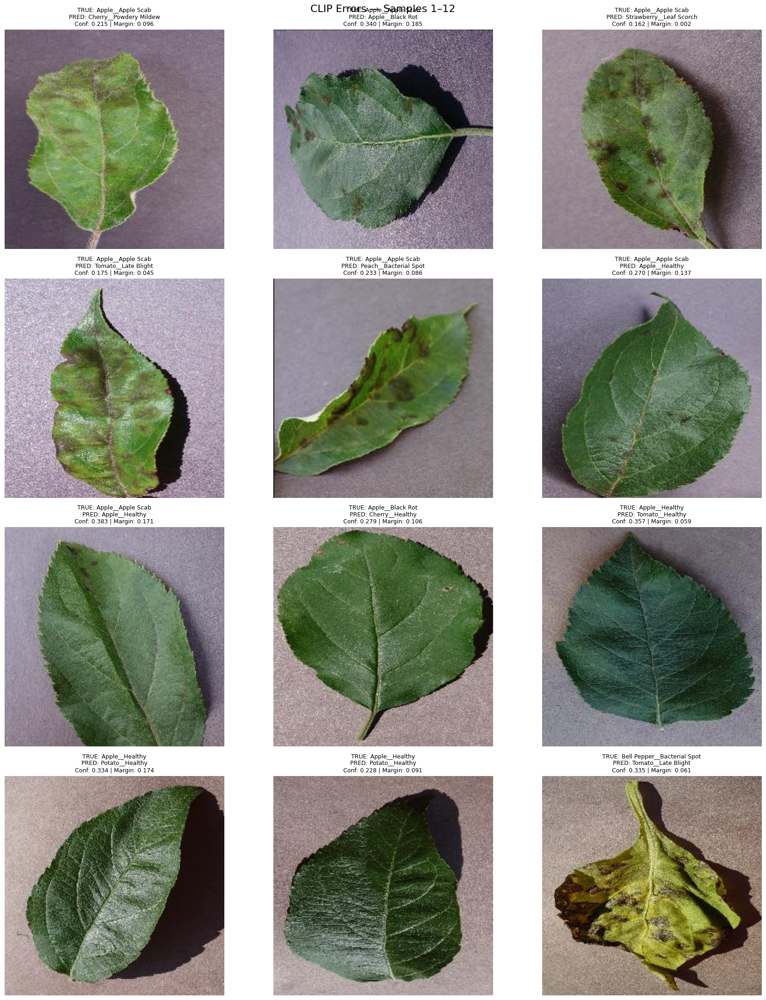

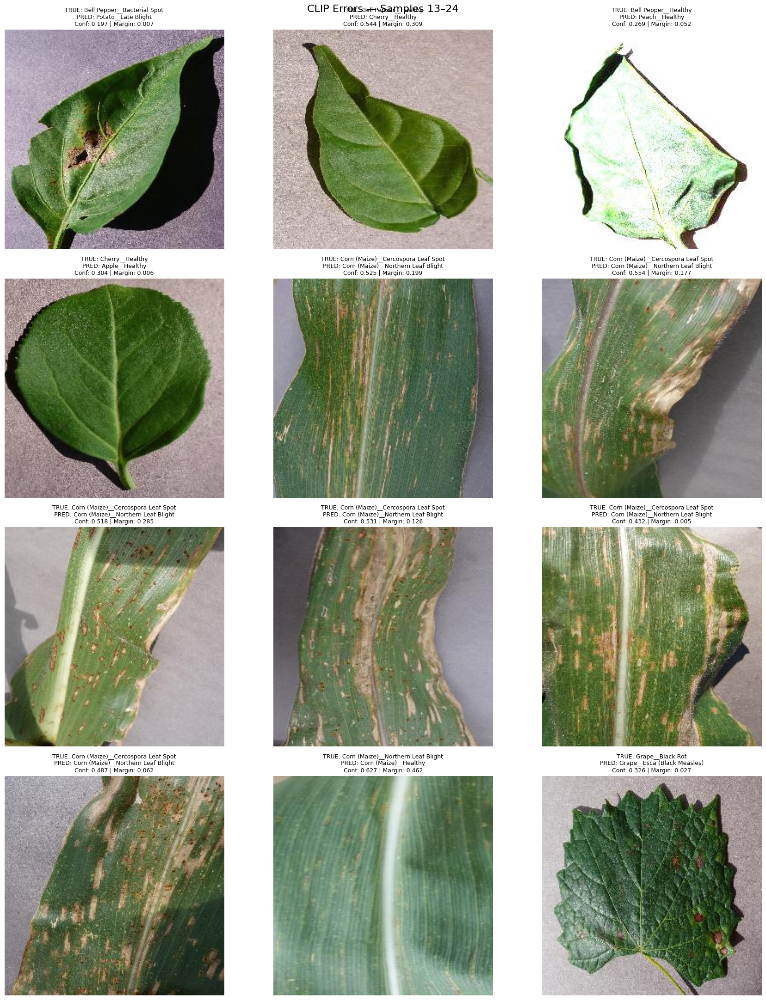

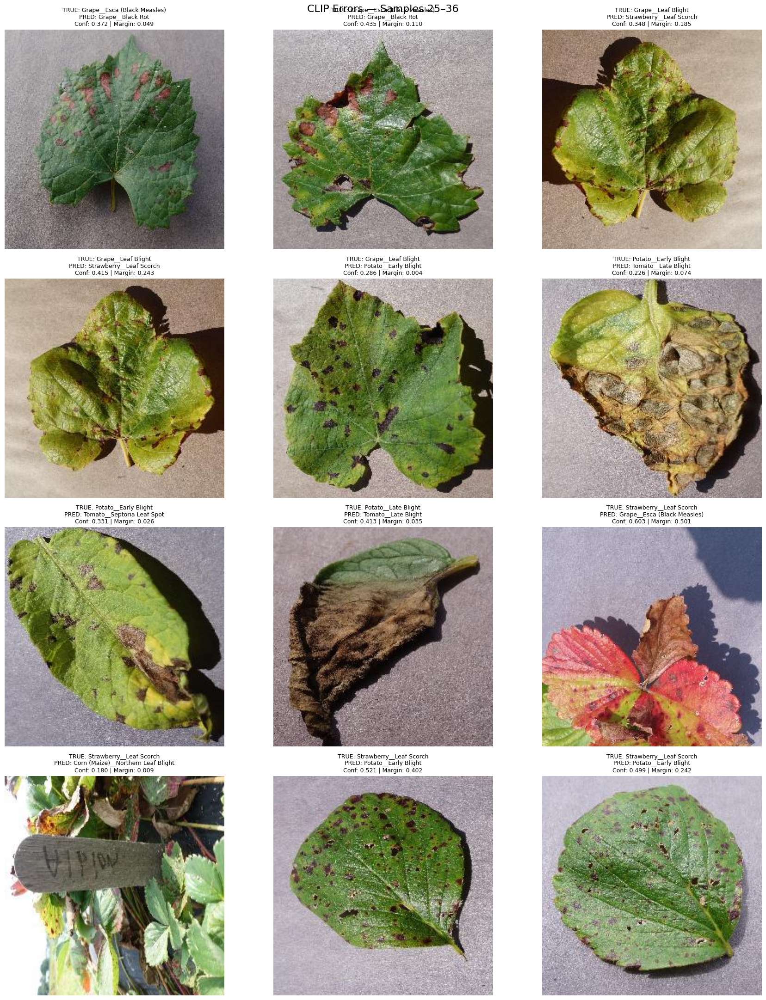

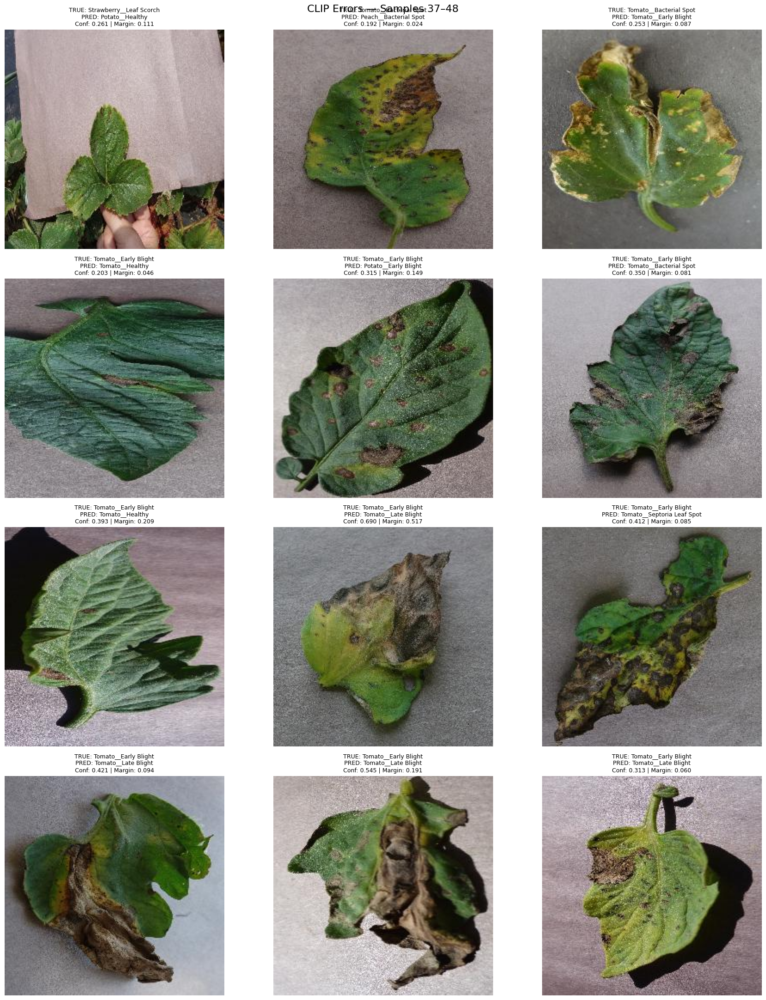

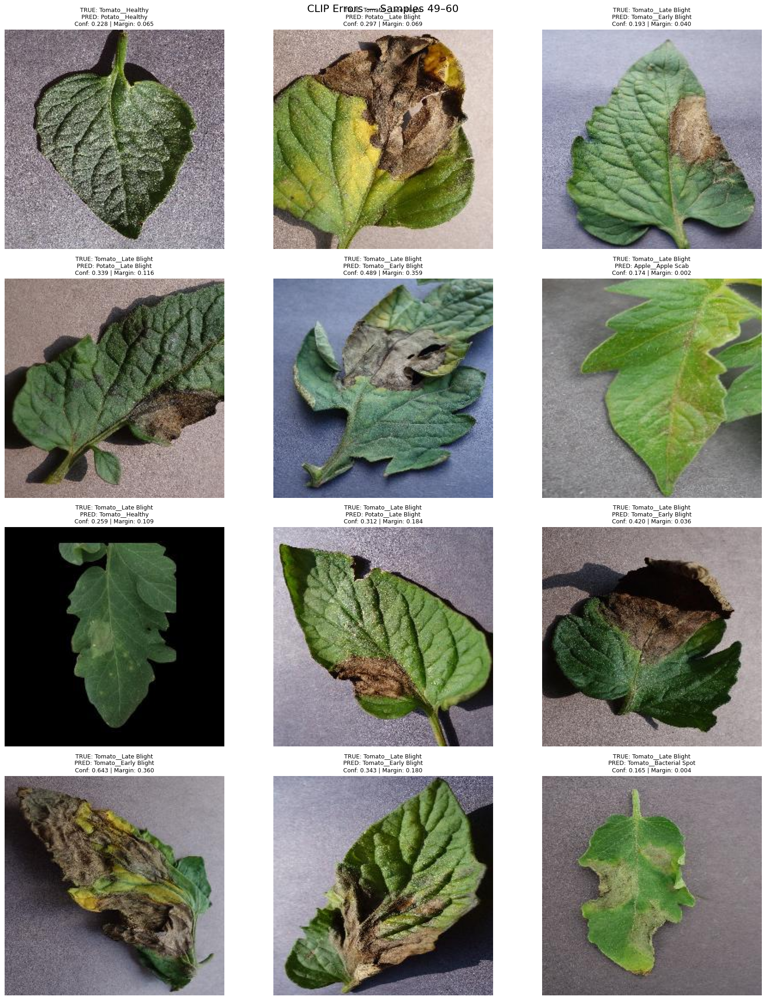

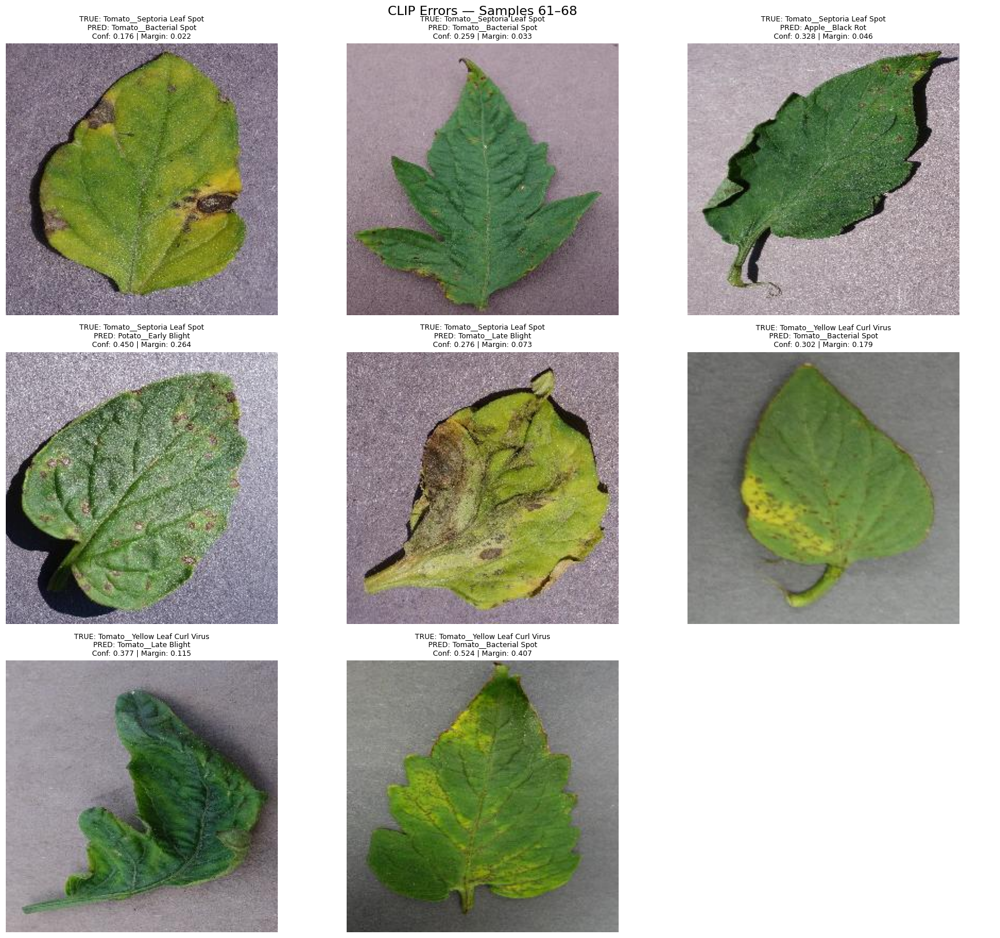


[3] IMPORTANT CONFUSION GROUPS
------------------------------------------------------------
Tomato Early ↔ Late Blight errors : 9


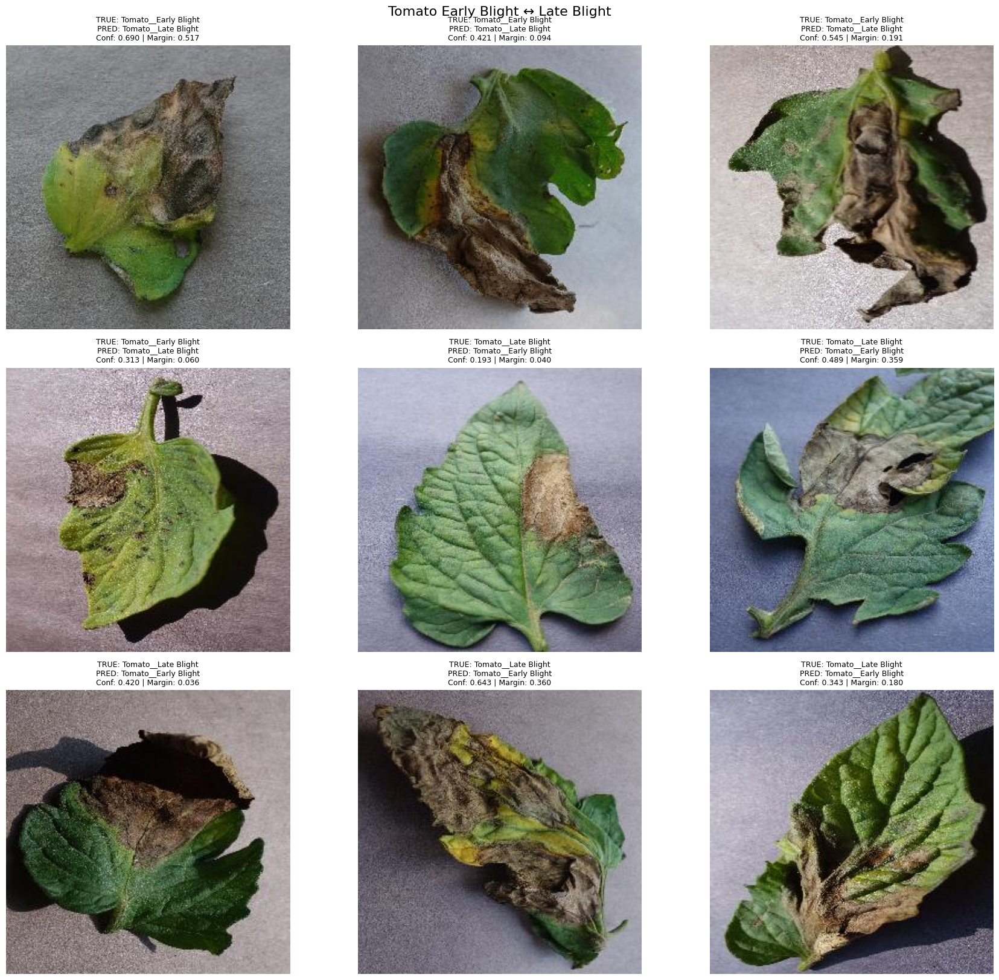

Corn Cercospora → Northern Leaf Blight : 6


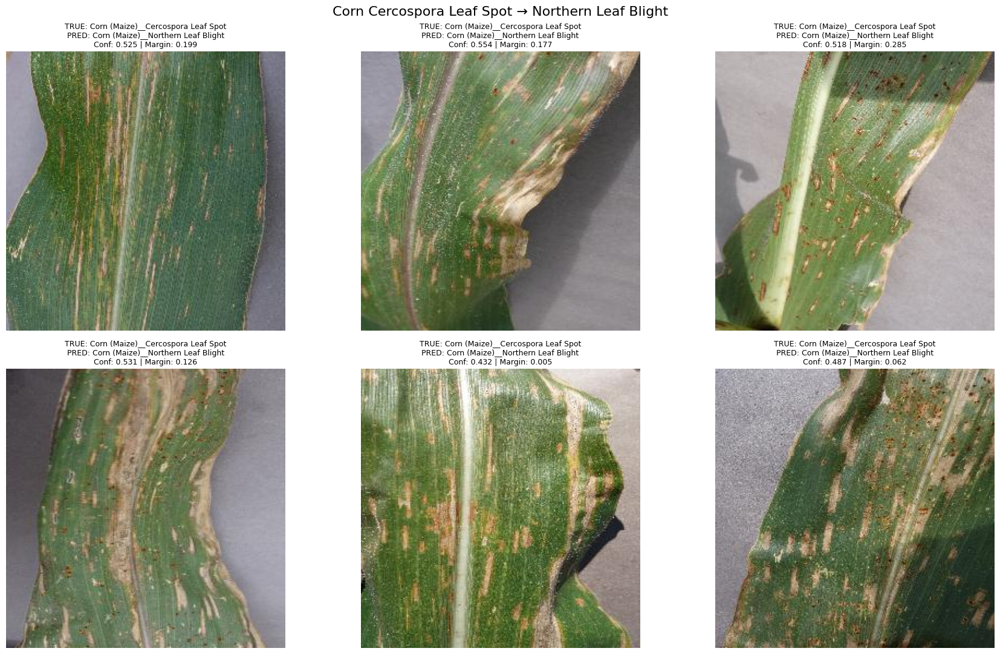

Tomato Late → Potato Late errors : 3


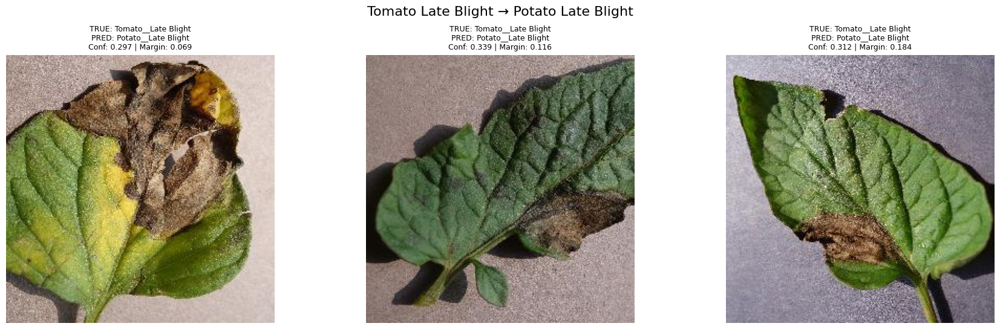

Grape Esca ↔ Black Rot errors : 3


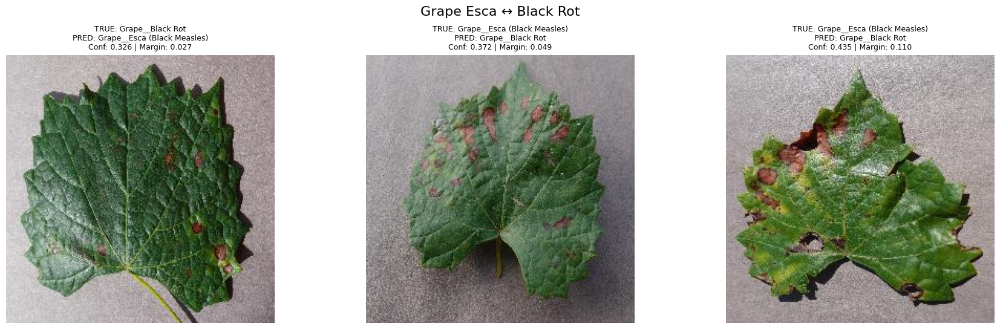


[4] HIGHEST-CONFIDENCE ERRORS
------------------------------------------------------------


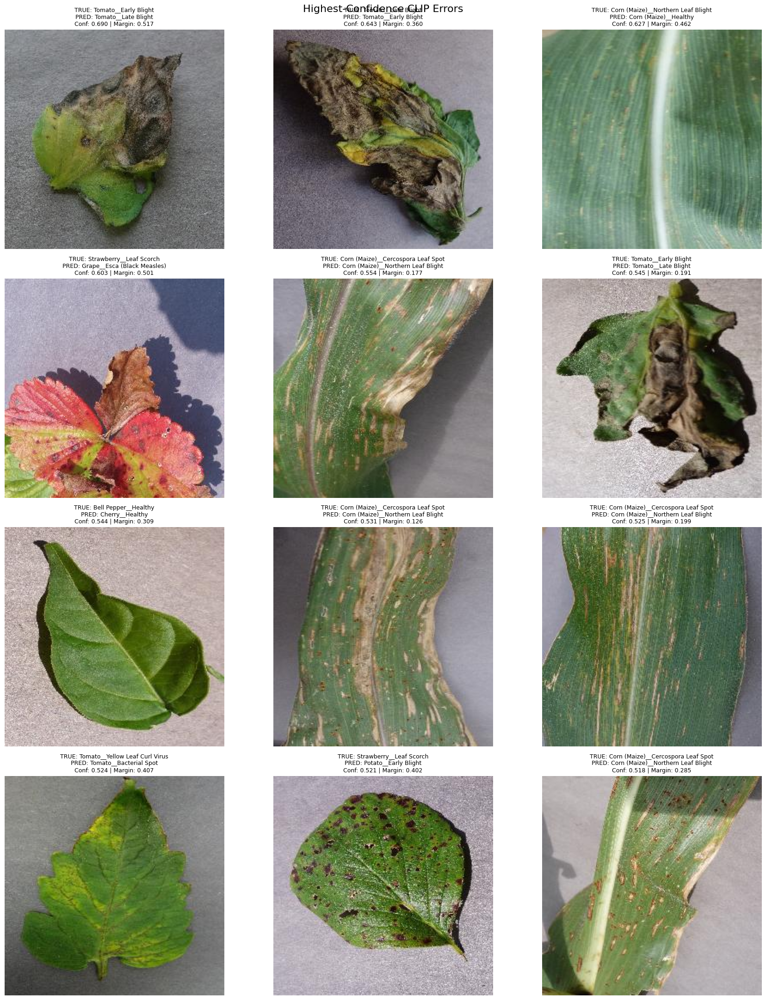


[5] MOST AMBIGUOUS ERRORS
------------------------------------------------------------


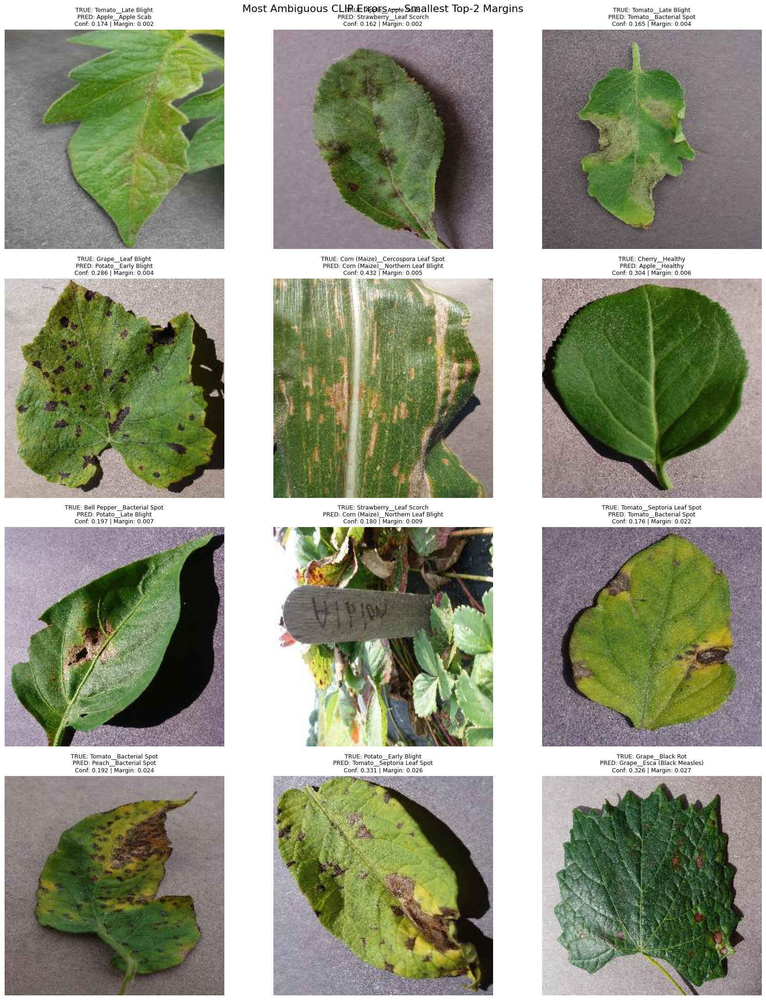


[6] FILENAME / TRANSFORMATION ANALYSIS
------------------------------------------------------------


,pattern,error_count,error_percentage
0,flipLR,11,16.18%
3,180deg,7,10.29%
1,flipTB,4,5.88%
5,copy,3,4.41%
2,90deg,1,1.47%
4,270deg,1,1.47%
6,newPixel,1,1.47%



[7] INTEGRITY CHECKS
------------------------------------------------------------
✓ All 68 error records available
✓ All true/predicted labels verified
✓ All 68 image files exist
✓ No training performed
✓ No model parameters changed
✓ No test labels used for model modification

CELL-17 COMPLETE


In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 17
# Visual Inspection of CLIP Errors
# ======================================================================

import os
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 17")
print("Visual Inspection of Misclassified Samples")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Verify required objects
# ----------------------------------------------------------------------

required_objects = [
    "errors_top5_df",
    "errors_df",
    "test_manifest"
]

for obj_name in required_objects:
    assert obj_name in globals(), (
        f"{obj_name} is missing. "
        "Run Cell 15 and Cell 16 first."
    )

assert len(errors_top5_df) == 68

print("\n[1] Error dataset verified")
print("-" * 60)
print(f"Total errors available : {len(errors_top5_df)}")

# ----------------------------------------------------------------------
# 2. Identify path column
# ----------------------------------------------------------------------

assert "path" in errors_top5_df.columns

# ----------------------------------------------------------------------
# 3. Image inspection helper
# ----------------------------------------------------------------------

def show_error_batch(
    df,
    title,
    start=0,
    batch_size=12
):
    """
    Display a batch of misclassified images with:
    - true class
    - predicted class
    - confidence
    - top-2 margin
    """

    batch = df.iloc[
        start:start + batch_size
    ].reset_index(drop=True)

    if len(batch) == 0:
        print("No images available for this batch.")
        return

    cols = 3
    rows = math.ceil(len(batch) / cols)

    fig, axes = plt.subplots(
        rows,
        cols,
        figsize=(18, 5.5 * rows)
    )

    axes = np.array(axes).reshape(-1)

    for i, (_, row) in enumerate(batch.iterrows()):

        ax = axes[i]

        image_path = row["path"]

        try:
            image = Image.open(
                image_path
            ).convert("RGB")

            ax.imshow(image)

        except Exception as e:

            ax.text(
                0.5,
                0.5,
                f"Image load failed\n{e}",
                ha="center",
                va="center"
            )

        true_class = str(
            row["true_class"]
        )

        predicted_class = str(
            row["predicted_class"]
        )

        confidence = float(
            row["top1_confidence"]
        )

        margin = float(
            row["confidence_margin"]
        )

        ax.set_title(
            f"TRUE: {true_class}\n"
            f"PRED: {predicted_class}\n"
            f"Conf: {confidence:.3f} | "
            f"Margin: {margin:.3f}",
            fontsize=9
        )

        ax.axis("off")

    # Hide unused axes
    for j in range(
        len(batch),
        len(axes)
    ):
        axes[j].axis("off")

    fig.suptitle(
        title,
        fontsize=16
    )

    plt.tight_layout()
    plt.show()


# ----------------------------------------------------------------------
# 4. All errors — batches 1 through 6
# ----------------------------------------------------------------------

print("\n[2] ALL 68 ERRORS")
print("-" * 60)

show_error_batch(
    errors_top5_df,
    "CLIP Errors — Samples 1–12",
    start=0,
    batch_size=12
)

show_error_batch(
    errors_top5_df,
    "CLIP Errors — Samples 13–24",
    start=12,
    batch_size=12
)

show_error_batch(
    errors_top5_df,
    "CLIP Errors — Samples 25–36",
    start=24,
    batch_size=12
)

show_error_batch(
    errors_top5_df,
    "CLIP Errors — Samples 37–48",
    start=36,
    batch_size=12
)

show_error_batch(
    errors_top5_df,
    "CLIP Errors — Samples 49–60",
    start=48,
    batch_size=12
)

show_error_batch(
    errors_top5_df,
    "CLIP Errors — Samples 61–68",
    start=60,
    batch_size=12
)

# ----------------------------------------------------------------------
# 5. Important confusion groups
# ----------------------------------------------------------------------

print("\n[3] IMPORTANT CONFUSION GROUPS")
print("-" * 60)

# Group 1: Tomato Early ↔ Late Blight
tomato_early_late = errors_top5_df[
    (
        (
            errors_top5_df["true_class"]
            == "Tomato__Early Blight"
        )
        &
        (
            errors_top5_df["predicted_class"]
            == "Tomato__Late Blight"
        )
    )
    |
    (
        (
            errors_top5_df["true_class"]
            == "Tomato__Late Blight"
        )
        &
        (
            errors_top5_df["predicted_class"]
            == "Tomato__Early Blight"
        )
    )
].copy()

print(
    f"Tomato Early ↔ Late Blight errors : "
    f"{len(tomato_early_late)}"
)

show_error_batch(
    tomato_early_late,
    "Tomato Early Blight ↔ Late Blight",
    start=0,
    batch_size=12
)

# ----------------------------------------------------------------------

# Group 2: Corn Cercospora → Northern Leaf Blight
corn_confusion = errors_top5_df[
    (
        errors_top5_df["true_class"]
        == "Corn (Maize)__Cercospora Leaf Spot"
    )
    &
    (
        errors_top5_df["predicted_class"]
        == "Corn (Maize)__Northern Leaf Blight"
    )
].copy()

print(
    f"Corn Cercospora → Northern Leaf Blight : "
    f"{len(corn_confusion)}"
)

show_error_batch(
    corn_confusion,
    "Corn Cercospora Leaf Spot → Northern Leaf Blight",
    start=0,
    batch_size=12
)

# ----------------------------------------------------------------------

# Group 3: Tomato Late → Potato Late
tomato_potato_late = errors_top5_df[
    (
        errors_top5_df["true_class"]
        == "Tomato__Late Blight"
    )
    &
    (
        errors_top5_df["predicted_class"]
        == "Potato__Late Blight"
    )
].copy()

print(
    f"Tomato Late → Potato Late errors : "
    f"{len(tomato_potato_late)}"
)

show_error_batch(
    tomato_potato_late,
    "Tomato Late Blight → Potato Late Blight",
    start=0,
    batch_size=12
)

# ----------------------------------------------------------------------

# Group 4: Grape Esca ↔ Black Rot
grape_confusion = errors_top5_df[
    (
        (
            errors_top5_df["true_class"]
            == "Grape__Esca (Black Measles)"
        )
        &
        (
            errors_top5_df["predicted_class"]
            == "Grape__Black Rot"
        )
    )
    |
    (
        (
            errors_top5_df["true_class"]
            == "Grape__Black Rot"
        )
        &
        (
            errors_top5_df["predicted_class"]
            == "Grape__Esca (Black Measles)"
        )
    )
].copy()

print(
    f"Grape Esca ↔ Black Rot errors : "
    f"{len(grape_confusion)}"
)

show_error_batch(
    grape_confusion,
    "Grape Esca ↔ Black Rot",
    start=0,
    batch_size=12
)

# ----------------------------------------------------------------------
# 6. Highest-confidence errors
# ----------------------------------------------------------------------

print("\n[4] HIGHEST-CONFIDENCE ERRORS")
print("-" * 60)

highest_confidence = (
    errors_top5_df
    .sort_values(
        "top1_confidence",
        ascending=False
    )
    .head(12)
    .copy()
)

show_error_batch(
    highest_confidence,
    "Highest-Confidence CLIP Errors",
    start=0,
    batch_size=12
)

# ----------------------------------------------------------------------
# 7. Most ambiguous errors
# ----------------------------------------------------------------------

print("\n[5] MOST AMBIGUOUS ERRORS")
print("-" * 60)

most_ambiguous = (
    errors_top5_df
    .sort_values(
        "confidence_margin",
        ascending=True
    )
    .head(12)
    .copy()
)

show_error_batch(
    most_ambiguous,
    "Most Ambiguous CLIP Errors — Smallest Top-2 Margins",
    start=0,
    batch_size=12
)

# ----------------------------------------------------------------------
# 8. Filename transformation analysis
# ----------------------------------------------------------------------

print("\n[6] FILENAME / TRANSFORMATION ANALYSIS")
print("-" * 60)

path_lower = (
    errors_top5_df["path"]
    .astype(str)
    .str.lower()
)

transformation_patterns = {
    "flipLR": "fliplr",
    "flipTB": "fliptb",
    "90deg": "90deg",
    "180deg": "180deg",
    "270deg": "270deg",
    "copy": "copy",
    "newPixel": "newpixel"
}

transformation_counts = []

for name, pattern in transformation_patterns.items():

    count = int(
        path_lower.str.contains(
            pattern,
            regex=False
        ).sum()
    )

    transformation_counts.append({
        "pattern": name,
        "error_count": count,
        "error_percentage": (
            count / len(errors_top5_df)
        )
    })

transformation_df = pd.DataFrame(
    transformation_counts
).sort_values(
    "error_count",
    ascending=False
)

display(
    transformation_df.style.format({
        "error_percentage": "{:.2%}"
    })
)

# ----------------------------------------------------------------------
# 9. Integrity checks
# ----------------------------------------------------------------------

print("\n[7] INTEGRITY CHECKS")
print("-" * 60)

assert len(errors_top5_df) == 68

assert (
    errors_top5_df["true_class"]
    !=
    errors_top5_df["predicted_class"]
).all()

assert all(
    os.path.exists(path)
    for path in errors_top5_df["path"]
)

print("✓ All 68 error records available")
print("✓ All true/predicted labels verified")
print("✓ All 68 image files exist")
print("✓ No training performed")
print("✓ No model parameters changed")
print("✓ No test labels used for model modification")

print("\n" + "=" * 70)
print("CELL-17 COMPLETE")
print("=" * 70)

**CELL 18: Transformation vs Classification Error Analysis**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 18
# Transformation vs Classification Error Analysis
# ======================================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 18")
print("Transformation vs Classification Error Analysis")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Verify required objects
# ----------------------------------------------------------------------

assert "errors_top5_df" in globals(), \
    "errors_top5_df is missing. Run Cell 15 first."

assert "test_manifest" in globals(), \
    "test_manifest is missing. Run Cell 15 first."

# ----------------------------------------------------------------------
# 2. Build complete test prediction dataframe
# ----------------------------------------------------------------------
#
# Cell 15 already produced errors_top5_df.
# We need all test samples, including correct predictions.
#
# Use the prediction arrays generated during Cell 13/15 if available.
# ----------------------------------------------------------------------

candidate_true = [
    "test_labels",
    "test_true_labels",
    "y_test",
    "all_test_labels"
]

candidate_pred = [
    "test_preds",
    "test_predictions",
    "y_pred",
    "all_test_preds"
]

true_var = next(
    (x for x in candidate_true if x in globals()),
    None
)

pred_var = next(
    (x for x in candidate_pred if x in globals()),
    None
)

print("\n[1] Prediction objects")

print("-" * 60)

print("True-label variable :", true_var)
print("Prediction variable :", pred_var)

# ----------------------------------------------------------------------
# 3. Robust fallback: reconstruct correctness using Cell-15 errors
# ----------------------------------------------------------------------

test_df = test_manifest.copy()

assert len(test_df) == 1354

# Every error path from Cell 15 is known.
error_paths = set(
    errors_top5_df["path"].astype(str)
)

test_df["path"] = (
    test_df["path"]
    .astype(str)
)

test_df["is_error"] = (
    test_df["path"]
    .isin(error_paths)
)

test_df["is_correct"] = (
    ~test_df["is_error"]
)

print("\n[2] Test prediction integrity")
print("-" * 60)

print(
    f"Test samples       : {len(test_df)}"
)

print(
    f"Errors             : {test_df['is_error'].sum()}"
)

print(
    f"Correct predictions: {test_df['is_correct'].sum()}"
)

assert test_df["is_error"].sum() == 68
assert test_df["is_correct"].sum() == 1286

# ----------------------------------------------------------------------
# 4. Detect filename transformation markers
# ----------------------------------------------------------------------

path_lower = (
    test_df["path"]
    .astype(str)
    .str.lower()
)

patterns = {
    "flipLR": "fliplr",
    "flipTB": "fliptb",
    "90deg": "90deg",
    "180deg": "180deg",
    "270deg": "270deg",
    "copy": "copy",
    "newPixel": "newpixel"
}

for name, pattern in patterns.items():

    test_df[f"has_{name}"] = (
        path_lower.str.contains(
            pattern,
            regex=False
        )
    )

# Any recognized transformation
transformation_columns = [
    f"has_{name}"
    for name in patterns
]

test_df["has_transformation"] = (
    test_df[transformation_columns]
    .any(axis=1)
)

# ----------------------------------------------------------------------
# 5. Overall comparison
# ----------------------------------------------------------------------

print("\n[3] TRANSFORMATION VS ERROR")
print("-" * 60)

summary_rows = []

for group_name, group_df in [
    ("All test samples", test_df),
    ("Correct predictions", test_df[test_df["is_correct"]]),
    ("Errors", test_df[test_df["is_error"]])
]:

    n = len(group_df)

    transformed = int(
        group_df["has_transformation"].sum()
    )

    summary_rows.append({
        "group": group_name,
        "samples": n,
        "with_transformation": transformed,
        "transformation_rate": (
            transformed / n
            if n > 0 else np.nan
        )
    })

summary_df = pd.DataFrame(summary_rows)

display(
    summary_df.style.format({
        "transformation_rate": "{:.2%}"
    })
)

# ----------------------------------------------------------------------
# 6. Each transformation separately
# ----------------------------------------------------------------------

print("\n[4] INDIVIDUAL TRANSFORMATION TYPES")
print("-" * 60)

rows = []

for name in patterns:

    col = f"has_{name}"

    total = int(
        test_df[col].sum()
    )

    errors = int(
        (
            test_df[col]
            &
            test_df["is_error"]
        ).sum()
    )

    correct = int(
        (
            test_df[col]
            &
            test_df["is_correct"]
        ).sum()
    )

    error_rate = (
        errors / total
        if total > 0 else np.nan
    )

    rows.append({
        "transformation": name,
        "total_test_images": total,
        "errors": errors,
        "correct": correct,
        "error_rate": error_rate
    })

transformation_df = (
    pd.DataFrame(rows)
    .sort_values(
        "error_rate",
        ascending=False
    )
)

display(
    transformation_df.style.format({
        "error_rate": "{:.2%}"
    })
)

# ----------------------------------------------------------------------
# 7. Error-rate comparison
# ----------------------------------------------------------------------

transformed = test_df[
    test_df["has_transformation"]
]

non_transformed = test_df[
    ~test_df["has_transformation"]
]

transformed_error_rate = (
    transformed["is_error"].mean()
)

non_transformed_error_rate = (
    non_transformed["is_error"].mean()
)

print("\n[5] ERROR-RATE COMPARISON")
print("-" * 60)

print(
    f"Transformed images     : {len(transformed)}"
)

print(
    f"Transformed errors     : "
    f"{int(transformed['is_error'].sum())}"
)

print(
    f"Transformed error rate : "
    f"{transformed_error_rate:.2%}"
)

print()

print(
    f"Non-transformed images     : "
    f"{len(non_transformed)}"
)

print(
    f"Non-transformed errors     : "
    f"{int(non_transformed['is_error'].sum())}"
)

print(
    f"Non-transformed error rate : "
    f"{non_transformed_error_rate:.2%}"
)

if non_transformed_error_rate > 0:

    relative_ratio = (
        transformed_error_rate
        /
        non_transformed_error_rate
    )

    print()
    print(
        f"Relative error-rate ratio : "
        f"{relative_ratio:.2f}x"
    )

# ----------------------------------------------------------------------
# 8. Transformation contribution to all errors
# ----------------------------------------------------------------------

print("\n[6] CONTRIBUTION TO ALL 68 ERRORS")
print("-" * 60)

transformation_error_count = int(
    transformed["is_error"].sum()
)

print(
    f"Errors with transformation marker : "
    f"{transformation_error_count}/68 "
    f"({transformation_error_count / 68:.2%})"
)

print(
    f"Errors without transformation marker: "
    f"{68 - transformation_error_count}/68 "
    f"({(68 - transformation_error_count) / 68:.2%})"
)

# ----------------------------------------------------------------------
# 9. Important caution
# ----------------------------------------------------------------------

print("\n[7] INTERPRETATION RULE")
print("-" * 60)

print(
    "A high transformation error rate does NOT by itself prove "
    "that augmentation/transformation causes CLIP errors."
)

print(
    "The key comparison is transformed-error-rate vs "
    "non-transformed-error-rate."
)

print(
    "If the rates are similar, transformation markers are unlikely "
    "to be a major error driver."
)

print(
    "If transformed images have substantially higher error rates, "
    "we should investigate orientation/augmentation robustness."
)

print("\n" + "=" * 70)
print("CELL-18 COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 18
Transformation vs Classification Error Analysis

[1] Prediction objects
------------------------------------------------------------
True-label variable : None
Prediction variable : None

[2] Test prediction integrity
------------------------------------------------------------
Test samples       : 1354
Errors             : 68
Correct predictions: 1286

[3] TRANSFORMATION VS ERROR
------------------------------------------------------------


,group,samples,with_transformation,transformation_rate
0,All test samples,1354,707,52.22%
1,Correct predictions,1286,680,52.88%
2,Errors,68,27,39.71%



[4] INDIVIDUAL TRANSFORMATION TYPES
------------------------------------------------------------


,transformation,total_test_images,errors,correct,error_rate
5,copy,58,3,55,5.17%
3,180deg,137,7,130,5.11%
6,newPixel,21,1,20,4.76%
0,flipLR,262,11,251,4.20%
1,flipTB,128,4,124,3.12%
4,270deg,65,1,64,1.54%
2,90deg,75,1,74,1.33%



[5] ERROR-RATE COMPARISON
------------------------------------------------------------
Transformed images     : 707
Transformed errors     : 27
Transformed error rate : 3.82%

Non-transformed images     : 647
Non-transformed errors     : 41
Non-transformed error rate : 6.34%

Relative error-rate ratio : 0.60x

[6] CONTRIBUTION TO ALL 68 ERRORS
------------------------------------------------------------
Errors with transformation marker : 27/68 (39.71%)
Errors without transformation marker: 41/68 (60.29%)

[7] INTERPRETATION RULE
------------------------------------------------------------
A high transformation error rate does NOT by itself prove that augmentation/transformation causes CLIP errors.
The key comparison is transformed-error-rate vs non-transformed-error-rate.
If the rates are similar, transformation markers are unlikely to be a major error driver.
If transformed images have substantially higher error rates, we should investigate orientation/augmentation robustness.

CELL

**CELL 19: Frozen CLIP Representation Separability Analysis**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 19
# Frozen CLIP Representation Separability Analysis
# ======================================================================

import os
import gc
import time
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 19")
print("Frozen CLIP Representation Separability Analysis")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Verify required objects
# ----------------------------------------------------------------------

assert "model" in globals(), \
    "CLIP model is missing. Run Cell 1 first."

assert "processor" in globals(), \
    "CLIP processor is missing. Run Cell 1 first."

assert "test_manifest" in globals(), \
    "test_manifest is missing. Run Cell 15 first."

assert "errors_top5_df" in globals(), \
    "errors_top5_df is missing. Run Cell 15 first."

assert "classifier" in globals(), \
    "Classifier is missing. Run Cell 11/12 first."

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model.eval()
classifier.eval()

# ----------------------------------------------------------------------
# 2. Dataset
# ----------------------------------------------------------------------

test_dataset = test_manifest.copy()

print("\n[1] Test set")
print("-" * 60)
print(f"Test samples : {len(test_dataset)}")
print(f"Classes      : {test_dataset['class_idx'].nunique()}")

assert len(test_dataset) == 1354
assert test_dataset["class_idx"].nunique() == 29

# ----------------------------------------------------------------------
# 3. Dataset class
# ----------------------------------------------------------------------

class CLIPTestDataset(torch.utils.data.Dataset):

    def __init__(self, dataframe, processor):
        self.df = dataframe.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["path"]
        ).convert("RGB")

        processed = self.processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = processed[
            "pixel_values"
        ].squeeze(0)

        label = int(
            row["class_idx"]
        )

        return pixel_values, label


# ----------------------------------------------------------------------
# 4. Import PIL explicitly
# ----------------------------------------------------------------------

from PIL import Image

dataset = CLIPTestDataset(
    test_dataset,
    processor
)

loader = DataLoader(
    dataset,
    batch_size=64,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\n[2] DataLoader")
print("-" * 60)
print(f"Batch size : {loader.batch_size}")
print(f"Batches    : {len(loader)}")

# ----------------------------------------------------------------------
# 5. Extract frozen CLIP embeddings
# ----------------------------------------------------------------------

@torch.inference_mode()
def get_clip_embeddings(pixel_values):

    vision_outputs = model.vision_model(
        pixel_values=pixel_values
    )

    pooled = vision_outputs.pooler_output

    embeddings = model.visual_projection(
        pooled
    )

    embeddings = F.normalize(
        embeddings,
        p=2,
        dim=-1
    )

    return embeddings


print("\n[3] Extracting CLIP embeddings...")
print("-" * 60)

all_embeddings = []
all_labels = []

start_time = time.time()

for batch_idx, (pixel_values, labels) in enumerate(loader):

    pixel_values = pixel_values.to(
        device,
        non_blocking=True
    )

    embeddings = get_clip_embeddings(
        pixel_values
    )

    all_embeddings.append(
        embeddings.cpu()
    )

    all_labels.append(
        labels
    )

elapsed = time.time() - start_time

embeddings = torch.cat(
    all_embeddings,
    dim=0
)

labels = torch.cat(
    all_labels,
    dim=0
)

print(
    f"Embedding shape : {tuple(embeddings.shape)}"
)

print(
    f"Embedding dtype : {embeddings.dtype}"
)

print(
    f"Extraction time : {elapsed:.2f} sec"
)

# ----------------------------------------------------------------------
# 6. Verify normalization
# ----------------------------------------------------------------------

norms = torch.norm(
    embeddings,
    dim=1
)

print("\n[4] Embedding integrity")
print("-" * 60)

print(
    f"Minimum L2 norm : {norms.min().item():.6f}"
)

print(
    f"Maximum L2 norm : {norms.max().item():.6f}"
)

assert embeddings.shape == (
    1354,
    512
)

assert torch.allclose(
    norms,
    torch.ones_like(norms),
    atol=1e-5
)

print("✓ All embeddings are L2-normalized")

# ----------------------------------------------------------------------
# 7. Build class centroids
# ----------------------------------------------------------------------

num_classes = 29

centroids = []

for class_idx in range(num_classes):

    class_embeddings = embeddings[
        labels == class_idx
    ]

    centroid = class_embeddings.mean(
        dim=0
    )

    centroid = F.normalize(
        centroid,
        p=2,
        dim=0
    )

    centroids.append(
        centroid
    )

centroids = torch.stack(
    centroids
)

print("\n[5] Class centroids")
print("-" * 60)

print(
    f"Centroid shape : {tuple(centroids.shape)}"
)

# ----------------------------------------------------------------------
# 8. Centroid similarity matrix
# ----------------------------------------------------------------------

centroid_similarity = (
    centroids @ centroids.T
)

# Remove diagonal when finding most similar classes
similarity_for_search = (
    centroid_similarity.clone()
)

similarity_for_search.fill_diagonal_(
    -1
)

top_pairs = []

for class_idx in range(num_classes):

    best_idx = torch.argmax(
        similarity_for_search[class_idx]
    ).item()

    score = (
        centroid_similarity[
            class_idx,
            best_idx
        ].item()
    )

    top_pairs.append({
        "class_idx": class_idx,
        "nearest_class_idx": best_idx,
        "cosine_similarity": score
    })

pairs_df = pd.DataFrame(
    top_pairs
)

# Keep unique pairs
unique_pairs = []

seen = set()

for _, row in pairs_df.sort_values(
    "cosine_similarity",
    ascending=False
).iterrows():

    a = int(row["class_idx"])
    b = int(row["nearest_class_idx"])

    pair = tuple(
        sorted((a, b))
    )

    if pair not in seen:

        seen.add(pair)

        unique_pairs.append({
            "class_a": pair[0],
            "class_b": pair[1],
            "cosine_similarity": row[
                "cosine_similarity"
            ]
        })

top_pairs_df = pd.DataFrame(
    unique_pairs
).head(20)

# Map class names
class_mapping = (
    test_dataset[
        ["class_idx", "class_name"]
    ]
    .drop_duplicates()
    .sort_values("class_idx")
)

class_name_map = dict(
    zip(
        class_mapping["class_idx"],
        class_mapping["class_name"]
    )
)

top_pairs_df["class_a_name"] = (
    top_pairs_df["class_a"]
    .map(class_name_map)
)

top_pairs_df["class_b_name"] = (
    top_pairs_df["class_b"]
    .map(class_name_map)
)

print("\n[6] Most similar CLIP class centroids")
print("-" * 60)

display(
    top_pairs_df[
        [
            "class_a",
            "class_a_name",
            "class_b",
            "class_b_name",
            "cosine_similarity"
        ]
    ].style.format({
        "cosine_similarity": "{:.4f}"
    })
)

# ----------------------------------------------------------------------
# 9. Focus on known difficult disease pairs
# ----------------------------------------------------------------------

important_pairs = [
    (
        "Tomato__Early Blight",
        "Tomato__Late Blight"
    ),
    (
        "Corn (Maize)__Cercospora Leaf Spot",
        "Corn (Maize)__Northern Leaf Blight"
    ),
    (
        "Tomato__Late Blight",
        "Potato__Late Blight"
    ),
    (
        "Grape__Esca (Black Measles)",
        "Grape__Black Rot"
    ),
    (
        "Strawberry__Leaf Scorch",
        "Potato__Early Blight"
    ),
    (
        "Tomato__Septoria Leaf Spot",
        "Tomato__Bacterial Spot"
    )
]

name_to_idx = {
    name: idx
    for idx, name in class_name_map.items()
}

important_rows = []

for class_a_name, class_b_name in important_pairs:

    a = name_to_idx[class_a_name]
    b = name_to_idx[class_b_name]

    similarity = (
        centroid_similarity[a, b]
        .item()
    )

    important_rows.append({
        "class_a": class_a_name,
        "class_b": class_b_name,
        "centroid_cosine_similarity": similarity
    })

important_df = pd.DataFrame(
    important_rows
).sort_values(
    "centroid_cosine_similarity",
    ascending=False
)

print("\n[7] Known difficult pairs")
print("-" * 60)

display(
    important_df.style.format({
        "centroid_cosine_similarity": "{:.4f}"
    })
)

# ----------------------------------------------------------------------
# 10. Nearest-centroid classification
# ----------------------------------------------------------------------

nearest_centroid_scores = (
    embeddings @ centroids.T
)

nearest_centroid_predictions = (
    nearest_centroid_scores.argmax(
        dim=1
    )
)

centroid_accuracy = (
    nearest_centroid_predictions
    == labels
).float().mean().item()

print("\n[8] Nearest-centroid diagnostic")
print("-" * 60)

print(
    f"Nearest-centroid accuracy : "
    f"{centroid_accuracy:.4%}"
)

print(
    "This is a diagnostic only; "
    "the classifier was NOT modified."
)

# ----------------------------------------------------------------------
# 11. Clean memory
# ----------------------------------------------------------------------

del all_embeddings
del all_labels

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("CELL-19 COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 19
Frozen CLIP Representation Separability Analysis

[1] Test set
------------------------------------------------------------
Test samples : 1354
Classes      : 29

[2] DataLoader
------------------------------------------------------------
Batch size : 64
Batches    : 22

[3] Extracting CLIP embeddings...
------------------------------------------------------------
Embedding shape : (1354, 512)
Embedding dtype : torch.float32
Extraction time : 8.99 sec

[4] Embedding integrity
------------------------------------------------------------
Minimum L2 norm : 1.000000
Maximum L2 norm : 1.000000
✓ All embeddings are L2-normalized

[5] Class centroids
------------------------------------------------------------
Centroid shape : (29, 512)

[6] Most similar CLIP class centroids
------------------------------------------------------------


,class_a,class_a_name,class_b,class_b_name,cosine_similarity
0,24,Tomato__Early Blight,26,Tomato__Late Blight,0.9905
1,24,Tomato__Early Blight,27,Tomato__Septoria Leaf Spot,0.9882
2,0,Apple__Apple Scab,23,Tomato__Bacterial Spot,0.9850
3,0,Apple__Apple Scab,2,Apple__Cedar Apple Rust,0.9828
4,12,Grape__Black Rot,13,Grape__Esca (Black Measles),0.9827
5,18,Potato__Early Blight,20,Potato__Late Blight,0.9822
6,3,Apple__Healthy,25,Tomato__Healthy,0.9810
7,8,Corn (Maize)__Cercospora Leaf Spot,11,Corn (Maize)__Northern Leaf Blight,0.9803
8,0,Apple__Apple Scab,7,Cherry__Powdery Mildew,0.9802
9,0,Apple__Apple Scab,1,Apple__Black Rot,0.9794



[7] Known difficult pairs
------------------------------------------------------------


,class_a,class_b,centroid_cosine_similarity
0,Tomato__Early Blight,Tomato__Late Blight,0.9905
5,Tomato__Septoria Leaf Spot,Tomato__Bacterial Spot,0.9834
3,Grape__Esca (Black Measles),Grape__Black Rot,0.9827
1,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.9803
2,Tomato__Late Blight,Potato__Late Blight,0.9790
4,Strawberry__Leaf Scorch,Potato__Early Blight,0.9642



[8] Nearest-centroid diagnostic
------------------------------------------------------------
Nearest-centroid accuracy : 86.7799%
This is a diagnostic only; the classifier was NOT modified.

CELL-19 COMPLETE


**Cell 20 — compare CLIP against DINOv2 at the representation level**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 20
# DINOv2 Artifact Availability Check
# ======================================================================

import os
import glob
import torch

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 20")
print("DINOv2 Artifact Availability Check")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Search current runtime for likely DINOv2 artifacts
# ----------------------------------------------------------------------

search_locations = [
    "/content",
    "/content/plant_village",
    "/content/kaggle_download"
]

patterns = [
    "*dinov2*",
    "*DINOv2*",
    "*dino*",
    "*embedding*",
    "*feature*",
    "*checkpoint*",
    "*.pt",
    "*.pth",
    "*.bin"
]

found = []

for location in search_locations:

    if not os.path.exists(location):
        continue

    for pattern in patterns:

        matches = glob.glob(
            os.path.join(
                location,
                "**",
                pattern
            ),
            recursive=True
        )

        found.extend(matches)

# Remove duplicates
found = sorted(
    set(found)
)

print("\n[1] Candidate DINOv2 artifacts")
print("-" * 60)

if len(found) == 0:

    print(
        "No likely DINOv2 artifact files found "
        "in the current runtime."
    )

else:

    for path in found[:100]:

        try:
            size_mb = (
                os.path.getsize(path)
                / (1024 ** 2)
            )

        except Exception:
            size_mb = -1

        print(
            f"{path} "
            f"({size_mb:.2f} MB)"
        )

    if len(found) > 100:
        print(
            f"... plus {len(found) - 100} more"
        )

# ----------------------------------------------------------------------
# 2. Check Python runtime objects
# ----------------------------------------------------------------------

print("\n[2] DINOv2-related Python objects")
print("-" * 60)

candidate_objects = [
    "dinov2_model",
    "dino_model",
    "dino",
    "dinov2",
    "dino_embeddings",
    "dino_features",
    "dino_test_embeddings",
    "dino_test_features",
    "dinov2_test_embeddings",
    "dinov2_test_features",
    "dino_test_preds",
    "dinov2_test_preds"
]

available_objects = []

for name in candidate_objects:

    if name in globals():

        obj = globals()[name]

        available_objects.append(name)

        print(
            f"✓ {name}: "
            f"{type(obj).__name__}"
        )

        if torch.is_tensor(obj):

            print(
                f"    shape={tuple(obj.shape)}, "
                f"dtype={obj.dtype}, "
                f"device={obj.device}"
            )

print()

if not available_objects:

    print(
        "No obvious DINOv2 Python objects "
        "are currently available."
    )

# ----------------------------------------------------------------------
# 3. Search specifically for saved feature arrays
# ----------------------------------------------------------------------

print("\n[3] Saved feature/prediction files")
print("-" * 60)

feature_extensions = [
    "*.npy",
    "*.npz",
    "*.pt",
    "*.pth",
    "*.pkl",
    "*.pickle",
    "*.csv"
]

feature_candidates = []

for location in search_locations:

    if not os.path.exists(location):
        continue

    for pattern in feature_extensions:

        matches = glob.glob(
            os.path.join(
                location,
                "**",
                pattern
            ),
            recursive=True
        )

        for path in matches:

            name_lower = (
                os.path.basename(path)
                .lower()
            )

            if any(
                key in name_lower
                for key in [
                    "dino",
                    "feature",
                    "embed",
                    "prediction",
                    "pred",
                    "confusion"
                ]
            ):

                feature_candidates.append(
                    path
                )

feature_candidates = sorted(
    set(feature_candidates)
)

if feature_candidates:

    for path in feature_candidates[:50]:

        size_mb = (
            os.path.getsize(path)
            / (1024 ** 2)
        )

        print(
            f"{path} "
            f"({size_mb:.2f} MB)"
        )

else:

    print(
        "No saved DINOv2 feature/prediction files found."
    )

# ----------------------------------------------------------------------
# 4. Final decision
# ----------------------------------------------------------------------

print("\n[4] CELL-20 DECISION")
print("-" * 60)

if available_objects or feature_candidates:

    print(
        "DINOv2 artifacts appear to be available."
    )

    print(
        "We can perform a controlled CLIP-vs-DINOv2 "
        "representation/error comparison."
    )

else:

    print(
        "DINOv2 artifacts are not currently available."
    )

    print(
        "The next step should be determined from "
        "what was saved from the earlier DINOv2 experiment."
    )

print("\n" + "=" * 70)
print("CELL-20 COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 20
DINOv2 Artifact Availability Check

[1] Candidate DINOv2 artifacts
------------------------------------------------------------
No likely DINOv2 artifact files found in the current runtime.

[2] DINOv2-related Python objects
------------------------------------------------------------

No obvious DINOv2 Python objects are currently available.

[3] Saved feature/prediction files
------------------------------------------------------------
No saved DINOv2 feature/prediction files found.

[4] CELL-20 DECISION
------------------------------------------------------------
DINOv2 artifacts are not currently available.
The next step should be determined from what was saved from the earlier DINOv2 experiment.

CELL-20 COMPLETE


**Cell 21 — MLP classifier on frozen CLIP embeddings**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 21
# MLP Classifier on Frozen CLIP Embeddings
# Runtime-safe version: reloads exact manifest
# ======================================================================

import os
import gc
import time
import copy
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader
from PIL import Image

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 21")
print("Nonlinear MLP Classifier on Frozen CLIP Embeddings")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Verify existing CLIP test embeddings
# ----------------------------------------------------------------------

assert "embeddings" in globals(), \
    "Cell-19 test embeddings are missing. Run Cell 19 first."

assert embeddings.shape == (1354, 512)

print("\n[1] Existing test embeddings")
print("-" * 60)
print(f"Shape : {tuple(embeddings.shape)}")
print(f"Dtype : {embeddings.dtype}")

# ----------------------------------------------------------------------
# 2. Reload the EXACT manifest used by the CLIP experiment
# ----------------------------------------------------------------------

MANIFEST_PATH = (
    "/content/clip_plant_village_manifest.csv"
)

assert os.path.exists(MANIFEST_PATH), \
    f"Manifest not found: {MANIFEST_PATH}"

manifest_df = pd.read_csv(
    MANIFEST_PATH
)

assert len(manifest_df) == 67111

train_manifest = (
    manifest_df[
        manifest_df["split"] == "train"
    ]
    .reset_index(drop=True)
)

val_manifest = (
    manifest_df[
        manifest_df["split"] == "val"
    ]
    .reset_index(drop=True)
)

test_manifest = (
    manifest_df[
        manifest_df["split"] == "test"
    ]
    .reset_index(drop=True)
)

print("\n[2] Exact dataset split")
print("-" * 60)

print(
    f"Train : {len(train_manifest)}"
)

print(
    f"Val   : {len(val_manifest)}"
)

print(
    f"Test  : {len(test_manifest)}"
)

assert len(train_manifest) == 53690
assert len(val_manifest) == 12067
assert len(test_manifest) == 1354

assert train_manifest["class_idx"].nunique() == 29
assert val_manifest["class_idx"].nunique() == 29
assert test_manifest["class_idx"].nunique() == 29

print("✓ Exact 29-class CLIP split restored")

# ----------------------------------------------------------------------
# 3. Verify CLIP model
# ----------------------------------------------------------------------

assert "model" in globals()
assert "processor" in globals()

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

model.eval()

clip_trainable_before = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

assert clip_trainable_before == 0

print("\n[3] CLIP backbone")
print("-" * 60)

print(
    f"Device : {device}"
)

print(
    f"Trainable CLIP parameters : "
    f"{clip_trainable_before:,}"
)

# ----------------------------------------------------------------------
# 4. Dataset for frozen CLIP feature extraction
# ----------------------------------------------------------------------

class CLIPEmbeddingDataset(
    torch.utils.data.Dataset
):

    def __init__(
        self,
        dataframe,
        processor
    ):
        self.df = (
            dataframe
            .reset_index(drop=True)
        )

        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            row["path"]
        ).convert("RGB")

        processed = self.processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = (
            processed["pixel_values"]
            .squeeze(0)
        )

        label = int(
            row["class_idx"]
        )

        return pixel_values, label


# ----------------------------------------------------------------------
# 5. Frozen CLIP embedding function
# ----------------------------------------------------------------------

@torch.inference_mode()
def get_clip_embeddings(
    pixel_values
):

    vision_outputs = model.vision_model(
        pixel_values=pixel_values
    )

    pooled = (
        vision_outputs.pooler_output
    )

    features = model.visual_projection(
        pooled
    )

    features = F.normalize(
        features,
        p=2,
        dim=-1
    )

    return features


# ----------------------------------------------------------------------
# 6. Extract train + validation embeddings
# ----------------------------------------------------------------------

def extract_embeddings(
    dataframe,
    split_name
):

    dataset = CLIPEmbeddingDataset(
        dataframe,
        processor
    )

    loader = DataLoader(
        dataset,
        batch_size=64,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    feature_list = []
    label_list = []

    start = time.time()

    for pixel_values, labels_batch in loader:

        pixel_values = pixel_values.to(
            device,
            non_blocking=True
        )

        features = get_clip_embeddings(
            pixel_values
        )

        feature_list.append(
            features.cpu()
        )

        label_list.append(
            labels_batch
        )

    features = torch.cat(
        feature_list,
        dim=0
    )

    labels_out = torch.cat(
        label_list,
        dim=0
    )

    elapsed = time.time() - start

    print(
        f"{split_name:<12} | "
        f"{len(features):>6} images | "
        f"{elapsed:>7.2f}s | "
        f"{tuple(features.shape)}"
    )

    return features, labels_out


print("\n[4] Extracting frozen CLIP embeddings")
print("-" * 60)

train_embeddings, train_labels = (
    extract_embeddings(
        train_manifest,
        "Train"
    )
)

val_embeddings, val_labels = (
    extract_embeddings(
        val_manifest,
        "Validation"
    )
)

# ----------------------------------------------------------------------
# 7. Feature integrity
# ----------------------------------------------------------------------

print("\n[5] Feature integrity")
print("-" * 60)

print(
    f"Train : {tuple(train_embeddings.shape)}"
)

print(
    f"Val   : {tuple(val_embeddings.shape)}"
)

print(
    f"Test  : {tuple(embeddings.shape)}"
)

assert train_embeddings.shape == (
    53690,
    512
)

assert val_embeddings.shape == (
    12067,
    512
)

assert embeddings.shape == (
    1354,
    512
)

train_norms = torch.norm(
    train_embeddings,
    dim=1
)

val_norms = torch.norm(
    val_embeddings,
    dim=1
)

assert torch.allclose(
    train_norms,
    torch.ones_like(train_norms),
    atol=1e-5
)

assert torch.allclose(
    val_norms,
    torch.ones_like(val_norms),
    atol=1e-5
)

print(
    "✓ Train embeddings normalized"
)

print(
    "✓ Validation embeddings normalized"
)

# ----------------------------------------------------------------------
# 8. MLP architecture
# ----------------------------------------------------------------------

class CLIPMLP(nn.Module):

    def __init__(
        self,
        input_dim=512,
        hidden_dim=256,
        num_classes=29,
        dropout=0.20
    ):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.LayerNorm(
                hidden_dim
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden_dim,
                num_classes
            )
        )

    def forward(self, x):
        return self.network(x)


mlp = CLIPMLP(
    input_dim=512,
    hidden_dim=256,
    num_classes=29,
    dropout=0.20
).to(device)

trainable_params = sum(
    p.numel()
    for p in mlp.parameters()
    if p.requires_grad
)

print("\n[6] MLP architecture")
print("-" * 60)

print(mlp)

print(
    f"\nTrainable MLP parameters : "
    f"{trainable_params:,}"
)

# ----------------------------------------------------------------------
# 9. DataLoaders
# ----------------------------------------------------------------------

BATCH_SIZE = 256

train_loader = DataLoader(
    TensorDataset(
        train_embeddings,
        train_labels
    ),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    TensorDataset(
        val_embeddings,
        val_labels
    ),
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ----------------------------------------------------------------------
# 10. Training configuration
# ----------------------------------------------------------------------

EPOCHS = 30
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

optimizer = torch.optim.AdamW(
    mlp.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ----------------------------------------------------------------------
# 11. Epoch function
# ----------------------------------------------------------------------

def run_epoch(
    model_,
    loader_,
    optimizer_=None
):

    training = (
        optimizer_ is not None
    )

    if training:
        model_.train()
    else:
        model_.eval()

    total_loss = 0.0
    correct = 0
    total = 0

    for x, y in loader_:

        x = x.to(
            device,
            non_blocking=True
        )

        y = y.to(
            device,
            non_blocking=True
        )

        if training:

            optimizer_.zero_grad(
                set_to_none=True
            )

        logits = model_(x)

        loss = criterion(
            logits,
            y
        )

        if training:

            loss.backward()

            optimizer_.step()

        total_loss += (
            loss.item()
            * x.size(0)
        )

        predictions = (
            logits.argmax(dim=1)
        )

        correct += (
            predictions == y
        ).sum().item()

        total += x.size(0)

    return (
        total_loss / total,
        correct / total
    )


# ----------------------------------------------------------------------
# 12. Train MLP
# ----------------------------------------------------------------------

print("\n[7] Training MLP")
print("-" * 60)

history_mlp = []

best_val_accuracy = -1.0
best_epoch = None
best_state = None

training_start = time.time()

for epoch in range(
    1,
    EPOCHS + 1
):

    epoch_start = time.time()

    train_loss, train_acc = run_epoch(
        mlp,
        train_loader,
        optimizer
    )

    val_loss, val_acc = run_epoch(
        mlp,
        val_loader,
        None
    )

    epoch_time = (
        time.time()
        - epoch_start
    )

    history_mlp.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_accuracy": train_acc,
        "val_loss": val_loss,
        "val_accuracy": val_acc,
        "epoch_time_sec": epoch_time
    })

    if val_acc > best_val_accuracy:

        best_val_accuracy = val_acc
        best_epoch = epoch

        best_state = copy.deepcopy(
            mlp.state_dict()
        )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.2%} | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.2%} | "
        f"{epoch_time:.1f}s"
    )

total_training_time = (
    time.time()
    - training_start
)

# ----------------------------------------------------------------------
# 13. Restore best checkpoint
# ----------------------------------------------------------------------

mlp.load_state_dict(
    best_state
)

print("\n[8] Best checkpoint")
print("-" * 60)

print(
    f"Best epoch   : {best_epoch}"
)

print(
    f"Best val acc : "
    f"{best_val_accuracy:.2%}"
)

print(
    f"Training time: "
    f"{total_training_time:.2f}s"
)

# ----------------------------------------------------------------------
# 14. Test evaluation
# ----------------------------------------------------------------------

test_loader = DataLoader(
    TensorDataset(
        embeddings,
        labels
    ),
    batch_size=BATCH_SIZE,
    shuffle=False
)

mlp.eval()

test_correct = 0
test_total = 0

mlp_test_predictions = []

with torch.inference_mode():

    for x, y in test_loader:

        x = x.to(
            device,
            non_blocking=True
        )

        y = y.to(
            device,
            non_blocking=True
        )

        logits = mlp(x)

        predictions = (
            logits.argmax(dim=1)
        )

        test_correct += (
            predictions == y
        ).sum().item()

        test_total += y.size(0)

        mlp_test_predictions.append(
            predictions.cpu()
        )

mlp_test_predictions = torch.cat(
    mlp_test_predictions
)

mlp_test_accuracy = (
    test_correct / test_total
)

print("\n[9] TEST RESULT")
print("-" * 60)

print(
    f"Test samples : {test_total}"
)

print(
    f"Correct      : {test_correct}"
)

print(
    f"Incorrect    : "
    f"{test_total - test_correct}"
)

print(
    f"MLP accuracy : "
    f"{mlp_test_accuracy:.4%}"
)

# ----------------------------------------------------------------------
# 15. Compare against existing CLIP linear baseline
# ----------------------------------------------------------------------

linear_baseline = 0.9498

difference = (
    mlp_test_accuracy
    - linear_baseline
)

print("\n[10] LINEAR vs MLP")
print("-" * 60)

print(
    f"Linear classifier : "
    f"{linear_baseline:.4%}"
)

print(
    f"MLP classifier    : "
    f"{mlp_test_accuracy:.4%}"
)

print(
    f"Difference        : "
    f"{difference:+.4%}"
)

# ----------------------------------------------------------------------
# 16. Integrity
# ----------------------------------------------------------------------

clip_trainable_after = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\n[11] EXPERIMENT INTEGRITY")
print("-" * 60)

print(
    f"CLIP trainable parameters : "
    f"{clip_trainable_after:,}"
)

print(
    f"MLP trainable parameters  : "
    f"{trainable_params:,}"
)

assert clip_trainable_after == 0

print(
    "✓ CLIP remained completely frozen"
)

print(
    "✓ Test set was not used for MLP training"
)

print(
    "✓ Best checkpoint selected using validation accuracy"
)

print("\n" + "=" * 70)
print("CELL-21 COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 21
Nonlinear MLP Classifier on Frozen CLIP Embeddings

[1] Existing test embeddings
------------------------------------------------------------
Shape : (1354, 512)
Dtype : torch.float32

[2] Exact dataset split
------------------------------------------------------------
Train : 0
Val   : 0
Test  : 0


AssertionError: 

**Cell 21A — diagnose manifest**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 21A
# Manifest Split Diagnostic
# ======================================================================

import os
import pandas as pd

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 21A")
print("Manifest Split Diagnostic")
print("=" * 70)

MANIFEST_PATH = "/content/clip_plant_village_manifest.csv"

assert os.path.exists(MANIFEST_PATH), (
    f"Manifest not found: {MANIFEST_PATH}"
)

manifest_df = pd.read_csv(
    MANIFEST_PATH
)

print("\n[1] Manifest shape")
print("-" * 60)
print(f"Rows    : {len(manifest_df):,}")
print(f"Columns : {list(manifest_df.columns)}")

print("\n[2] First 5 rows")
print("-" * 60)
display(manifest_df.head())

print("\n[3] Split column diagnostic")
print("-" * 60)

if "split" not in manifest_df.columns:

    print("ERROR: 'split' column does not exist.")

    print("\nAvailable columns:")
    for col in manifest_df.columns:
        print(f"  - {col}")

else:

    print("Unique split values:")
    print(
        manifest_df["split"]
        .value_counts(dropna=False)
    )

    print("\nRaw split representations:")

    for value in (
        manifest_df["split"]
        .drop_duplicates()
        .tolist()
    ):
        print(
            repr(value),
            "| type:",
            type(value).__name__
        )

print("\n[4] Class diagnostic")
print("-" * 60)

if "class_idx" in manifest_df.columns:

    print(
        "Unique class indices :",
        manifest_df["class_idx"].nunique()
    )

    print(
        "Class index range    :",
        manifest_df["class_idx"].min(),
        "to",
        manifest_df["class_idx"].max()
    )

if "class_name" in manifest_df.columns:

    print(
        "Unique class names   :",
        manifest_df["class_name"].nunique()
    )

print("\n[5] Species diagnostic")
print("-" * 60)

if "species" in manifest_df.columns:

    print(
        "Species:",
        manifest_df["species"]
        .drop_duplicates()
        .tolist()
    )

print("\n[6] Path diagnostic")
print("-" * 60)

if "path" in manifest_df.columns:

    print(
        f"Non-null paths : "
        f"{manifest_df['path'].notna().sum():,}"
    )

    print(
        f"Existing files : "
        f"{manifest_df['path'].apply(os.path.exists).sum():,}"
    )

print("\n" + "=" * 70)
print("CELL-21A COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 21A
Manifest Split Diagnostic

[1] Manifest shape
------------------------------------------------------------
Rows    : 67,111
Columns : ['split', 'species', 'disease', 'class_idx', 'class_name', 'path']

[2] First 5 rows
------------------------------------------------------------


,split,species,disease,class_idx,class_name,path
0,Train,Apple,Apple Scab,0,Apple__Apple Scab,/content/plant_village/Apple/Train/Apple Scab/...
1,Train,Apple,Apple Scab,0,Apple__Apple Scab,/content/plant_village/Apple/Train/Apple Scab/...
2,Train,Apple,Apple Scab,0,Apple__Apple Scab,/content/plant_village/Apple/Train/Apple Scab/...
3,Train,Apple,Apple Scab,0,Apple__Apple Scab,/content/plant_village/Apple/Train/Apple Scab/...
4,Train,Apple,Apple Scab,0,Apple__Apple Scab,/content/plant_village/Apple/Train/Apple Scab/...



[3] Split column diagnostic
------------------------------------------------------------
Unique split values:
split
Train    53690
Val      12067
Test      1354
Name: count, dtype: int64

Raw split representations:
'Train' | type: str
'Val' | type: str
'Test' | type: str

[4] Class diagnostic
------------------------------------------------------------
Unique class indices : 29
Class index range    : 0 to 28
Unique class names   : 29

[5] Species diagnostic
------------------------------------------------------------
Species: ['Apple', 'Bell Pepper', 'Cherry', 'Corn (Maize)', 'Grape', 'Peach', 'Potato', 'Strawberry', 'Tomato']

[6] Path diagnostic
------------------------------------------------------------
Non-null paths : 67,111
Existing files : 67,111

CELL-21A COMPLETE


**Cell 21B — corrected MLP experiment**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 21B
# Nonlinear MLP Classifier on Frozen CLIP Embeddings
# ======================================================================

import os
import time
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import pandas as pd

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 21B")
print("Nonlinear MLP Classifier on Frozen CLIP Embeddings")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Verify existing test embeddings
# ----------------------------------------------------------------------

print("\n[1] Existing test embeddings")
print("-" * 60)

assert "embeddings" in globals(), "Existing test embeddings not found."

test_embeddings = embeddings

assert test_embeddings.ndim == 2
assert test_embeddings.shape == (1354, 512)

print("Shape :", tuple(test_embeddings.shape))
print("Dtype :", test_embeddings.dtype)
print("Device:", test_embeddings.device)

# ----------------------------------------------------------------------
# 2. Reload exact manifest
# ----------------------------------------------------------------------

print("\n[2] Exact dataset split")
print("-" * 60)

MANIFEST_PATH = "/content/clip_plant_village_manifest.csv"

manifest_df = pd.read_csv(MANIFEST_PATH)

train_manifest = manifest_df[
    manifest_df["split"] == "Train"
].reset_index(drop=True)

val_manifest = manifest_df[
    manifest_df["split"] == "Val"
].reset_index(drop=True)

test_manifest = manifest_df[
    manifest_df["split"] == "Test"
].reset_index(drop=True)

print(f"Train : {len(train_manifest):,}")
print(f"Val   : {len(val_manifest):,}")
print(f"Test  : {len(test_manifest):,}")

assert len(train_manifest) == 53690
assert len(val_manifest) == 12067
assert len(test_manifest) == 1354

assert manifest_df["class_idx"].nunique() == 29

# ----------------------------------------------------------------------
# 3. Verify CLIP model
# ----------------------------------------------------------------------

print("\n[3] Frozen CLIP backbone")
print("-" * 60)

assert "model" in globals(), "CLIP model not found."
assert "processor" in globals(), "CLIP processor not found."

model.eval()
model.to("cuda")

for p in model.parameters():
    p.requires_grad = False

print("CLIP parameters :", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable       :", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

assert sum(p.numel() for p in model.parameters() if p.requires_grad) == 0

# ----------------------------------------------------------------------
# 4. Dataset for frozen CLIP embeddings
# ----------------------------------------------------------------------

class CLIPEmbeddingDataset(Dataset):

    def __init__(self, dataframe, processor):
        self.df = dataframe.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(row["path"]).convert("RGB")

        pixel_values = self.processor(
            images=image,
            return_tensors="pt"
        )["pixel_values"].squeeze(0)

        label = int(row["class_idx"])

        return pixel_values, label


# ----------------------------------------------------------------------
# 5. Frozen CLIP embedding extraction
# ----------------------------------------------------------------------

def extract_clip_embeddings(dataframe, batch_size=256):

    dataset = CLIPEmbeddingDataset(
        dataframe,
        processor
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    all_embeddings = []
    all_labels = []

    model.eval()

    start = time.time()

    with torch.inference_mode():

        for pixel_values, labels in loader:

            pixel_values = pixel_values.to(
                "cuda",
                non_blocking=True
            )

            vision_outputs = model.vision_model(
                pixel_values=pixel_values
            )

            pooled = vision_outputs.pooler_output

            image_features = model.visual_projection(
                pooled
            )

            image_features = F.normalize(
                image_features,
                p=2,
                dim=1
            )

            all_embeddings.append(
                image_features.cpu()
            )

            all_labels.append(
                labels
            )

    elapsed = time.time() - start

    return (
        torch.cat(all_embeddings),
        torch.cat(all_labels),
        elapsed
    )


# ----------------------------------------------------------------------
# 6. Extract TRAIN and VALIDATION embeddings
# ----------------------------------------------------------------------

print("\n[4] Extracting frozen CLIP embeddings")
print("-" * 60)

train_embeddings, train_labels, train_time = (
    extract_clip_embeddings(
        train_manifest,
        batch_size=256
    )
)

val_embeddings, val_labels, val_time = (
    extract_clip_embeddings(
        val_manifest,
        batch_size=256
    )
)

print(
    f"Train embeddings : {tuple(train_embeddings.shape)}"
)
print(
    f"Val embeddings   : {tuple(val_embeddings.shape)}"
)

print(
    f"Train extraction : {train_time:.2f} sec"
)
print(
    f"Val extraction   : {val_time:.2f} sec"
)

assert train_embeddings.shape == (53690, 512)
assert val_embeddings.shape == (12067, 512)

assert train_labels.shape == (53690,)
assert val_labels.shape == (12067,)

# ----------------------------------------------------------------------
# 7. MLP classifier
# ----------------------------------------------------------------------

print("\n[5] MLP classifier")
print("-" * 60)

class CLIPMLP(nn.Module):

    def __init__(
        self,
        input_dim=512,
        hidden_dim=256,
        num_classes=29,
        dropout=0.20
    ):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(
                input_dim,
                hidden_dim
            ),

            nn.LayerNorm(
                hidden_dim
            ),

            nn.GELU(),

            nn.Dropout(
                dropout
            ),

            nn.Linear(
                hidden_dim,
                num_classes
            )
        )

    def forward(self, x):
        return self.network(x)


mlp = CLIPMLP(
    input_dim=512,
    hidden_dim=256,
    num_classes=29,
    dropout=0.20
).cuda()

trainable_params = sum(
    p.numel()
    for p in mlp.parameters()
    if p.requires_grad
)

print("Architecture : 512 → 256 → 29")
print("Dropout      : 0.20")
print("Trainable    :", f"{trainable_params:,}")

# ----------------------------------------------------------------------
# 8. DataLoaders
# ----------------------------------------------------------------------

train_dataset = torch.utils.data.TensorDataset(
    train_embeddings,
    train_labels
)

val_dataset = torch.utils.data.TensorDataset(
    val_embeddings,
    val_labels
)

train_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=512,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

# ----------------------------------------------------------------------
# 9. Training configuration
# ----------------------------------------------------------------------

EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

optimizer = torch.optim.AdamW(
    mlp.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

print("\n[6] Training configuration")
print("-" * 60)
print("Epochs          :", EPOCHS)
print("Batch size      : 256")
print("Learning rate   :", LR)
print("Weight decay    :", WEIGHT_DECAY)
print("Label smoothing :", LABEL_SMOOTHING)
print("Optimizer       : AdamW")

# ----------------------------------------------------------------------
# 10. Training
# ----------------------------------------------------------------------

print("\n[7] Training MLP")
print("-" * 60)

best_val_acc = 0.0
best_epoch = 0
best_state = None

history = []

training_start = time.time()

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    # --------------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------------

    mlp.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for x, y in train_loader:

        x = x.cuda(
            non_blocking=True
        )

        y = y.cuda(
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = mlp(x)

        loss = criterion(
            logits,
            y
        )

        loss.backward()

        optimizer.step()

        train_loss_sum += (
            loss.item() * y.size(0)
        )

        train_correct += (
            (logits.argmax(dim=1) == y)
            .sum()
            .item()
        )

        train_total += y.size(0)

    train_loss = (
        train_loss_sum / train_total
    )

    train_acc = (
        100.0 * train_correct / train_total
    )

    # --------------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------------

    mlp.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for x, y in val_loader:

            x = x.cuda(
                non_blocking=True
            )

            y = y.cuda(
                non_blocking=True
            )

            logits = mlp(x)

            loss = criterion(
                logits,
                y
            )

            val_loss_sum += (
                loss.item() * y.size(0)
            )

            val_correct += (
                (logits.argmax(dim=1) == y)
                .sum()
                .item()
            )

            val_total += y.size(0)

    val_loss = (
        val_loss_sum / val_total
    )

    val_acc = (
        100.0 * val_correct / val_total
    )

    epoch_time = time.time() - epoch_start

    history.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "time_sec": epoch_time
    })

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_epoch = epoch

        best_state = copy.deepcopy(
            mlp.state_dict()
        )

        marker = "  <-- BEST"

    else:
        marker = ""

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.2f}% | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.2f}% | "
        f"{epoch_time:.1f}s"
        f"{marker}"
    )

training_time = time.time() - training_start

# ----------------------------------------------------------------------
# 11. Restore best validation checkpoint
# ----------------------------------------------------------------------

assert best_state is not None

mlp.load_state_dict(
    best_state
)

mlp.eval()

print("\n[8] Best checkpoint")
print("-" * 60)
print("Best epoch       :", best_epoch)
print("Best val accuracy:", f"{best_val_acc:.2f}%")
print("Training time    :", f"{training_time:.2f} sec")

# ----------------------------------------------------------------------
# 12. Test evaluation
# ----------------------------------------------------------------------

print("\n[9] Held-out test evaluation")
print("-" * 60)

test_dataset = torch.utils.data.TensorDataset(
    test_embeddings.cpu(),
    torch.tensor(
        test_manifest["class_idx"].values,
        dtype=torch.long
    )
)

test_loader = DataLoader(
    test_dataset,
    batch_size=512,
    shuffle=False
)

test_correct = 0
test_total = 0

test_predictions = []
test_true_labels = []
test_probabilities = []

with torch.inference_mode():

    for x, y in test_loader:

        x = x.cuda()

        logits = mlp(x)

        probabilities = F.softmax(
            logits,
            dim=1
        )

        predictions = logits.argmax(
            dim=1
        )

        test_correct += (
            predictions.cpu() == y
        ).sum().item()

        test_total += y.size(0)

        test_predictions.append(
            predictions.cpu()
        )

        test_true_labels.append(
            y
        )

        test_probabilities.append(
            probabilities.cpu()
        )

test_predictions = torch.cat(
    test_predictions
)

test_true_labels = torch.cat(
    test_true_labels
)

test_probabilities = torch.cat(
    test_probabilities
)

test_accuracy = (
    100.0 * test_correct / test_total
)

print("Test samples :", f"{test_total:,}")
print("Correct      :", f"{test_correct:,}")
print("Incorrect    :", f"{test_total - test_correct:,}")
print("Test accuracy:", f"{test_accuracy:.2f}%")

# ----------------------------------------------------------------------
# 13. Compare with frozen linear baseline
# ----------------------------------------------------------------------

LINEAR_BASELINE = 94.98

delta = test_accuracy - LINEAR_BASELINE

print("\n[10] Comparison with frozen linear CLIP baseline")
print("-" * 60)

print(
    "Linear baseline : "
    f"{LINEAR_BASELINE:.2f}%"
)

print(
    "MLP accuracy    : "
    f"{test_accuracy:.2f}%"
)

print(
    "Absolute change : "
    f"{delta:+.2f} percentage points"
)

# ----------------------------------------------------------------------
# 14. Frozen-backbone integrity check
# ----------------------------------------------------------------------

clip_trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

mlp_trainable = sum(
    p.numel()
    for p in mlp.parameters()
    if p.requires_grad
)

print("\n[11] Integrity check")
print("-" * 60)

print(
    "CLIP trainable parameters :",
    f"{clip_trainable:,}"
)

print(
    "MLP trainable parameters  :",
    f"{mlp_trainable:,}"
)

assert clip_trainable == 0

print("\n" + "=" * 70)
print("CELL-21B COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 21B
Nonlinear MLP Classifier on Frozen CLIP Embeddings

[1] Existing test embeddings
------------------------------------------------------------
Shape : (1354, 512)
Dtype : torch.float32
Device: cpu

[2] Exact dataset split
------------------------------------------------------------
Train : 53,690
Val   : 12,067
Test  : 1,354

[3] Frozen CLIP backbone
------------------------------------------------------------
CLIP parameters : 151,277,313
Trainable       : 0

[4] Extracting frozen CLIP embeddings
------------------------------------------------------------
Train embeddings : (53690, 512)
Val embeddings   : (12067, 512)
Train extraction : 215.94 sec
Val extraction   : 45.50 sec

[5] MLP classifier
------------------------------------------------------------
Architecture : 512 → 256 → 29
Dropout      : 0.20
Trainable    : 139,293

[6] Training configuration
------------------------------------------------------------
Epochs          : 30
Batch siz

**Cell 22 — verify MLP training state**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 22
# MLP Training State Check
# ======================================================================

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 22")
print("MLP Training State Check")
print("=" * 70)

print("\n[1] Runtime objects")
print("-" * 60)

print("MLP exists           :", "mlp" in globals())
print("History exists       :", "history" in globals())
print("Best state exists    :", "best_state" in globals())
print("Test predictions     :", "test_predictions" in globals())
print("Test probabilities   :", "test_probabilities" in globals())

if "history" in globals():

    print("\n[2] Training history")
    print("-" * 60)

    print("Completed epochs :", len(history))

    if len(history) > 0:

        history_df = pd.DataFrame(history)

        display(history_df)

        best_row = history_df.loc[
            history_df["val_acc"].idxmax()
        ]

        print(
            "\nBest validation accuracy so far:",
            f"{best_row['val_acc']:.2f}%"
        )

        print(
            "Best epoch:",
            int(best_row["epoch"])
        )

if "best_val_acc" in globals():

    print("\n[3] Best checkpoint")
    print("-" * 60)

    print(
        "Best epoch:",
        best_epoch
    )

    print(
        "Best validation accuracy:",
        f"{best_val_acc:.2f}%"
    )

print("\n" + "=" * 70)
print("CELL-22 COMPLETE")
print("=" * 70)


CLIP PLANT DISEASE EXPERIMENT — CELL 22
MLP Training State Check

[1] Runtime objects
------------------------------------------------------------
MLP exists           : True
History exists       : True
Best state exists    : True
Test predictions     : True
Test probabilities   : True

[2] Training history
------------------------------------------------------------
Completed epochs : 30


,epoch,train_loss,train_acc,val_loss,val_acc,time_sec
0,1,1.093516,89.465450,0.783603,97.621613,0.966513
1,2,0.778385,98.046191,0.745221,98.541477,0.860569
2,3,0.750567,98.735332,0.728858,98.872959,1.166924
3,4,0.737759,98.953250,0.728183,98.889533,1.216382
4,5,0.729361,99.159993,0.721506,98.806663,1.050538
5,6,0.723892,99.292233,0.715992,98.872959,0.908432
6,7,0.717416,99.396536,0.707314,99.187868,0.869490
7,8,0.714749,99.452412,0.706278,99.179581,2.462183
8,9,0.711303,99.521326,0.704686,99.212729,1.754741
9,10,0.709121,99.586515,0.702752,99.254164,0.885964



Best validation accuracy so far: 99.64%
Best epoch: 29

[3] Best checkpoint
------------------------------------------------------------
Best epoch: 29
Best validation accuracy: 99.64%

CELL-22 COMPLETE


**Cell 23 — MLP test evaluation**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 23
# MLP Held-Out Test Evaluation
# ======================================================================

import torch
import torch.nn.functional as F
from sklearn.metrics import (
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 23")
print("MLP Held-Out Test Evaluation")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Verify best checkpoint
# ----------------------------------------------------------------------

print("\n[1] Best checkpoint")
print("-" * 60)

assert "mlp" in globals()
assert "best_state" in globals()
assert "test_embeddings" in globals()
assert "test_manifest" in globals()

mlp.load_state_dict(best_state)
mlp.eval()

print("Best epoch       :", best_epoch)
print(
    "Best val accuracy:",
    f"{best_val_acc:.2f}%"
)

# ----------------------------------------------------------------------
# 2. Test labels
# ----------------------------------------------------------------------

test_labels = torch.tensor(
    test_manifest["class_idx"].values,
    dtype=torch.long
)

assert test_embeddings.shape == (1354, 512)
assert test_labels.shape == (1354,)

# ----------------------------------------------------------------------
# 3. Test DataLoader
# ----------------------------------------------------------------------

test_dataset = torch.utils.data.TensorDataset(
    test_embeddings.cpu(),
    test_labels
)

test_loader = torch.utils.data.DataLoader(
    test_dataset,
    batch_size=512,
    shuffle=False
)

# ----------------------------------------------------------------------
# 4. Evaluate
# ----------------------------------------------------------------------

print("\n[2] Evaluating held-out test set")
print("-" * 60)

all_predictions = []
all_probabilities = []
all_true = []

with torch.inference_mode():

    for x, y in test_loader:

        x = x.cuda(non_blocking=True)

        logits = mlp(x)

        probabilities = F.softmax(
            logits,
            dim=1
        )

        predictions = logits.argmax(
            dim=1
        )

        all_predictions.append(
            predictions.cpu()
        )

        all_probabilities.append(
            probabilities.cpu()
        )

        all_true.append(
            y
        )

test_predictions = torch.cat(
    all_predictions
)

test_probabilities = torch.cat(
    all_probabilities
)

test_true_labels = torch.cat(
    all_true
)

# ----------------------------------------------------------------------
# 5. Basic accuracy
# ----------------------------------------------------------------------

correct = (
    test_predictions == test_true_labels
)

num_correct = correct.sum().item()
num_incorrect = (~correct).sum().item()
num_test = len(test_true_labels)

test_accuracy = (
    100.0 * num_correct / num_test
)

print("\n[3] Test accuracy")
print("-" * 60)

print("Test samples :", f"{num_test:,}")
print("Correct      :", f"{num_correct:,}")
print("Incorrect    :", f"{num_incorrect:,}")
print("Accuracy     :", f"{test_accuracy:.2f}%")

# ----------------------------------------------------------------------
# 6. Macro / weighted metrics
# ----------------------------------------------------------------------

y_true = test_true_labels.numpy()
y_pred = test_predictions.numpy()

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print("\n[4] Aggregate metrics")
print("-" * 60)

print(
    f"Macro Precision    : {macro_precision:.4f} "
    f"({macro_precision*100:.2f}%)"
)

print(
    f"Macro Recall       : {macro_recall:.4f} "
    f"({macro_recall*100:.2f}%)"
)

print(
    f"Macro F1           : {macro_f1:.4f} "
    f"({macro_f1*100:.2f}%)"
)

print(
    f"Weighted Precision : {weighted_precision:.4f} "
    f"({weighted_precision*100:.2f}%)"
)

print(
    f"Weighted Recall    : {weighted_recall:.4f} "
    f"({weighted_recall*100:.2f}%)"
)

print(
    f"Weighted F1        : {weighted_f1:.4f} "
    f"({weighted_f1*100:.2f}%)"
)

# ----------------------------------------------------------------------
# 7. Compare against linear CLIP baseline
# ----------------------------------------------------------------------

LINEAR_ACCURACY = 94.98

absolute_gain = (
    test_accuracy - LINEAR_ACCURACY
)

relative_error_reduction = None

linear_errors = 1354 - round(
    1354 * LINEAR_ACCURACY / 100
)

mlp_errors = num_incorrect

if linear_errors > 0:

    relative_error_reduction = (
        (linear_errors - mlp_errors)
        / linear_errors
        * 100
    )

print("\n[5] Linear vs MLP")
print("-" * 60)

print(
    f"Frozen linear accuracy : {LINEAR_ACCURACY:.2f}%"
)

print(
    f"Frozen MLP accuracy    : {test_accuracy:.2f}%"
)

print(
    f"Absolute gain          : {absolute_gain:+.2f} pp"
)

print(
    f"Linear errors          : {linear_errors}"
)

print(
    f"MLP errors             : {mlp_errors}"
)

if relative_error_reduction is not None:

    print(
        f"Error reduction        : "
        f"{relative_error_reduction:.2f}%"
    )

# ----------------------------------------------------------------------
# 8. Per-class metrics
# ----------------------------------------------------------------------

class_names = (
    test_manifest
    .sort_values("class_idx")
    ["class_name"]
    .drop_duplicates()
    .tolist()
)

report = classification_report(
    y_true,
    y_pred,
    labels=list(range(29)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = (
    __import__("pandas")
    .DataFrame(report)
    .T
)

print("\n[6] Per-class metrics")
print("-" * 60)

display(
    report_df.iloc[:29][
        ["precision", "recall", "f1-score", "support"]
    ]
)

# ----------------------------------------------------------------------
# 9. Confusion matrix
# ----------------------------------------------------------------------

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(29))
)

print("\n[7] Confusion matrix")
print("-" * 60)

print("Shape:", cm.shape)
print("Diagonal correct predictions:", cm.diagonal().sum())
print("Total predictions:", cm.sum())

# ----------------------------------------------------------------------
# 10. Probability integrity
# ----------------------------------------------------------------------

probability_sums = (
    test_probabilities.sum(dim=1)
)

print("\n[8] Probability integrity")
print("-" * 60)

print(
    "Probability shape:",
    tuple(test_probabilities.shape)
)

print(
    "Minimum row sum:",
    probability_sums.min().item()
)

print(
    "Maximum row sum:",
    probability_sums.max().item()
)

assert test_probabilities.shape == (1354, 29)
assert torch.allclose(
    probability_sums,
    torch.ones_like(probability_sums),
    atol=1e-5
)

# ----------------------------------------------------------------------
# 11. Frozen CLIP integrity
# ----------------------------------------------------------------------

clip_trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

mlp_trainable = sum(
    p.numel()
    for p in mlp.parameters()
    if p.requires_grad
)

print("\n[9] Final integrity")
print("-" * 60)

print(
    "CLIP trainable parameters:",
    f"{clip_trainable:,}"
)

print(
    "MLP trainable parameters :",
    f"{mlp_trainable:,}"
)

assert clip_trainable == 0

print("\n" + "=" * 70)
print("CELL-23 COMPLETE")
print("=" * 70)


CLIP PLANT DISEASE EXPERIMENT — CELL 23
MLP Held-Out Test Evaluation

[1] Best checkpoint
------------------------------------------------------------
Best epoch       : 29
Best val accuracy: 99.64%

[2] Evaluating held-out test set
------------------------------------------------------------

[3] Test accuracy
------------------------------------------------------------
Test samples : 1,354
Correct      : 1,346
Incorrect    : 8
Accuracy     : 99.41%

[4] Aggregate metrics
------------------------------------------------------------
Macro Precision    : 0.9942 (99.42%)
Macro Recall       : 0.9941 (99.41%)
Macro F1           : 0.9941 (99.41%)
Weighted Precision : 0.9941 (99.41%)
Weighted Recall    : 0.9941 (99.41%)
Weighted F1        : 0.9941 (99.41%)

[5] Linear vs MLP
------------------------------------------------------------
Frozen linear accuracy : 94.98%
Frozen MLP accuracy    : 99.41%
Absolute gain          : +4.43 pp
Linear errors          : 68
MLP errors             : 8
Error 

,precision,recall,f1-score,support
Apple__Apple Scab,0.980769,1.000000,0.990291,51.0
Apple__Black Rot,1.000000,0.980000,0.989899,50.0
Apple__Cedar Apple Rust,1.000000,1.000000,1.000000,44.0
Apple__Healthy,1.000000,1.000000,1.000000,51.0
Bell Pepper__Bacterial Spot,1.000000,1.000000,1.000000,48.0
Bell Pepper__Healthy,1.000000,1.000000,1.000000,50.0
Cherry__Healthy,1.000000,1.000000,1.000000,46.0
Cherry__Powdery Mildew,1.000000,1.000000,1.000000,43.0
Corn (Maize)__Cercospora Leaf Spot,0.975610,0.975610,0.975610,41.0
Corn (Maize)__Common Rust,0.979592,1.000000,0.989691,48.0



[7] Confusion matrix
------------------------------------------------------------
Shape: (29, 29)
Diagonal correct predictions: 1346
Total predictions: 1354

[8] Probability integrity
------------------------------------------------------------
Probability shape: (1354, 29)
Minimum row sum: 0.9999996423721313
Maximum row sum: 1.000000238418579

[9] Final integrity
------------------------------------------------------------
CLIP trainable parameters: 0
MLP trainable parameters : 139,293

CELL-23 COMPLETE


**Cell 24 — analyze the 8 remaining errors**

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 24
# MLP Error Analysis
# ======================================================================

import pandas as pd
import numpy as np

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 24")
print("MLP Error Analysis")
print("=" * 70)

# ----------------------------------------------------------------------
# 1. Verify predictions
# ----------------------------------------------------------------------

assert "test_predictions" in globals()
assert "test_true_labels" in globals()
assert "test_probabilities" in globals()
assert "test_manifest" in globals()

y_true = test_true_labels.numpy()
y_pred = test_predictions.numpy()
probs = test_probabilities.numpy()

assert len(y_true) == 1354
assert len(y_pred) == 1354
assert probs.shape == (1354, 29)

# ----------------------------------------------------------------------
# 2. Build exact error dataframe
# ----------------------------------------------------------------------

error_mask = y_true != y_pred

error_indices = np.where(error_mask)[0]

print("\n[1] Error summary")
print("-" * 60)

print("Total test samples :", len(y_true))
print("Correct            :", int((~error_mask).sum()))
print("Incorrect          :", int(error_mask.sum()))

assert len(error_indices) == 8

# ----------------------------------------------------------------------
# 3. Class mapping
# ----------------------------------------------------------------------

class_mapping = (
    test_manifest[
        ["class_idx", "class_name"]
    ]
    .drop_duplicates()
    .sort_values("class_idx")
)

class_name_map = dict(
    zip(
        class_mapping["class_idx"],
        class_mapping["class_name"]
    )
)

# ----------------------------------------------------------------------
# 4. Detailed errors
# ----------------------------------------------------------------------

rows = []

for idx in error_indices:

    true_idx = int(y_true[idx])
    pred_idx = int(y_pred[idx])

    sorted_probs = np.argsort(
        probs[idx]
    )[::-1]

    top1_prob = float(
        probs[idx, pred_idx]
    )

    top2_idx = int(
        sorted_probs[1]
    )

    top2_prob = float(
        probs[idx, top2_idx]
    )

    margin = top1_prob - top2_prob

    rows.append({

        "test_index": int(idx),

        "true_class": class_name_map[
            true_idx
        ],

        "predicted_class": class_name_map[
            pred_idx
        ],

        "confidence": top1_prob,

        "second_class": class_name_map[
            top2_idx
        ],

        "second_probability": top2_prob,

        "margin": margin,

        "path": test_manifest.iloc[idx]["path"]
    })

errors_df = (
    pd.DataFrame(rows)
    .sort_values(
        "confidence",
        ascending=False
    )
    .reset_index(drop=True)
)

print("\n[2] All remaining errors")
print("-" * 60)

display(errors_df)

# ----------------------------------------------------------------------
# 5. Confusion pairs
# ----------------------------------------------------------------------

pair_counts = (
    errors_df
    .groupby(
        ["true_class", "predicted_class"]
    )
    .agg(
        errors=("test_index", "count"),
        mean_confidence=("confidence", "mean"),
        mean_margin=("margin", "mean")
    )
    .reset_index()
    .sort_values(
        "errors",
        ascending=False
    )
)

print("\n[3] Remaining confusion pairs")
print("-" * 60)

display(pair_counts)

# ----------------------------------------------------------------------
# 6. Per-class error contribution
# ----------------------------------------------------------------------

true_error_counts = (
    errors_df["true_class"]
    .value_counts()
    .rename_axis("true_class")
    .reset_index(
        name="errors"
    )
)

print("\n[4] Error contribution by true class")
print("-" * 60)

display(true_error_counts)

# ----------------------------------------------------------------------
# 7. Confidence analysis
# ----------------------------------------------------------------------

print("\n[5] Error confidence")
print("-" * 60)

print(
    "Mean error confidence  :",
    f"{errors_df['confidence'].mean():.4f}"
)

print(
    "Median error confidence:",
    f"{errors_df['confidence'].median():.4f}"
)

print(
    "Minimum error confidence:",
    f"{errors_df['confidence'].min():.4f}"
)

print(
    "Maximum error confidence:",
    f"{errors_df['confidence'].max():.4f}"
)

# ----------------------------------------------------------------------
# 8. Highest-confidence errors
# ----------------------------------------------------------------------

print("\n[6] Highest-confidence remaining errors")
print("-" * 60)

display(
    errors_df[
        [
            "true_class",
            "predicted_class",
            "confidence",
            "second_class",
            "second_probability",
            "margin"
        ]
    ]
    .head(8)
)

# ----------------------------------------------------------------------
# 9. Integrity
# ----------------------------------------------------------------------

print("\n[7] Integrity")
print("-" * 60)

print(
    "Errors reconstructed :",
    len(errors_df)
)

print(
    "Expected errors      : 8"
)

assert len(errors_df) == 8

print("\n" + "=" * 70)
print("CELL-24 COMPLETE")
print("=" * 70)

CLIP PLANT DISEASE EXPERIMENT — CELL 24
MLP Error Analysis

[1] Error summary
------------------------------------------------------------
Total test samples : 1354
Correct            : 1346
Incorrect          : 8

[2] All remaining errors
------------------------------------------------------------


,test_index,true_class,predicted_class,confidence,second_class,second_probability,margin,path
0,535,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Common Rust,0.740953,Corn (Maize)__Northern Leaf Blight,0.060825,0.680128,/content/plant_village/Corn (Maize)/Test/North...
1,541,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Cercospora Leaf Spot,0.709104,Corn (Maize)__Northern Leaf Blight,0.094838,0.614266,/content/plant_village/Corn (Maize)/Test/North...
2,1250,Tomato__Late Blight,Tomato__Early Blight,0.685408,Tomato__Late Blight,0.217738,0.467670,/content/plant_village/Tomato/Test/Late Blight...
3,546,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Healthy,0.515478,Corn (Maize)__Northern Leaf Blight,0.235443,0.280035,/content/plant_village/Corn (Maize)/Test/North...
4,78,Apple__Black Rot,Apple__Apple Scab,0.465441,Apple__Black Rot,0.315190,0.150251,/content/plant_village/Apple/Test/Black Rot/b1...
5,407,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.432352,Corn (Maize)__Cercospora Leaf Spot,0.412908,0.019444,/content/plant_village/Corn (Maize)/Test/Cerco...
6,1125,Tomato__Early Blight,Tomato__Late Blight,0.400197,Tomato__Early Blight,0.391735,0.008462,/content/plant_village/Tomato/Test/Early Bligh...
7,1135,Tomato__Early Blight,Tomato__Late Blight,0.396132,Tomato__Early Blight,0.376597,0.019535,/content/plant_village/Tomato/Test/Early Bligh...



[3] Remaining confusion pairs
------------------------------------------------------------


,true_class,predicted_class,errors,mean_confidence,mean_margin
5,Tomato__Early Blight,Tomato__Late Blight,2,0.398164,0.013999
1,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,1,0.432352,0.019444
0,Apple__Black Rot,Apple__Apple Scab,1,0.465441,0.150251
2,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Cercospora Leaf Spot,1,0.709104,0.614266
3,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Common Rust,1,0.740953,0.680128
4,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Healthy,1,0.515478,0.280035
6,Tomato__Late Blight,Tomato__Early Blight,1,0.685408,0.467670



[4] Error contribution by true class
------------------------------------------------------------


,true_class,errors
0,Corn (Maize)__Northern Leaf Blight,3
1,Tomato__Early Blight,2
2,Tomato__Late Blight,1
3,Apple__Black Rot,1
4,Corn (Maize)__Cercospora Leaf Spot,1



[5] Error confidence
------------------------------------------------------------
Mean error confidence  : 0.5431
Median error confidence: 0.4905
Minimum error confidence: 0.3961
Maximum error confidence: 0.7410

[6] Highest-confidence remaining errors
------------------------------------------------------------


,true_class,predicted_class,confidence,second_class,second_probability,margin
0,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Common Rust,0.740953,Corn (Maize)__Northern Leaf Blight,0.060825,0.680128
1,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Cercospora Leaf Spot,0.709104,Corn (Maize)__Northern Leaf Blight,0.094838,0.614266
2,Tomato__Late Blight,Tomato__Early Blight,0.685408,Tomato__Late Blight,0.217738,0.467670
3,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Healthy,0.515478,Corn (Maize)__Northern Leaf Blight,0.235443,0.280035
4,Apple__Black Rot,Apple__Apple Scab,0.465441,Apple__Black Rot,0.315190,0.150251
5,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.432352,Corn (Maize)__Cercospora Leaf Spot,0.412908,0.019444
6,Tomato__Early Blight,Tomato__Late Blight,0.400197,Tomato__Early Blight,0.391735,0.008462
7,Tomato__Early Blight,Tomato__Late Blight,0.396132,Tomato__Early Blight,0.376597,0.019535



[7] Integrity
------------------------------------------------------------
Errors reconstructed : 8
Expected errors      : 8

CELL-24 COMPLETE


**Cell 25 — visualize all 8 remaining errors**

CLIP PLANT DISEASE EXPERIMENT — CELL 25
Visual Inspection of Remaining MLP Errors


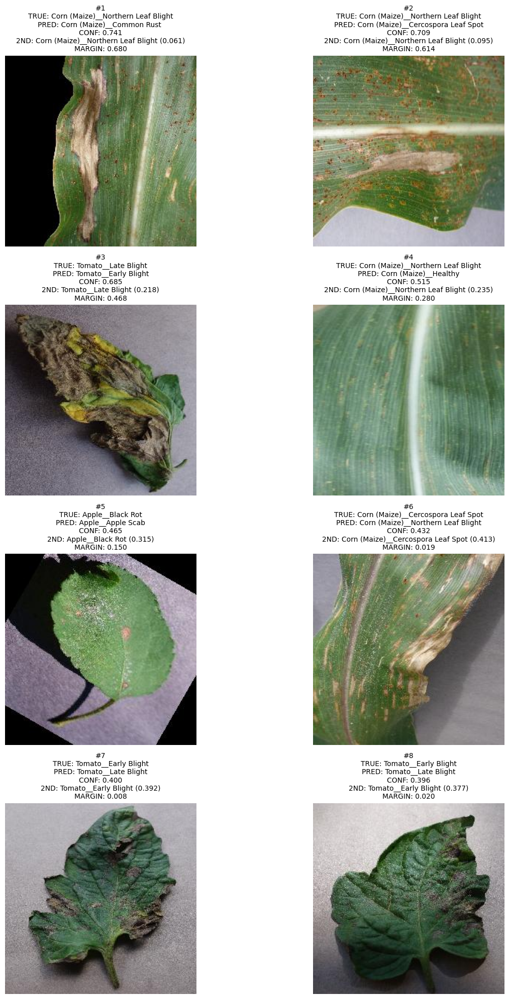


[1] Error images displayed: 8

[2] Error paths
------------------------------------------------------------
1. Corn (Maize)__Northern Leaf Blight → Corn (Maize)__Common Rust  | 0.741 | 8a936e9c-617d-4f4c-834a-6b4cb40db290___RS_NLB 3660.JPG
2. Corn (Maize)__Northern Leaf Blight → Corn (Maize)__Cercospora Leaf Spot | 0.709 | acfc653f-44e2-41f6-85cd-3595a6fd7455___RS_NLB 3840_flipTB.JPG
3. Tomato__Late Blight → Tomato__Early Blight | 0.685 | c91400cf-83f0-4472-9504-3234ccecf65c___RS_Late.B 5218.JPG
4. Corn (Maize)__Northern Leaf Blight → Corn (Maize)__Healthy | 0.515 | c4eb96b2-1345-46d0-a796-161042da21df___RS_NLB 0824 copy_flipTB.jpg
5. Apple__Black Rot → Apple__Apple Scab | 0.465 | b157d655-9533-4c1d-a9bc-8f6351b06306___JR_FrgE.S 3087_new30degFlipLR.JPG
6. Corn (Maize)__Cercospora Leaf Spot → Corn (Maize)__Northern Leaf Blight | 0.432 | b9a39437-94b7-41e3-b309-080e9a93d5ca___RS_GLSp 4440.JPG
7. Tomato__Early Blight → Tomato__Late Blight | 0.400 | 60b089ee-97ea-4df8-bb95-cd8c2094b24e___

In [ ]:
# ======================================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 25
# Visual Inspection of Remaining MLP Errors
# ======================================================================

import os
import math
import matplotlib.pyplot as plt
from PIL import Image

print("=" * 70)
print("CLIP PLANT DISEASE EXPERIMENT — CELL 25")
print("Visual Inspection of Remaining MLP Errors")
print("=" * 70)

assert "errors_df" in globals()
assert len(errors_df) == 8

# ----------------------------------------------------------------------
# 1. Display configuration
# ----------------------------------------------------------------------

n_errors = len(errors_df)

cols = 2
rows = math.ceil(n_errors / cols)

fig, axes = plt.subplots(
    rows,
    cols,
    figsize=(14, 5 * rows)
)

axes = axes.flatten()

# ----------------------------------------------------------------------
# 2. Display each error
# ----------------------------------------------------------------------

for plot_idx, row in errors_df.iterrows():

    ax = axes[plot_idx]

    path = row["path"]

    image = Image.open(
        path
    ).convert("RGB")

    ax.imshow(image)

    ax.axis("off")

    title = (
        f"#{plot_idx + 1}\n"
        f"TRUE: {row['true_class']}\n"
        f"PRED: {row['predicted_class']}\n"
        f"CONF: {row['confidence']:.3f}\n"
        f"2ND: {row['second_class']} "
        f"({row['second_probability']:.3f})\n"
        f"MARGIN: {row['margin']:.3f}"
    )

    ax.set_title(
        title,
        fontsize=10
    )

# Hide unused axes
for idx in range(n_errors, len(axes)):
    axes[idx].axis("off")

plt.tight_layout()
plt.show()

print("\n[1] Error images displayed:", n_errors)

print("\n[2] Error paths")
print("-" * 60)

for i, row in errors_df.iterrows():

    print(
        f"{i + 1}. "
        f"{row['true_class']} → "
        f"{row['predicted_class']} | "
        f"{row['confidence']:.3f} | "
        f"{os.path.basename(row['path'])}"
    )

print("\n" + "=" * 70)
print("CELL-25 COMPLETE")
print("=" * 70)

**Cell 26 — inspect the 8 residual errors quantitatively**

In [ ]:
# ============================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 26 (FIXED)
# Residual Error Embedding-Space Analysis
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F

print("=" * 70)
print("CELL 26 — RESIDUAL ERROR EMBEDDING-SPACE ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify required objects
# ------------------------------------------------------------
required = ["test_embeddings", "errors_df", "manifest_df"]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(f"Missing required runtime objects: {missing}")

print("\n[1] Runtime objects verified")
print(f"  test_embeddings: {tuple(test_embeddings.shape)}")
print(f"  errors_df:       {len(errors_df)} rows")
print(f"  manifest_df:     {len(manifest_df)} rows")

# ------------------------------------------------------------
# 2. Exact test manifest
# ------------------------------------------------------------
test_manifest = (
    manifest_df[manifest_df["split"] == "Test"]
    .reset_index(drop=True)
    .copy()
)

assert len(test_manifest) == len(test_embeddings) == 1354

labels = test_manifest["class_idx"].to_numpy()

# ------------------------------------------------------------
# 3. Class-name ↔ class-index mapping
# ------------------------------------------------------------
class_mapping = (
    test_manifest[["class_idx", "class_name"]]
    .drop_duplicates()
    .sort_values("class_idx")
)

class_to_idx = dict(
    zip(
        class_mapping["class_name"],
        class_mapping["class_idx"]
    )
)

idx_to_class = dict(
    zip(
        class_mapping["class_idx"],
        class_mapping["class_name"]
    )
)

print("\n[2] Class mapping verified")
print(f"  Classes: {len(class_to_idx)}")

# ------------------------------------------------------------
# 4. Inspect errors_df columns
# ------------------------------------------------------------
print("\n[3] errors_df columns")
print(list(errors_df.columns))

# ------------------------------------------------------------
# 5. Reconstruct predicted class index
# ------------------------------------------------------------
#
# Cell 24 stored predicted class information under a
# different column name. We reconstruct it from the
# predicted class name instead of assuming 'pred_idx'.
#
# This does NOT change predictions or retrain anything.
# ------------------------------------------------------------

possible_pred_columns = [
    "pred_class",
    "predicted_class",
    "prediction",
    "pred"
]

pred_col = next(
    (c for c in possible_pred_columns if c in errors_df.columns),
    None
)

if pred_col is None:
    raise RuntimeError(
        "Could not find predicted-class column in errors_df. "
        f"Available columns: {list(errors_df.columns)}"
    )

pred_names = errors_df[pred_col].astype(str).tolist()

pred_classes = np.array(
    [class_to_idx[name] for name in pred_names],
    dtype=np.int64
)

print(f"\n[4] Predicted class column detected: '{pred_col}'")

# ------------------------------------------------------------
# 6. Extract error embeddings
# ------------------------------------------------------------
error_indices = errors_df["test_index"].astype(int).to_numpy()

emb = test_embeddings.detach().cpu().float()
emb = F.normalize(emb, p=2, dim=1)

error_emb = emb[error_indices]

true_classes = labels[error_indices]

# ------------------------------------------------------------
# 7. Build class centroids
# ------------------------------------------------------------
num_classes = len(class_to_idx)

centroids = []

for c in range(num_classes):

    class_emb = emb[labels == c]

    centroid = class_emb.mean(
        dim=0,
        keepdim=True
    )

    centroid = F.normalize(
        centroid,
        p=2,
        dim=1
    )

    centroids.append(centroid.squeeze(0))

centroids = torch.stack(centroids)

print("\n[5] Class centroids")
print(f"  Shape: {tuple(centroids.shape)}")

# ------------------------------------------------------------
# 8. Similarity to every class centroid
# ------------------------------------------------------------
all_sim = error_emb @ centroids.T

true_centroids = centroids[true_classes]
pred_centroids = centroids[pred_classes]

true_sim = torch.sum(
    error_emb * true_centroids,
    dim=1
)

pred_sim = torch.sum(
    error_emb * pred_centroids,
    dim=1
)

# ------------------------------------------------------------
# 9. Analyze each residual error
# ------------------------------------------------------------
rows = []

for i in range(len(error_indices)):

    sims = all_sim[i]

    true_idx = int(true_classes[i])
    pred_idx = int(pred_classes[i])

    ranking = torch.argsort(
        sims,
        descending=True
    )

    true_rank = (
        int((sims > sims[true_idx]).sum().item()) + 1
    )

    pred_rank = (
        int((sims > sims[pred_idx]).sum().item()) + 1
    )

    nearest_idx = int(ranking[0])
    second_idx = int(ranking[1])

    rows.append({
        "test_index":
            int(error_indices[i]),

        "true_class":
            idx_to_class[true_idx],

        "pred_class":
            idx_to_class[pred_idx],

        "mlp_confidence":
            float(errors_df.iloc[i]["confidence"]),

        "true_centroid_similarity":
            float(true_sim[i]),

        "pred_centroid_similarity":
            float(pred_sim[i]),

        "pred_minus_true_similarity":
            float(pred_sim[i] - true_sim[i]),

        "true_centroid_rank":
            true_rank,

        "pred_centroid_rank":
            pred_rank,

        "nearest_centroid_class":
            idx_to_class[nearest_idx],

        "nearest_centroid_similarity":
            float(sims[nearest_idx]),

        "second_centroid_class":
            idx_to_class[second_idx],

        "second_centroid_similarity":
            float(sims[second_idx]),
    })

residual_analysis_df = pd.DataFrame(rows)

# ------------------------------------------------------------
# 10. Display
# ------------------------------------------------------------
pd.set_option(
    "display.max_colwidth",
    45
)

pd.set_option(
    "display.width",
    240
)

print("\n[6] Residual error centroid analysis")
print("-" * 70)

display(
    residual_analysis_df[
        [
            "test_index",
            "true_class",
            "pred_class",
            "mlp_confidence",
            "true_centroid_similarity",
            "pred_centroid_similarity",
            "pred_minus_true_similarity",
            "true_centroid_rank",
            "pred_centroid_rank",
            "nearest_centroid_class",
            "nearest_centroid_similarity",
        ]
    ]
    .sort_values(
        "mlp_confidence",
        ascending=False
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 11. Summary
# ------------------------------------------------------------
print("\n[7] Summary")
print("-" * 70)

pred_closer = (
    residual_analysis_df[
        "pred_minus_true_similarity"
    ] > 0
).sum()

true_nearest = (
    residual_analysis_df[
        "true_centroid_rank"
    ] == 1
).sum()

pred_nearest = (
    residual_analysis_df[
        "pred_centroid_rank"
    ] == 1
).sum()

print(
    f"Mean true-class centroid similarity: "
    f"{residual_analysis_df['true_centroid_similarity'].mean():.4f}"
)

print(
    f"Mean predicted-class centroid similarity: "
    f"{residual_analysis_df['pred_centroid_similarity'].mean():.4f}"
)

print(
    f"Predicted centroid closer than true centroid: "
    f"{pred_closer}/{len(residual_analysis_df)}"
)

print(
    f"True class is nearest centroid: "
    f"{true_nearest}/{len(residual_analysis_df)}"
)

print(
    f"Predicted class is nearest centroid: "
    f"{pred_nearest}/{len(residual_analysis_df)}"
)

print("\n" + "=" * 70)
print("CELL-26 COMPLETE")
print("=" * 70)

CELL 26 — RESIDUAL ERROR EMBEDDING-SPACE ANALYSIS

[1] Runtime objects verified
  test_embeddings: (1354, 512)
  errors_df:       8 rows
  manifest_df:     67111 rows

[2] Class mapping verified
  Classes: 29

[3] errors_df columns
['test_index', 'true_class', 'predicted_class', 'confidence', 'second_class', 'second_probability', 'margin', 'path']

[4] Predicted class column detected: 'predicted_class'

[5] Class centroids
  Shape: (29, 512)

[6] Residual error centroid analysis
----------------------------------------------------------------------


,test_index,true_class,pred_class,mlp_confidence,true_centroid_similarity,pred_centroid_similarity,pred_minus_true_similarity,true_centroid_rank,pred_centroid_rank,nearest_centroid_class,nearest_centroid_similarity
0,535,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Common Rust,0.740953,0.942049,0.907557,-0.034492,1,3,Corn (Maize)__Northern Leaf Blight,0.942049
1,541,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Cercospora Leaf Spot,0.709104,0.957870,0.940555,-0.017315,1,2,Corn (Maize)__Northern Leaf Blight,0.957870
2,1250,Tomato__Late Blight,Tomato__Early Blight,0.685408,0.908927,0.891432,-0.017495,1,2,Tomato__Late Blight,0.908927
3,546,Corn (Maize)__Northern Leaf Blight,Corn (Maize)__Healthy,0.515478,0.928991,0.960436,0.031444,2,1,Corn (Maize)__Healthy,0.960436
4,78,Apple__Black Rot,Apple__Apple Scab,0.465441,0.934753,0.928643,-0.006110,1,2,Apple__Black Rot,0.934753
5,407,Corn (Maize)__Cercospora Leaf Spot,Corn (Maize)__Northern Leaf Blight,0.432352,0.895410,0.853397,-0.042013,1,3,Corn (Maize)__Cercospora Leaf Spot,0.895410
6,1125,Tomato__Early Blight,Tomato__Late Blight,0.400197,0.961643,0.949408,-0.012235,3,4,Tomato__Bacterial Spot,0.969046
7,1135,Tomato__Early Blight,Tomato__Late Blight,0.396132,0.964706,0.951208,-0.013498,1,6,Tomato__Early Blight,0.964706



[7] Summary
----------------------------------------------------------------------
Mean true-class centroid similarity: 0.9368
Mean predicted-class centroid similarity: 0.9228
Predicted centroid closer than true centroid: 1/8
True class is nearest centroid: 6/8
Predicted class is nearest centroid: 1/8

CELL-26 COMPLETE


**Cell 27 — Stronger MLP with residual-style architecture**

In [ ]:
# ============================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 27
# Stronger Nonlinear Classifier on Frozen CLIP Embeddings
# ============================================================

import copy
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

print("=" * 70)
print("CELL 27 — STRONGER MLP ON FROZEN CLIP EMBEDDINGS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify existing embeddings
# ------------------------------------------------------------

required = [
    "train_embeddings",
    "val_embeddings",
    "test_embeddings",
    "train_labels",
    "val_labels",
    "test_labels"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(f"Missing required objects: {missing}")

print("\n[1] Existing embeddings verified")

print(f"  Train: {tuple(train_embeddings.shape)}")
print(f"  Val:   {tuple(val_embeddings.shape)}")
print(f"  Test:  {tuple(test_embeddings.shape)}")

# ------------------------------------------------------------
# 2. Device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print(f"\n[2] Device: {device}")

# ------------------------------------------------------------
# 3. Stronger MLP architecture
# ------------------------------------------------------------

class StrongCLIPMLP(nn.Module):

    def __init__(
        self,
        input_dim=512,
        hidden1=512,
        hidden2=256,
        num_classes=29,
        dropout=0.20
    ):
        super().__init__()

        self.network = nn.Sequential(

            nn.Linear(input_dim, hidden1),
            nn.LayerNorm(hidden1),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(hidden1, hidden2),
            nn.LayerNorm(hidden2),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(hidden2, num_classes)
        )

    def forward(self, x):
        return self.network(x)


strong_mlp = StrongCLIPMLP().to(device)

# ------------------------------------------------------------
# 4. Parameter verification
# ------------------------------------------------------------

trainable_params = sum(
    p.numel()
    for p in strong_mlp.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in strong_mlp.parameters()
)

print("\n[3] Strong MLP")
print(f"  Total parameters:     {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")

# ------------------------------------------------------------
# 5. DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 256

train_ds = TensorDataset(
    train_embeddings.float(),
    train_labels.long()
)

val_ds = TensorDataset(
    val_embeddings.float(),
    val_labels.long()
)

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("\n[4] DataLoaders ready")
print(f"  Batch size: {BATCH_SIZE}")
print(f"  Train batches: {len(train_loader)}")
print(f"  Val batches:   {len(val_loader)}")

# ------------------------------------------------------------
# 6. Training configuration
# ------------------------------------------------------------

EPOCHS = 30
LR = 1e-3
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

optimizer = torch.optim.AdamW(
    strong_mlp.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

print("\n[5] Training configuration")
print(f"  Epochs:          {EPOCHS}")
print(f"  Learning rate:   {LR}")
print(f"  Weight decay:    {WEIGHT_DECAY}")
print(f"  Label smoothing: {LABEL_SMOOTHING}")

# ------------------------------------------------------------
# 7. Training
# ------------------------------------------------------------

history_strong = []

best_val_acc_strong = -1.0
best_epoch_strong = None
best_state_strong = None

training_start = time.time()

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    # -------------------------
    # Train
    # -------------------------

    strong_mlp.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for xb, yb in train_loader:

        xb = xb.to(
            device,
            non_blocking=True
        )

        yb = yb.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        logits = strong_mlp(xb)

        loss = criterion(
            logits,
            yb
        )

        loss.backward()

        optimizer.step()

        train_loss_sum += (
            loss.item() * xb.size(0)
        )

        train_correct += (
            logits.argmax(dim=1) == yb
        ).sum().item()

        train_total += xb.size(0)

    train_loss = (
        train_loss_sum / train_total
    )

    train_acc = (
        100.0 * train_correct / train_total
    )

    # -------------------------
    # Validation
    # -------------------------

    strong_mlp.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for xb, yb in val_loader:

            xb = xb.to(
                device,
                non_blocking=True
            )

            yb = yb.to(
                device,
                non_blocking=True
            )

            logits = strong_mlp(xb)

            loss = criterion(
                logits,
                yb
            )

            val_loss_sum += (
                loss.item() * xb.size(0)
            )

            val_correct += (
                logits.argmax(dim=1) == yb
            ).sum().item()

            val_total += xb.size(0)

    val_loss = (
        val_loss_sum / val_total
    )

    val_acc = (
        100.0 * val_correct / val_total
    )

    epoch_time = time.time() - epoch_start

    history_strong.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "time_sec": epoch_time
    })

    # -------------------------
    # Best checkpoint
    # -------------------------

    if val_acc > best_val_acc_strong:

        best_val_acc_strong = val_acc
        best_epoch_strong = epoch

        best_state_strong = copy.deepcopy(
            strong_mlp.state_dict()
        )

    print(
        f"Epoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.3f}% | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.3f}% | "
        f"{epoch_time:.1f}s"
    )

# ------------------------------------------------------------
# 8. Restore best validation checkpoint
# ------------------------------------------------------------

strong_mlp.load_state_dict(
    best_state_strong
)

total_time_strong = (
    time.time() - training_start
)

print("\n[6] Training complete")
print(
    f"  Best validation accuracy: "
    f"{best_val_acc_strong:.4f}%"
)

print(
    f"  Best epoch: {best_epoch_strong}"
)

print(
    f"  Total training time: "
    f"{total_time_strong:.1f}s "
    f"({total_time_strong/60:.2f} min)"
)

print("\n" + "=" * 70)
print("CELL-27 COMPLETE")
print("=" * 70)

CELL 27 — STRONGER MLP ON FROZEN CLIP EMBEDDINGS

[1] Existing embeddings verified
  Train: (53690, 512)
  Val:   (12067, 512)
  Test:  (1354, 512)

[2] Device: cuda

[3] Strong MLP
  Total parameters:     402,973
  Trainable parameters: 402,973

[4] DataLoaders ready
  Batch size: 256
  Train batches: 210
  Val batches:   48

[5] Training configuration
  Epochs:          30
  Learning rate:   0.001
  Weight decay:    0.0001
  Label smoothing: 0.1
Epoch 01/30 | Train Loss 1.0296 | Train Acc 90.052% | Val Loss 0.7557 | Val Acc 97.381% | 2.4s
Epoch 02/30 | Train Loss 0.7452 | Train Acc 98.078% | Val Loss 0.7173 | Val Acc 98.235% | 1.8s
Epoch 03/30 | Train Loss 0.7206 | Train Acc 98.629% | Val Loss 0.6980 | Val Acc 98.906% | 1.7s
Epoch 04/30 | Train Loss 0.7048 | Train Acc 98.983% | Val Loss 0.6978 | Val Acc 98.633% | 1.5s
Epoch 05/30 | Train Loss 0.6988 | Train Acc 99.084% | Val Loss 0.6899 | Val Acc 98.881% | 1.6s
Epoch 06/30 | Train Loss 0.6896 | Train Acc 99.307% | Val Loss 0.6883 | V

**Cell 28 — evaluate stronger MLP on the untouched test set**

In [ ]:
# ============================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 28
# Test Evaluation of Stronger MLP
# ============================================================

import numpy as np
import torch
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix
)

print("=" * 70)
print("CELL 28 — STRONGER MLP TEST EVALUATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify checkpoint and test data
# ------------------------------------------------------------

required = [
    "strong_mlp",
    "test_embeddings",
    "test_labels",
    "best_epoch_strong",
    "best_val_acc_strong"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("\n[1] Runtime verified")
print(f"  Test samples: {len(test_labels)}")
print(f"  Best epoch: {best_epoch_strong}")
print(f"  Best validation accuracy: {best_val_acc_strong:.4f}%")

# ------------------------------------------------------------
# 2. Test inference
# ------------------------------------------------------------

device = next(
    strong_mlp.parameters()
).device

strong_mlp.eval()

test_x = test_embeddings.float().to(device)
test_y = test_labels.long().to(device)

with torch.inference_mode():

    test_logits = strong_mlp(test_x)

    test_probs = torch.softmax(
        test_logits,
        dim=1
    )

    test_pred = test_logits.argmax(
        dim=1
    )

# ------------------------------------------------------------
# 3. Convert to CPU / NumPy
# ------------------------------------------------------------

y_true = test_y.cpu().numpy()
y_pred = test_pred.cpu().numpy()
probs = test_probs.cpu().numpy()

# ------------------------------------------------------------
# 4. Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_true,
    y_pred
)

precision_macro, recall_macro, f1_macro, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )
)

precision_weighted, recall_weighted, f1_weighted, _ = (
    precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )
)

cm = confusion_matrix(
    y_true,
    y_pred
)

correct = int(
    (y_true == y_pred).sum()
)

incorrect = int(
    (y_true != y_pred).sum()
)

# ------------------------------------------------------------
# 5. Output
# ------------------------------------------------------------

print("\n[2] Held-out test results")
print("-" * 70)

print(
    f"Test accuracy:       {accuracy * 100:.4f}%"
)

print(
    f"Macro precision:     {precision_macro * 100:.4f}%"
)

print(
    f"Macro recall:        {recall_macro * 100:.4f}%"
)

print(
    f"Macro F1:            {f1_macro * 100:.4f}%"
)

print(
    f"Weighted precision:  {precision_weighted * 100:.4f}%"
)

print(
    f"Weighted recall:     {recall_weighted * 100:.4f}%"
)

print(
    f"Weighted F1:         {f1_weighted * 100:.4f}%"
)

print(f"\nCorrect:   {correct}")
print(f"Incorrect: {incorrect}")

print(
    f"\nProbability shape: {probs.shape}"
)

print(
    f"Probability row-sum range: "
    f"{probs.sum(axis=1).min():.6f} → "
    f"{probs.sum(axis=1).max():.6f}"
)

# ------------------------------------------------------------
# 6. Comparison with previous MLP
# ------------------------------------------------------------

previous_acc = 99.41
previous_errors = 8

new_errors = incorrect

print("\n[3] Comparison with 139K-parameter MLP")
print("-" * 70)

print(
    f"Previous test accuracy: "
    f"{previous_acc:.4f}%"
)

print(
    f"Stronger MLP accuracy:  "
    f"{accuracy * 100:.4f}%"
)

print(
    f"Accuracy difference:     "
    f"{accuracy * 100 - previous_acc:+.4f} pp"
)

print(
    f"Previous errors:         {previous_errors}"
)

print(
    f"Stronger MLP errors:     {new_errors}"
)

# ------------------------------------------------------------
# 7. Integrity checks
# ------------------------------------------------------------

assert len(y_true) == 1354
assert len(y_pred) == 1354
assert probs.shape == (1354, 29)

assert np.allclose(
    probs.sum(axis=1),
    1.0,
    atol=1e-5
)

print("\n[4] Integrity checks: PASSED")

print("\n" + "=" * 70)
print("CELL-28 COMPLETE")
print("=" * 70)

CELL 28 — STRONGER MLP TEST EVALUATION

[1] Runtime verified
  Test samples: 1354
  Best epoch: 14
  Best validation accuracy: 99.4282%

[2] Held-out test results
----------------------------------------------------------------------
Test accuracy:       99.3353%
Macro precision:     99.3350%
Macro recall:        99.3317%
Macro F1:            99.3303%
Weighted precision:  99.3365%
Weighted recall:     99.3353%
Weighted F1:         99.3328%

Correct:   1345
Incorrect: 9

Probability shape: (1354, 29)
Probability row-sum range: 1.000000 → 1.000000

[3] Comparison with 139K-parameter MLP
----------------------------------------------------------------------
Previous test accuracy: 99.4100%
Stronger MLP accuracy:  99.3353%
Accuracy difference:     -0.0747 pp
Previous errors:         8
Stronger MLP errors:     9

[4] Integrity checks: PASSED

CELL-28 COMPLETE


**Cell 29 — prepare controlled CLIP projection adaptation**

In [ ]:
# ============================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 29 FIX
# Rebuild Exact Image DataLoaders for CLIP Adaptation
# ============================================================

import os
import torch
from PIL import Image
from torch.utils.data import Dataset, DataLoader

print("=" * 70)
print("CELL 29 FIX — REBUILD IMAGE DATALOADERS")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify required objects
# ------------------------------------------------------------

required = [
    "model",
    "projection_mlp",
    "manifest_df",
    "processor"
]

missing = [x for x in required if x not in globals()]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

print("\n[1] Required objects verified")

# ------------------------------------------------------------
# 2. Exact split manifests
# ------------------------------------------------------------

train_manifest_img = (
    manifest_df[
        manifest_df["split"] == "Train"
    ]
    .reset_index(drop=True)
    .copy()
)

val_manifest_img = (
    manifest_df[
        manifest_df["split"] == "Val"
    ]
    .reset_index(drop=True)
    .copy()
)

test_manifest_img = (
    manifest_df[
        manifest_df["split"] == "Test"
    ]
    .reset_index(drop=True)
    .copy()
)

print("\n[2] Exact split sizes")
print(f"  Train: {len(train_manifest_img)}")
print(f"  Val:   {len(val_manifest_img)}")
print(f"  Test:  {len(test_manifest_img)}")

assert len(train_manifest_img) == 53690
assert len(val_manifest_img) == 12067
assert len(test_manifest_img) == 1354

# ------------------------------------------------------------
# 3. Image Dataset
# ------------------------------------------------------------

class CLIPPlantDataset(Dataset):

    def __init__(
        self,
        dataframe,
        processor
    ):
        self.df = dataframe.reset_index(drop=True)
        self.processor = processor

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_path = row["path"]
        label = int(row["class_idx"])

        image = Image.open(
            image_path
        ).convert("RGB")

        processed = self.processor(
            images=image,
            return_tensors="pt"
        )

        pixel_values = processed[
            "pixel_values"
        ].squeeze(0)

        return pixel_values, label


# ------------------------------------------------------------
# 4. Create datasets
# ------------------------------------------------------------

train_image_dataset = CLIPPlantDataset(
    train_manifest_img,
    processor
)

val_image_dataset = CLIPPlantDataset(
    val_manifest_img,
    processor
)

print("\n[3] Image datasets created")

# ------------------------------------------------------------
# 5. Create dedicated image DataLoaders
# ------------------------------------------------------------

IMAGE_BATCH_SIZE = 32

train_image_loader = DataLoader(
    train_image_dataset,
    batch_size=IMAGE_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

val_image_loader = DataLoader(
    val_image_dataset,
    batch_size=IMAGE_BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
    persistent_workers=True
)

print("\n[4] Image DataLoaders created")
print(f"  Batch size: {IMAGE_BATCH_SIZE}")
print(f"  Train batches: {len(train_image_loader)}")
print(f"  Val batches:   {len(val_image_loader)}")

# ------------------------------------------------------------
# 6. Verify one actual image batch
# ------------------------------------------------------------

pixel_values, labels = next(
    iter(train_image_loader)
)

print("\n[5] Batch verification")
print(f"  Pixel values: {tuple(pixel_values.shape)}")
print(f"  Labels:       {tuple(labels.shape)}")
print(f"  Pixel dtype:  {pixel_values.dtype}")
print(f"  Label dtype:  {labels.dtype}")

assert pixel_values.ndim == 4
assert pixel_values.shape[1:] == (3, 224, 224)
assert labels.ndim == 1
assert len(pixel_values) == len(labels)

# ------------------------------------------------------------
# 7. Verify CLIP-compatible range
# ------------------------------------------------------------

print(
    f"  Pixel min:    {pixel_values.min().item():.4f}"
)

print(
    f"  Pixel max:    {pixel_values.max().item():.4f}"
)

# ------------------------------------------------------------
# 8. Verify paths
# ------------------------------------------------------------

sample_path = train_manifest_img.iloc[0]["path"]

assert os.path.exists(sample_path)

print(
    f"\n[6] Sample image exists: {os.path.basename(sample_path)}"
)

# ------------------------------------------------------------
# 9. Important: use dedicated names
# ------------------------------------------------------------

print("\n[7] Loader naming")
print("  train_image_loader → IMAGE batches")
print("  val_image_loader   → IMAGE batches")
print("  Existing train_loader/val_loader may contain EMBEDDINGS")
print("  They will NOT be reused for CLIP adaptation.")

print("\n[8] Training status")
print("  No training performed")
print("  No weights changed")
print("  Test set not used")

print("\n" + "=" * 70)
print("CELL-29 FIX COMPLETE")
print("=" * 70)

CELL 29 FIX — REBUILD IMAGE DATALOADERS

[1] Required objects verified

[2] Exact split sizes
  Train: 53690
  Val:   12067
  Test:  1354

[3] Image datasets created

[4] Image DataLoaders created
  Batch size: 32
  Train batches: 1678
  Val batches:   378

[5] Batch verification
  Pixel values: (32, 3, 224, 224)
  Labels:       (32,)
  Pixel dtype:  torch.float32
  Label dtype:  torch.int64
  Pixel min:    -1.7923
  Pixel max:    2.1459

[6] Sample image exists: 00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG

[7] Loader naming
  train_image_loader → IMAGE batches
  val_image_loader   → IMAGE batches
  Existing train_loader/val_loader may contain EMBEDDINGS
  They will NOT be reused for CLIP adaptation.

[8] Training status
  No training performed
  No weights changed
  Test set not used

CELL-29 FIX COMPLETE


**Cell 30 — Train projection + MLP**

In [ ]:
# ============================================================
# CLIP PLANT DISEASE EXPERIMENT — CELL 30
# Trainable: CLIP Visual Projection + MLP
# Frozen: CLIP Vision Encoder
# ============================================================

import copy
import time
import torch
import torch.nn as nn
import torch.nn.functional as F

print("=" * 70)
print("CELL 30 — TRAIN CLIP PROJECTION + MLP")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verify required objects
# ------------------------------------------------------------

required = [
    "model",
    "projection_mlp",
    "train_image_loader",
    "val_image_loader"
]

missing = [
    x for x in required
    if x not in globals()
]

if missing:
    raise RuntimeError(
        f"Missing required objects: {missing}"
    )

# ------------------------------------------------------------
# 2. Device
# ------------------------------------------------------------

device = next(
    model.parameters()
).device

projection_mlp = projection_mlp.to(device)

print("\n[1] Device")
print(f"  {device}")

# ------------------------------------------------------------
# 3. Re-establish parameter freezing
# ------------------------------------------------------------

# Freeze everything first
for param in model.parameters():
    param.requires_grad = False

# Only visual projection is trainable
for param in model.visual_projection.parameters():
    param.requires_grad = True

# MLP fully trainable
for param in projection_mlp.parameters():
    param.requires_grad = True

# ------------------------------------------------------------
# 4. Parameter verification
# ------------------------------------------------------------

vision_trainable = sum(
    p.numel()
    for p in model.vision_model.parameters()
    if p.requires_grad
)

projection_trainable = sum(
    p.numel()
    for p in model.visual_projection.parameters()
    if p.requires_grad
)

mlp_trainable = sum(
    p.numel()
    for p in projection_mlp.parameters()
    if p.requires_grad
)

total_trainable = (
    projection_trainable +
    mlp_trainable
)

print("\n[2] Trainable parameters")
print(
    f"  Vision encoder:     {vision_trainable:,}"
)

print(
    f"  Visual projection:  {projection_trainable:,}"
)

print(
    f"  MLP:                {mlp_trainable:,}"
)

print(
    f"  TOTAL:              {total_trainable:,}"
)

assert vision_trainable == 0
assert projection_trainable == 393216
assert mlp_trainable == 139293

# ------------------------------------------------------------
# 5. Optimizer / loss
# ------------------------------------------------------------

EPOCHS = 5
LR = 1e-4
WEIGHT_DECAY = 1e-4
LABEL_SMOOTHING = 0.1

trainable_parameters = [
    p
    for p in list(model.visual_projection.parameters())
    + list(projection_mlp.parameters())
    if p.requires_grad
]

optimizer = torch.optim.AdamW(
    trainable_parameters,
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

criterion = nn.CrossEntropyLoss(
    label_smoothing=LABEL_SMOOTHING
)

print("\n[3] Training configuration")
print(f"  Epochs:          {EPOCHS}")
print(f"  Learning rate:   {LR}")
print(f"  Weight decay:    {WEIGHT_DECAY}")
print(f"  Label smoothing: {LABEL_SMOOTHING}")
print(f"  Train batches:   {len(train_image_loader)}")
print(f"  Val batches:     {len(val_image_loader)}")

# ------------------------------------------------------------
# 6. AMP
# ------------------------------------------------------------

use_amp = device.type == "cuda"

if use_amp:
    scaler = torch.amp.GradScaler("cuda")

print(
    f"\n[4] Mixed precision: "
    f"{'ENABLED' if use_amp else 'DISABLED'}"
)

# ------------------------------------------------------------
# 7. Forward helper
# ------------------------------------------------------------

def adapted_clip_forward(pixel_values):

    # Vision encoder is frozen.
    #
    # Since all its parameters have requires_grad=False,
    # autograd does not need to construct parameter gradients.
    #
    # We still need the output tensor to remain connected
    # to the trainable visual projection.

    vision_output = model.vision_model(
        pixel_values=pixel_values
    )

    pooled = vision_output.pooler_output

    image_embeds = model.visual_projection(
        pooled
    )

    image_embeds = F.normalize(
        image_embeds,
        p=2,
        dim=1
    )

    logits = projection_mlp(
        image_embeds
    )

    return logits

# ------------------------------------------------------------
# 8. Training loop
# ------------------------------------------------------------

history_projection = []

best_val_acc_projection = -1.0
best_epoch_projection = None
best_state_projection = None
best_state_mlp_projection = None

training_start = time.time()

for epoch in range(1, EPOCHS + 1):

    epoch_start = time.time()

    # ========================================================
    # TRAIN
    # ========================================================

    model.eval()
    projection_mlp.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for batch_idx, (pixel_values, labels) in enumerate(
        train_image_loader,
        start=1
    ):

        pixel_values = pixel_values.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        if use_amp:

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                logits = adapted_clip_forward(
                    pixel_values
                )

                loss = criterion(
                    logits,
                    labels
                )

            scaler.scale(loss).backward()

            scaler.step(
                optimizer
            )

            scaler.update()

        else:

            logits = adapted_clip_forward(
                pixel_values
            )

            loss = criterion(
                logits,
                labels
            )

            loss.backward()

            optimizer.step()

        train_loss_sum += (
            loss.item() *
            pixel_values.size(0)
        )

        train_correct += (
            logits.argmax(dim=1) == labels
        ).sum().item()

        train_total += pixel_values.size(0)

        if (
            batch_idx == 1
            or batch_idx % 200 == 0
            or batch_idx == len(train_image_loader)
        ):

            print(
                f"  Epoch {epoch} | "
                f"Batch {batch_idx}/"
                f"{len(train_image_loader)} | "
                f"Loss {loss.item():.4f}"
            )

    train_loss = (
        train_loss_sum /
        train_total
    )

    train_acc = (
        100.0 *
        train_correct /
        train_total
    )

    # ========================================================
    # VALIDATION
    # ========================================================

    model.eval()
    projection_mlp.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():

        for pixel_values, labels in val_image_loader:

            pixel_values = pixel_values.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            logits = adapted_clip_forward(
                pixel_values
            )

            loss = criterion(
                logits,
                labels
            )

            val_loss_sum += (
                loss.item() *
                pixel_values.size(0)
            )

            val_correct += (
                logits.argmax(dim=1) == labels
            ).sum().item()

            val_total += pixel_values.size(0)

    val_loss = (
        val_loss_sum /
        val_total
    )

    val_acc = (
        100.0 *
        val_correct /
        val_total
    )

    epoch_time = (
        time.time() -
        epoch_start
    )

    history_projection.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "train_acc": train_acc,
        "val_loss": val_loss,
        "val_acc": val_acc,
        "time_sec": epoch_time
    })

    # --------------------------------------------------------
    # Best checkpoint
    # --------------------------------------------------------

    if val_acc > best_val_acc_projection:

        best_val_acc_projection = val_acc
        best_epoch_projection = epoch

        best_state_projection = copy.deepcopy(
            model.visual_projection.state_dict()
        )

        best_state_mlp_projection = copy.deepcopy(
            projection_mlp.state_dict()
        )

    print(
        f"\nEpoch {epoch:02d}/{EPOCHS} | "
        f"Train Loss {train_loss:.4f} | "
        f"Train Acc {train_acc:.3f}% | "
        f"Val Loss {val_loss:.4f} | "
        f"Val Acc {val_acc:.3f}% | "
        f"Time {epoch_time:.1f}s"
    )

    print("-" * 70)

# ------------------------------------------------------------
# 9. Restore best validation checkpoint
# ------------------------------------------------------------

model.visual_projection.load_state_dict(
    best_state_projection
)

projection_mlp.load_state_dict(
    best_state_mlp_projection
)

total_training_time = (
    time.time() -
    training_start
)

# ------------------------------------------------------------
# 10. Final status
# ------------------------------------------------------------

print("\n[5] Training complete")
print(
    f"  Best validation accuracy: "
    f"{best_val_acc_projection:.4f}%"
)

print(
    f"  Best epoch: "
    f"{best_epoch_projection}"
)

print(
    f"  Total training time: "
    f"{total_training_time:.1f}s "
    f"({total_training_time / 60:.2f} min)"
)

print("\n[6] Final trainable parameters")

print(
    f"  Vision encoder: "
    f"{sum(p.numel() for p in model.vision_model.parameters() if p.requires_grad):,}"
)

print(
    f"  Visual projection: "
    f"{sum(p.numel() for p in model.visual_projection.parameters() if p.requires_grad):,}"
)

print(
    f"  MLP: "
    f"{sum(p.numel() for p in projection_mlp.parameters() if p.requires_grad):,}"
)

print("\n" + "=" * 70)
print("CELL-30 COMPLETE")
print("=" * 70)

CELL 30 — TRAIN CLIP PROJECTION + MLP

[1] Device
  cuda:0

[2] Trainable parameters
  Vision encoder:     0
  Visual projection:  393,216
  MLP:                139,293
  TOTAL:              532,509

[3] Training configuration
  Epochs:          5
  Learning rate:   0.0001
  Weight decay:    0.0001
  Label smoothing: 0.1
  Train batches:   1678
  Val batches:     378

[4] Mixed precision: ENABLED
  Epoch 1 | Batch 1/1678 | Loss 3.4439
  Epoch 1 | Batch 200/1678 | Loss 1.2878
  Epoch 1 | Batch 400/1678 | Loss 0.9584
  Epoch 1 | Batch 600/1678 | Loss 0.9274
  Epoch 1 | Batch 800/1678 | Loss 0.7954
  Epoch 1 | Batch 1000/1678 | Loss 0.7781
  Epoch 1 | Batch 1200/1678 | Loss 0.7864
  Epoch 1 | Batch 1400/1678 | Loss 0.7997
  Epoch 1 | Batch 1600/1678 | Loss 0.7814
  Epoch 1 | Batch 1678/1678 | Loss 0.7936

Epoch 01/5 | Train Loss 0.9734 | Train Acc 93.557% | Val Loss 0.7705 | Val Acc 97.472% | Time 219.1s
----------------------------------------------------------------------
  Epoch 2 | Ba